194н: n=41 | 172н: n=4
Проверка годов 194н: [np.float64(2011.0), np.float64(2017.0), np.float64(2019.0), np.float64(2020.0), np.float64(2021.0), np.float64(2022.0), np.float64(2023.0), np.float64(2024.0), np.float64(2025.0)]
Проверка годов 172н: [np.float64(2012.0), np.float64(2025.0), np.float64(2026.0)]

1. ТП ↔ ПР после | n=41 | метод: не 2×2 | φ=nan | p=nan
I1_6   1
I2_1    
0     20
1     21

2. Оценка вреда ↔ Гл.18 | n=41 | метод: Fisher (n мал) | φ=nan | p=0.334
E1_gl18  0   1
G3_1          
0        3   3
1        9  26

3. Вред не устан. ↔ H3 | n=41 | метод: Fisher (n мал) | φ=nan | p=0.0
H3    0   1
G3_1       
0     6   0
1     7  28

4. Лечение ↔ Вред устан. | n=41 | метод: Fisher (n мал) | φ=nan | p=0.143
G4_1   0  3
K2         
0     28  3
1      7  3

1. ТП ↔ ПР после | n=4 | метод: не 2×2 | φ=nan | p=nan
I1_6  1
I2_1   
0     2
1     2

2. Оценка вреда ↔ Гл.18 | n=4 | метод: не 2×2 | φ=nan | p=nan
E1_gl18  0  1
G3_1         
1        2  2

3. Вред не устан. ↔ H3 | n=4 |

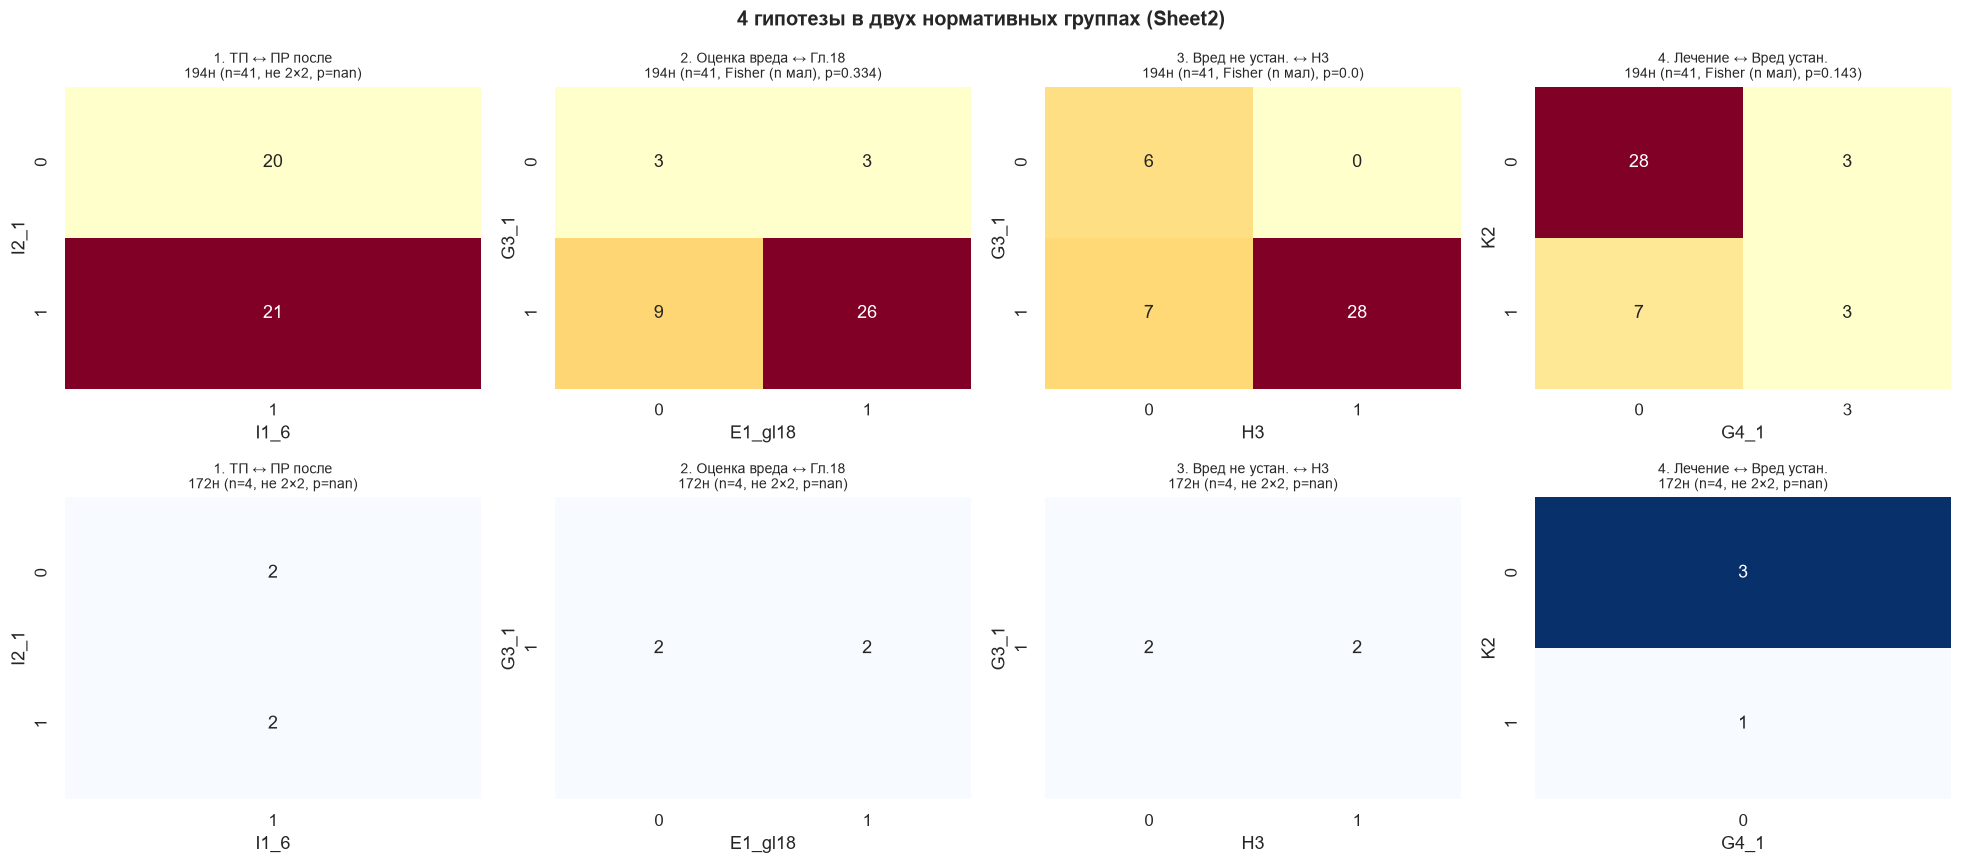

            Показатель     194н k/n   172н k/n  Δ п.п.
             ТП (I2.1)  21/41 (51%)  2/4 (50%)    -1.2
       ПР после (I1.6) 41/41 (100%) 4/4 (100%)     0.0
   G3.1 (оценка вреда)  35/41 (85%) 4/4 (100%)    14.6
G4.1 (вред установлен)  18/41 (44%)   0/4 (0%)   -43.9
         Глава 18 (E1)  29/41 (71%)  2/4 (50%)   -20.7
    H3 (нет обращения)  28/41 (68%)  2/4 (50%)   -18.3
          K2 (лечение)  10/41 (24%)  1/4 (25%)     0.6


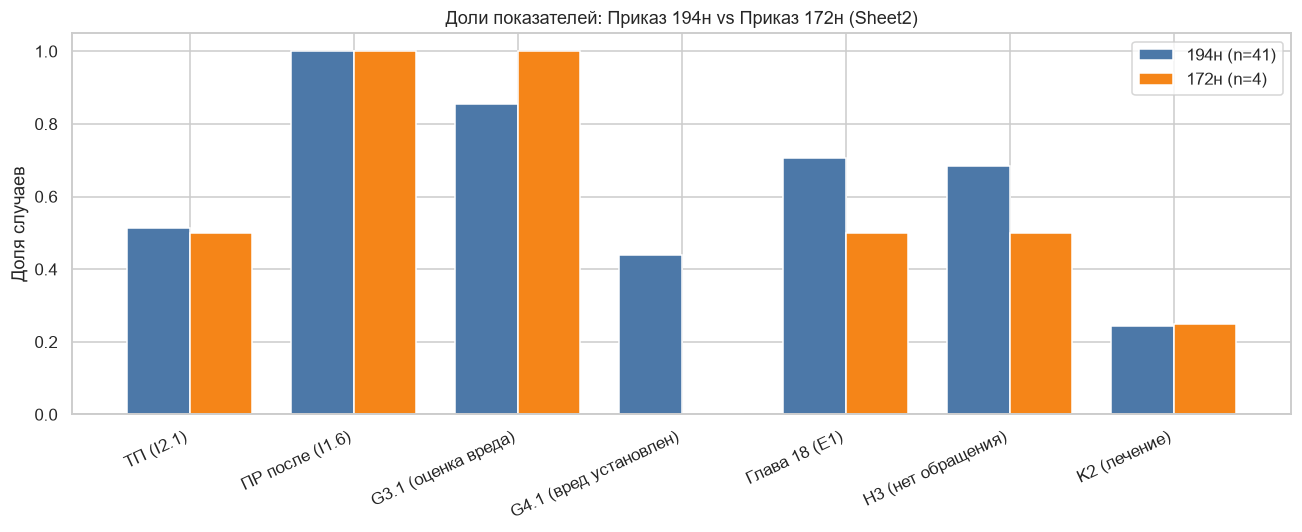

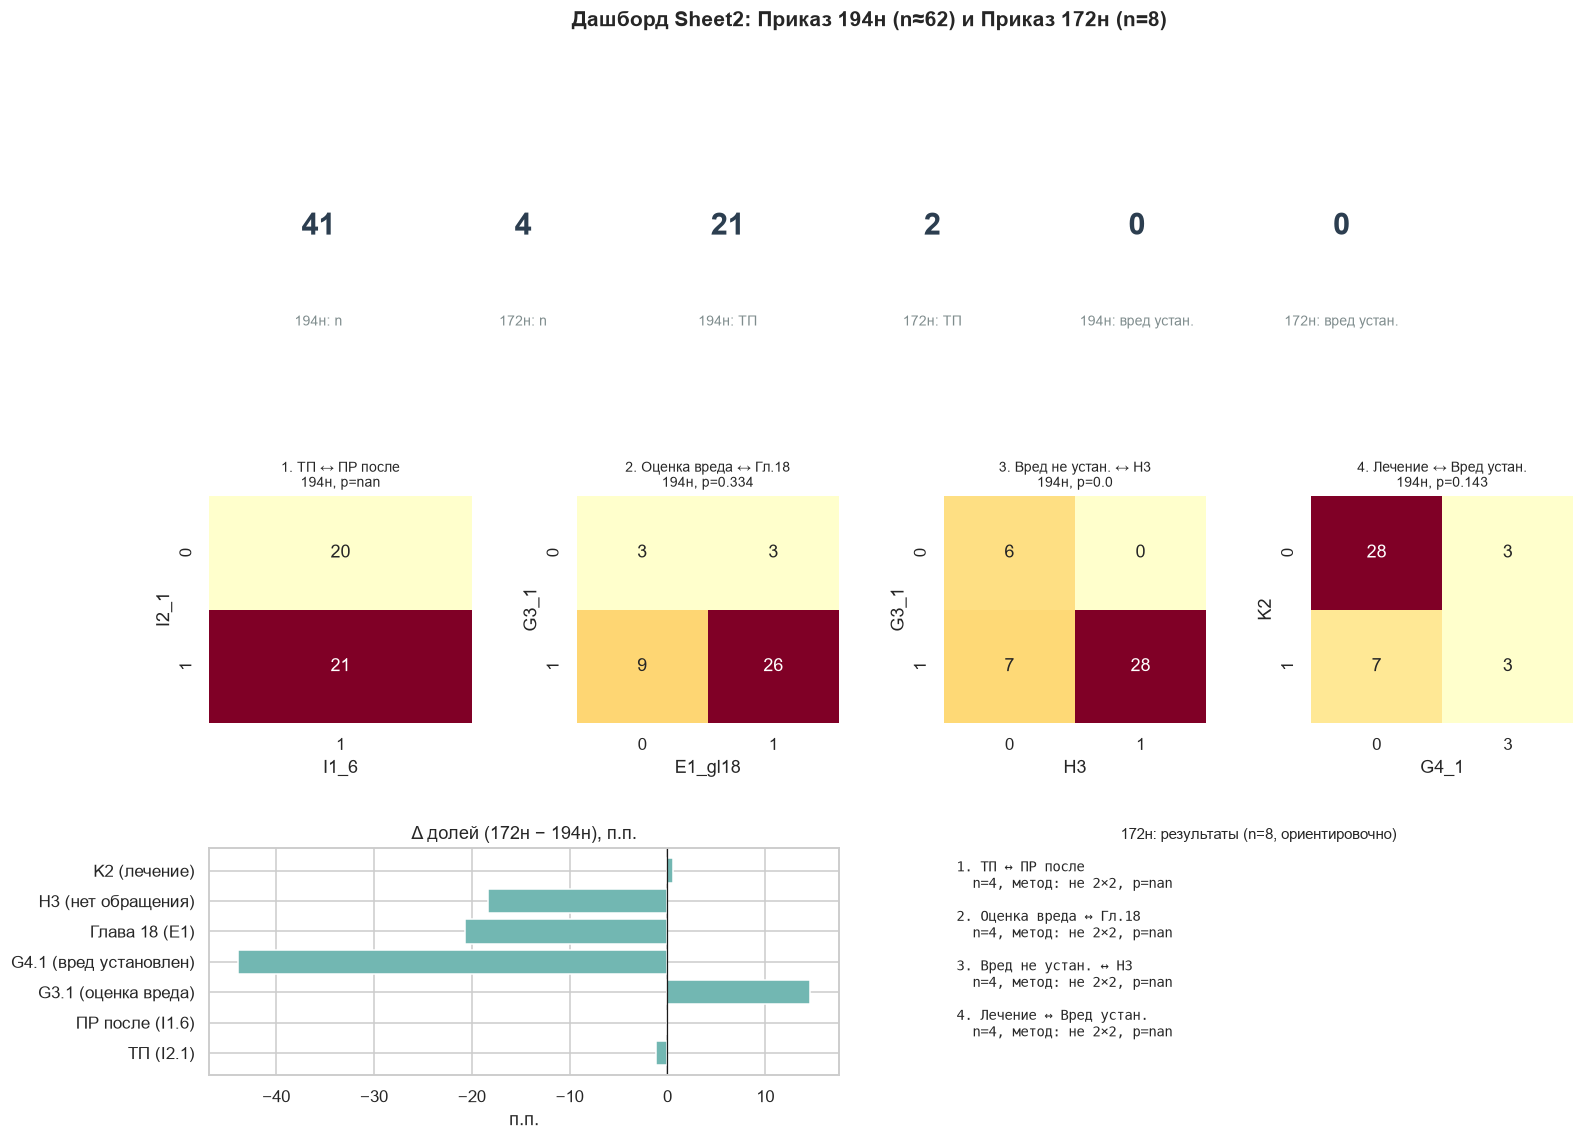

In [4]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, fisher_exact

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

path = "Таблица для статистики_редакция от 02.10.26.xlsx"
raw = pd.read_excel(path, sheet_name="Sheet2", header=None)

# Соответствие колонок (0-based iloc) — одинаково для обеих таблиц Sheet2
COLS = {
    "id":0,"day":1,"month":2,"year":3,
    "E1_gl18":14,"E2_gl16":15,"E3_other":16,
    "F1_PSS":17,"F2_PPSS":18,"F4_net_PSS":20,"F5_SPE_no":21,
    "G1_1":22,"G2_1":23,"G3_1":24,"G4_1":25,
    "H1":26,"H2":27,"H3":28,"H4":29,"H5":30,"H6":31,"H7":32,"H8":33,
    "I1_1":34,"I1_2":35,"I1_3":36,"I1_4":37,"I1_5":38,"I1_6":39,
    "I1_7":40,"I1_8":41,
    "I2_1":42,"I2_2":43,"I2_3":44,"I2_4":45,"I2_5":46,"I2_6":47,
    "J1":48,"J2":49,"J3":50,"K1":51,"K2":52,"K3":53,"K4":54,
}

def extract(df_raw, start, end):
    """Берём блок строк, оставляем только индивидуальные случаи (4-значный год)."""
    d = df_raw.iloc[start:end, list(COLS.values())].copy()
    d.columns = list(COLS.keys())
    d["year_num"] = pd.to_numeric(d["year"], errors="coerce")
    d = d[d["year_num"].between(2000, 2030)].reset_index(drop=True)
    for c in d.columns:
        if c not in ("id","day","month","year","year_num"):
            d[c] = pd.to_numeric(d[c], errors="coerce")
    return d

# Верхняя таблица Sheet2 (194н). В файле данные начинаются с iloc=5 (строка 6)
# и идут до строки 67 включительно -> end=67.
t194 = extract(raw, 5, 67)

# Нижняя таблица Sheet2 (172н). Данные — строки 78..85 -> iloc 77:85.
t172 = extract(raw, 77, 85)

print(f"194н: n={len(t194)} | 172н: n={len(t172)}")
print("Проверка годов 194н:", sorted(t194["year_num"].dropna().unique()))
print("Проверка годов 172н:", sorted(t172["year_num"].dropna().unique()))

#----------------------------------------------------------------------------------
#----------------------------------------------------------------------------------
#----------------------------------------------------------------------------------

def test_pair(df, c1, c2, name):
    x = df[c1].fillna(0).astype(int)
    y = df[c2].fillna(0).astype(int)
    ct = pd.crosstab(x, y)
    n = int(ct.values.sum())
    out = {"Гипотеза": name, "n": n, "table": ct}
    if ct.shape != (2, 2):
        out.update({"phi": np.nan, "p": np.nan, "method": "не 2×2"})
        return out
    expected = chi2_contingency(ct, correction=False)[3]
    if (expected < 5).any():
        # χ² невалиден — точный критерий Фишера
        odds, p = fisher_exact(ct.values)
        out.update({"phi": np.nan, "p": round(p, 3),
                    "method": "Fisher (n мал)"})
    else:
        chi2, p, _, _ = chi2_contingency(ct)
        out.update({"phi": round(np.sqrt(chi2 / n), 3),
                    "p": round(p, 3), "method": "χ²/φ"})
    return out

HYP = {
    "1. ТП ↔ ПР после":          ("I2_1", "I1_6"),
    "2. Оценка вреда ↔ Гл.18":   ("G3_1", "E1_gl18"),
    "3. Вред не устан. ↔ H3":    ("G3_1", "H3"),
    "4. Лечение ↔ Вред устан.":  ("K2",  "G4_1"),
}

#----------------------------------------------------------------------------------
#----------------------------------------------------------------------------------
#----------------------------------------------------------------------------------

res194 = {name: test_pair(t194, c1, c2, name) for name,(c1,c2) in HYP.items()}
for name, r in res194.items():
    print(f"\n{name} | n={r['n']} | метод: {r['method']} | φ={r['phi']} | p={r['p']}")
    print(r["table"])

#----------------------------------------------------------------------------------
#----------------------------------------------------------------------------------
#----------------------------------------------------------------------------------

res172 = {name: test_pair(t172, c1, c2, name) for name,(c1,c2) in HYP.items()}
for name, r in res172.items():
    print(f"\n{name} | n={r['n']} | метод: {r['method']} | φ={r['phi']} | p={r['p']}")
    print(r["table"])

#----------------------------------------------------------------------------------
#----------------------------------------------------------------------------------
#----------------------------------------------------------------------------------

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for j,(name,(c1,c2)) in enumerate(HYP.items()):
    # Верхний ряд — 194н
    r = res194[name]
    sns.heatmap(r["table"], annot=True, fmt="d", cbar=False,
                cmap="YlOrRd", ax=axes[0, j])
    axes[0, j].set_title(f"{name}\n194н (n={r['n']}, {r['method']}, p={r['p']})",
                         fontsize=9)
    # Нижний ряд — 172н
    r = res172[name]
    sns.heatmap(r["table"], annot=True, fmt="d", cbar=False,
                cmap="Blues", ax=axes[1, j])
    axes[1, j].set_title(f"{name}\n172н (n={r['n']}, {r['method']}, p={r['p']})",
                         fontsize=9)

fig.suptitle("4 гипотезы в двух нормативных группах (Sheet2)", fontsize=13,
             weight="bold")
plt.tight_layout()
plt.savefig("fig_sheet2_hypotheses.png", bbox_inches="tight")
plt.show()

#----------------------------------------------------------------------------------
#----------------------------------------------------------------------------------
#----------------------------------------------------------------------------------

compare = {
    "ТП (I2.1)": ("I2_1",),
    "ПР после (I1.6)": ("I1_6",),
    "G3.1 (оценка вреда)": ("G3_1",),
    "G4.1 (вред установлен)": ("G4_1",),
    "Глава 18 (E1)": ("E1_gl18",),
    "H3 (нет обращения)": ("H3",),
    "K2 (лечение)": ("K2",),
}

rows = []
for label,(c,) in compare.items():
    a = t194[c].fillna(0).astype(int)
    b = t172[c].fillna(0).astype(int)
    rows.append({
        "Показатель": label,
        f"194н k/n": f"{a.sum()}/{len(a)} ({a.mean():.0%})",
        f"172н k/n": f"{b.sum()}/{len(b)} ({b.mean():.0%})",
        "Δ п.п.": round((b.mean()-a.mean())*100, 1),
    })
cmp = pd.DataFrame(rows)
print(cmp.to_string(index=False))

#----------------------------------------------------------------------------------
#----------------------------------------------------------------------------------
#----------------------------------------------------------------------------------

labels = cmp["Показатель"]
x = np.arange(len(labels)); w = 0.38
m194 = [t194[c].fillna(0).astype(int).mean() for (c,) in compare.values()]
m172 = [t172[c].fillna(0).astype(int).mean() for (c,) in compare.values()]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x-w/2, m194, w, label=f"194н (n={len(t194)})", color="#4c78a8")
ax.bar(x+w/2, m172, w, label=f"172н (n={len(t172)})", color="#f58518")
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=25, ha="right")
ax.set_ylabel("Доля случаев")
ax.set_title("Доли показателей: Приказ 194н vs Приказ 172н (Sheet2)")
ax.legend()
plt.tight_layout(); plt.savefig("fig_orders_compare.png", bbox_inches="tight")
plt.show()

#----------------------------------------------------------------------------------
#----------------------------------------------------------------------------------
#----------------------------------------------------------------------------------

from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(16, 11))
gs = GridSpec(3, 4, figure=fig, hspace=0.55, wspace=0.4)

# --- KPI: две группы рядом ---
ax_k = fig.add_subplot(gs[0, :]); ax_k.axis("off")
kpis = [
    ("194н: n", len(t194)), ("172н: n", len(t172)),
    ("194н: ТП", int(t194["I2_1"].fillna(0).sum())),
    ("172н: ТП", int(t172["I2_1"].fillna(0).sum())),
    ("194н: вред устан.", int((t194["G4_1"].fillna(0)==1).sum())),
    ("172н: вред устан.", int((t172["G4_1"].fillna(0)==1).sum())),
]
for i,(lbl,val) in enumerate(kpis):
    ax_k.text(0.08+i*0.15, 0.6, str(val), fontsize=20, weight="bold",
              ha="center", color="#2c3e50")
    ax_k.text(0.08+i*0.15, 0.2, lbl, fontsize=9, ha="center", color="#7f8c8d")

# --- Средний ряд: 4 гипотезы, 194н ---
for j,(name,(c1,c2)) in enumerate(HYP.items()):
    ax = fig.add_subplot(gs[1, j])
    r = res194[name]
    sns.heatmap(r["table"], annot=True, fmt="d", cmap="YlOrRd",
                cbar=False, ax=ax)
    ax.set_title(f"{name}\n194н, p={r['p']}", fontsize=9)

# --- Нижний левый: сравнение режимов ---
ax_c = fig.add_subplot(gs[2, :2])
ax_c.barh(cmp["Показатель"], cmp["Δ п.п."], color="#72b7b2")
ax_c.axvline(0, color="k", lw=0.8)
ax_c.set_title("Δ долей (172н − 194н), п.п.")
ax_c.set_xlabel("п.п.")

# --- Нижний правый: 4 гипотезы, 172н (малый n) ---
ax_s = fig.add_subplot(gs[2, 2:]); ax_s.axis("off")
lines = []
for name, r in res172.items():
    lines.append(f"{name}\n  n={r['n']}, метод: {r['method']}, p={r['p']}")
ax_s.text(0.02, 0.95, "\n\n".join(lines), va="top", fontsize=9,
          family="monospace")
ax_s.set_title("172н: результаты (n=8, ориентировочно)", fontsize=10)

fig.suptitle("Дашборд Sheet2: Приказ 194н (n≈62) и Приказ 172н (n=8)",
             fontsize=14, weight="bold", y=0.99)
plt.savefig("dashboard_sheet2.png", bbox_inches="tight", dpi=150)
plt.show()

#----------------------------------------------------------------------------------
#----------------------------------------------------------------------------------
#----------------------------------------------------------------------------------

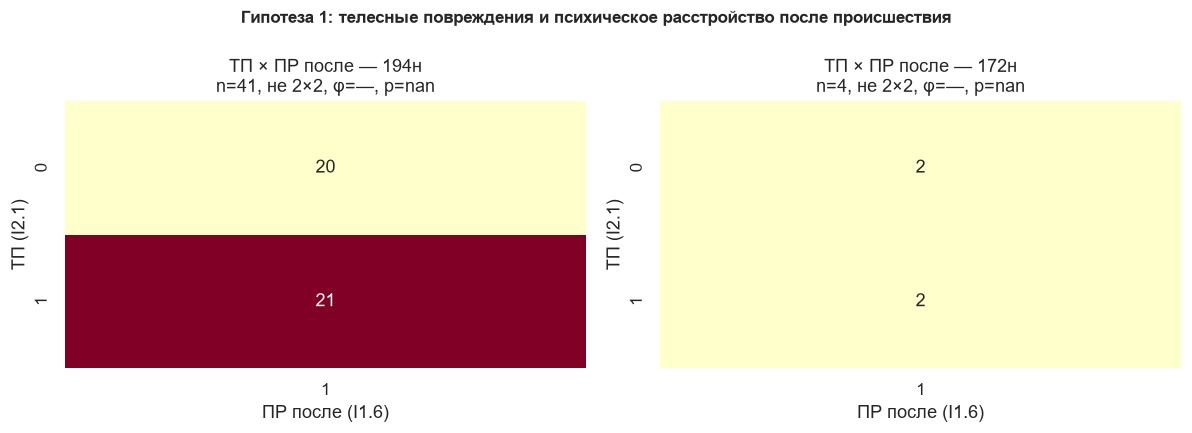

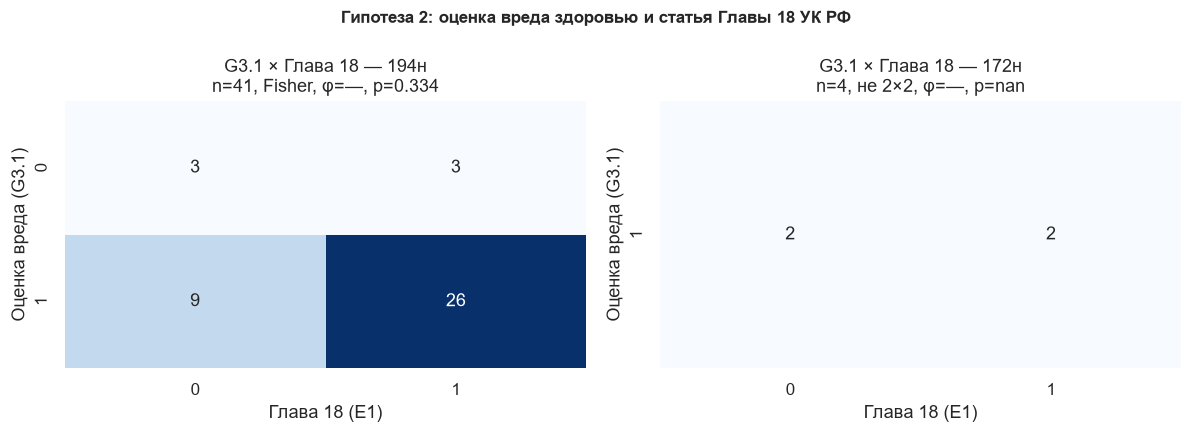

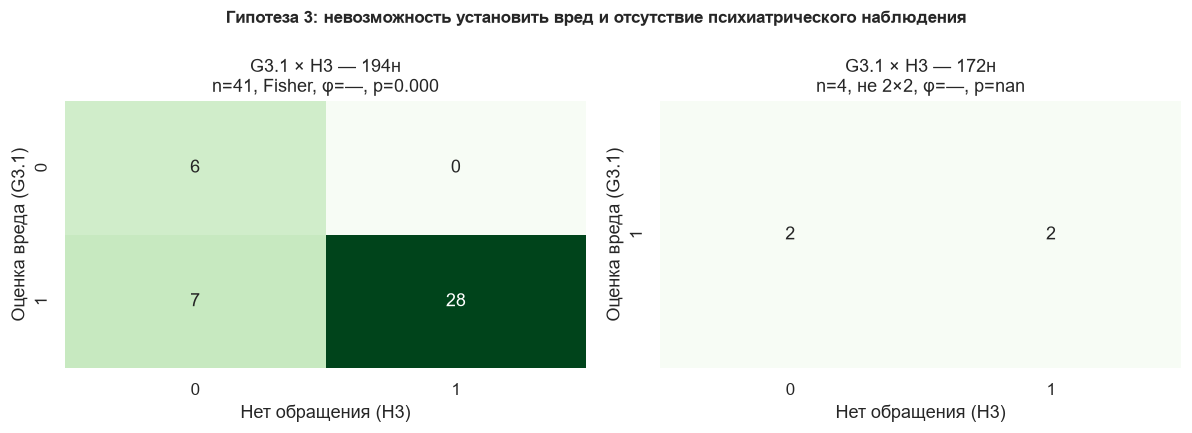

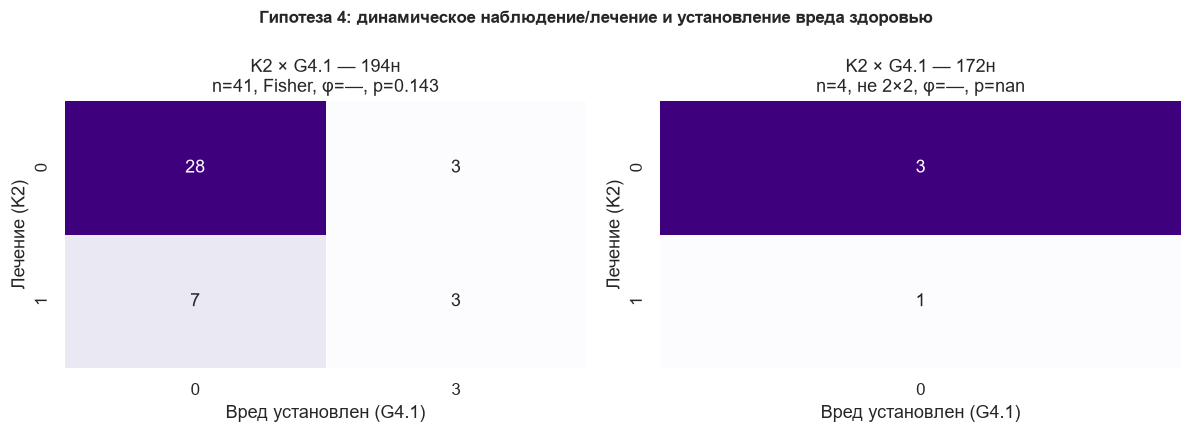

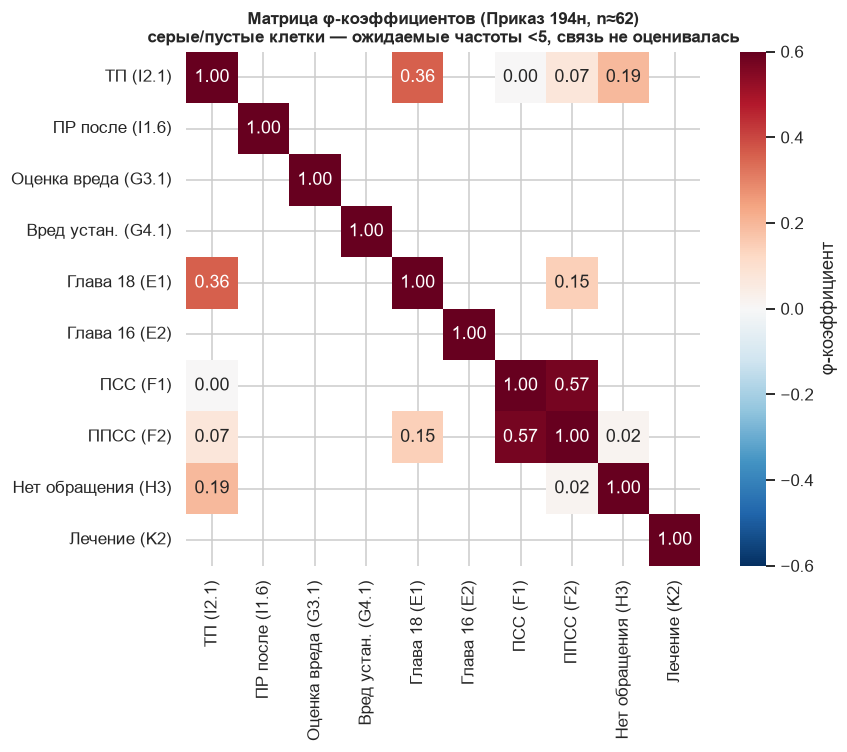

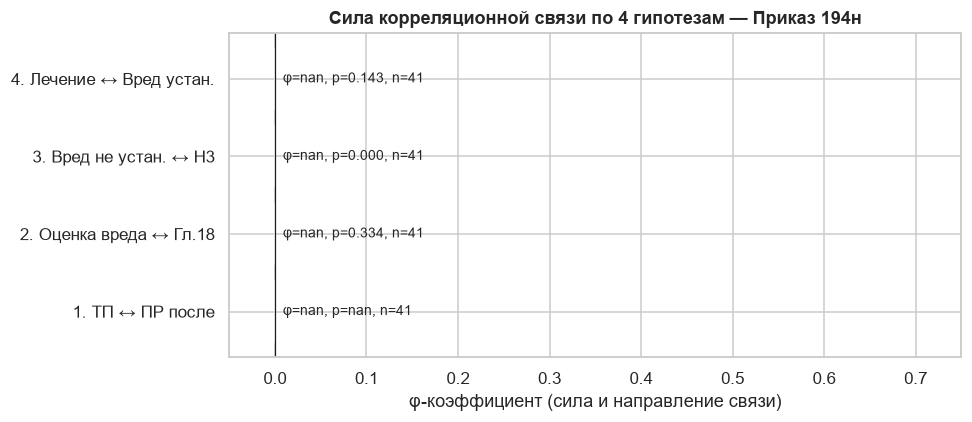

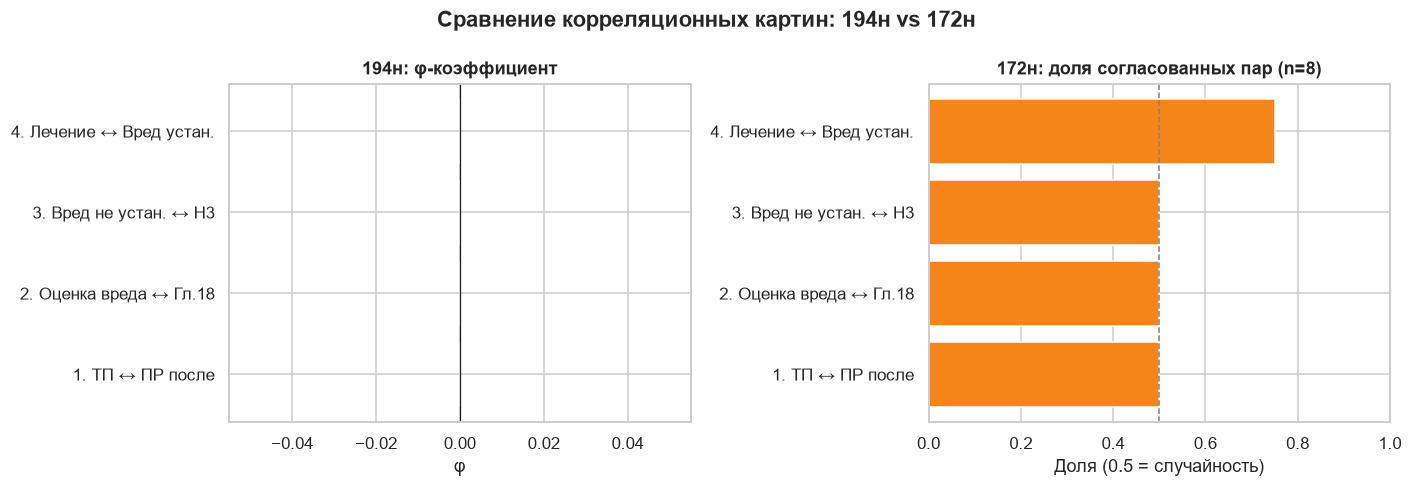

In [5]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, fisher_exact

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

path = "Таблица для статистики_редакция от 02.10.26.xlsx"
raw = pd.read_excel(path, sheet_name="Sheet2", header=None)

COLS = {
    "id":0,"day":1,"month":2,"year":3,
    "E1_gl18":14,"E2_gl16":15,"E3_other":16,
    "F1_PSS":17,"F2_PPSS":18,"F4_net_PSS":20,"F5_SPE_no":21,
    "G1_1":22,"G2_1":23,"G3_1":24,"G4_1":25,
    "H1":26,"H2":27,"H3":28,"H4":29,"H5":30,"H6":31,"H7":32,"H8":33,
    "I1_1":34,"I1_2":35,"I1_3":36,"I1_4":37,"I1_5":38,"I1_6":39,
    "I1_7":40,"I1_8":41,
    "I2_1":42,"I2_2":43,"I2_3":44,"I2_4":45,"I2_5":46,"I2_6":47,
    "J1":48,"J2":49,"J3":50,"K1":51,"K2":52,"K3":53,"K4":54,
}

def extract(df_raw, start, end):
    d = df_raw.iloc[start:end, list(COLS.values())].copy()
    d.columns = list(COLS.keys())
    d["year_num"] = pd.to_numeric(d["year"], errors="coerce")
    d = d[d["year_num"].between(2000, 2030)].reset_index(drop=True)
    for c in d.columns:
        if c not in ("id","day","month","year","year_num"):
            d[c] = pd.to_numeric(d[c], errors="coerce")
    return d

t194 = extract(raw, 5, 67)    # верхняя таблица Sheet2
t172 = extract(raw, 77, 85)   # нижняя таблица Sheet2

def corr_stats(df, c1, c2):
    x = df[c1].fillna(0).astype(int)
    y = df[c2].fillna(0).astype(int)
    ct = pd.crosstab(x, y)
    n = int(ct.values.sum())
    if ct.shape != (2, 2):
        return ct, n, np.nan, np.nan, "не 2×2"
    exp = chi2_contingency(ct, correction=False)[3]
    if (exp < 5).any():
        _, p = fisher_exact(ct.values)
        return ct, n, np.nan, p, "Fisher"
    chi2, p, _, _ = chi2_contingency(ct)
    return ct, n, np.sqrt(chi2 / n), p, "χ²/φ"

HYP = {
    "1. ТП ↔ ПР после":         ("I2_1", "I1_6"),
    "2. Оценка вреда ↔ Гл.18":  ("G3_1", "E1_gl18"),
    "3. Вред не устан. ↔ H3":   ("G3_1", "H3"),
    "4. Лечение ↔ Вред устан.": ("K2",  "G4_1"),
}



#---------------------------- 1 --------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (df, title) in zip(axes, [(t194, "194н"), (t172, "172н")]):
    ct, n, phi, p, m = corr_stats(df, "I2_1", "I1_6")
    sns.heatmap(ct, annot=True, fmt="d", cmap="YlOrRd", cbar=False, ax=ax)
    ax.set_title(f"ТП × ПР после — {title}\nn={n}, {m}, φ={phi if not np.isnan(phi) else '—'}, p={p:.3f}")
    ax.set_xlabel("ПР после (I1.6)"); ax.set_ylabel("ТП (I2.1)")
plt.suptitle("Гипотеза 1: телесные повреждения и психическое расстройство после происшествия",
             fontsize=11, weight="bold")
plt.tight_layout(); plt.savefig("corr1_TП_PР.png", bbox_inches="tight"); plt.show()
#---------------------------- 2 --------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (df, title) in zip(axes, [(t194, "194н"), (t172, "172н")]):
    ct, n, phi, p, m = corr_stats(df, "G3_1", "E1_gl18")
    sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"G3.1 × Глава 18 — {title}\nn={n}, {m}, φ={phi if not np.isnan(phi) else '—'}, p={p:.3f}")
    ax.set_xlabel("Глава 18 (E1)"); ax.set_ylabel("Оценка вреда (G3.1)")
plt.suptitle("Гипотеза 2: оценка вреда здоровью и статья Главы 18 УК РФ",
             fontsize=11, weight="bold")
plt.tight_layout(); plt.savefig("corr2_G31_Gl18.png", bbox_inches="tight"); plt.show()
#---------------------------- 3 --------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (df, title) in zip(axes, [(t194, "194н"), (t172, "172н")]):
    ct, n, phi, p, m = corr_stats(df, "G3_1", "H3")
    sns.heatmap(ct, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax)
    ax.set_title(f"G3.1 × H3 — {title}\nn={n}, {m}, φ={phi if not np.isnan(phi) else '—'}, p={p:.3f}")
    ax.set_xlabel("Нет обращения (H3)"); ax.set_ylabel("Оценка вреда (G3.1)")
plt.suptitle("Гипотеза 3: невозможность установить вред и отсутствие психиатрического наблюдения",
             fontsize=11, weight="bold")
plt.tight_layout(); plt.savefig("corr3_G31_H3.png", bbox_inches="tight"); plt.show()
#---------------------------- 4 --------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (df, title) in zip(axes, [(t194, "194н"), (t172, "172н")]):
    ct, n, phi, p, m = corr_stats(df, "K2", "G4_1")
    sns.heatmap(ct, annot=True, fmt="d", cmap="Purples", cbar=False, ax=ax)
    ax.set_title(f"K2 × G4.1 — {title}\nn={n}, {m}, φ={phi if not np.isnan(phi) else '—'}, p={p:.3f}")
    ax.set_xlabel("Вред установлен (G4.1)"); ax.set_ylabel("Лечение (K2)")
plt.suptitle("Гипотеза 4: динамическое наблюдение/лечение и установление вреда здоровью",
             fontsize=11, weight="bold")
plt.tight_layout(); plt.savefig("corr4_K2_G41.png", bbox_inches="tight"); plt.show()


#----------------------------------------- Общая сводка 194н --------------------------------------
keys = {
    "ТП (I2.1)": "I2_1",
    "ПР после (I1.6)": "I1_6",
    "Оценка вреда (G3.1)": "G3_1",
    "Вред устан. (G4.1)": "G4_1",
    "Глава 18 (E1)": "E1_gl18",
    "Глава 16 (E2)": "E2_gl16",
    "ПСС (F1)": "F1_PSS",
    "ППСС (F2)": "F2_PPSS",
    "Нет обращения (H3)": "H3",
    "Лечение (K2)": "K2",
}
df = t194[list(keys.values())].fillna(0).astype(int)
df.columns = list(keys.keys())

def phi_matrix(d):
    cols = d.columns
    M = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
    for i in range(len(cols)):
        for j in range(i+1, len(cols)):
            ct = pd.crosstab(d.iloc[:, i], d.iloc[:, j])
            if ct.shape == (2, 2):
                exp = chi2_contingency(ct, correction=False)[3]
                if (exp >= 5).all():
                    chi2 = chi2_contingency(ct)[0]
                    v = np.sqrt(chi2 / ct.values.sum())
                else:
                    v = np.nan
            else:
                v = np.nan
            M.iloc[i, j] = M.iloc[j, i] = v
    return M

M = phi_matrix(df)

plt.figure(figsize=(9, 7))
sns.heatmap(M.astype(float), annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-0.6, vmax=0.6, center=0, square=True,
            cbar_kws={"label": "φ-коэффициент"})
plt.title("Матрица φ-коэффициентов (Приказ 194н, n≈62)\n"
          "серые/пустые клетки — ожидаемые частоты <5, связь не оценивалась",
          fontsize=11, weight="bold")
plt.tight_layout(); plt.savefig("corr_matrix_194.png", bbox_inches="tight"); plt.show()


#---------------------------------------- Сводный бар-чарт силы связи по 4 гипотезам (194н) ----------------
rows = []
for name, (c1, c2) in HYP.items():
    ct, n, phi, p, m = corr_stats(t194, c1, c2)
    rows.append({"Гипотеза": name, "φ": phi, "p": p, "n": n})
bar = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#4c78a8" if v > 0 else "#e45756" for v in bar["φ"].fillna(0)]
ax.barh(bar["Гипотеза"], bar["φ"].fillna(0), color=colors)
ax.axvline(0, color="k", lw=0.8)
for i, r in bar.iterrows():
    ax.text(r["φ"] if pd.notna(r["φ"]) else 0,
            i, f'  φ={r["φ"]:.2f}, p={r["p"]:.3f}, n={r["n"]}',
            va="center", fontsize=9)
ax.set_xlim(-0.05, 0.75)
ax.set_xlabel("φ-коэффициент (сила и направление связи)")
ax.set_title("Сила корреляционной связи по 4 гипотезам — Приказ 194н",
             weight="bold")
plt.tight_layout(); plt.savefig("corr_bars_194.png", bbox_inches="tight"); plt.show()


#----------------------------------------------- Сравнение силы связи 194н vs 172н -------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Слева: φ для 194н
axes[0].barh(bar["Гипотеза"], bar["φ"].fillna(0), color="#4c78a8")
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_title("194н: φ-коэффициент", weight="bold")
axes[0].set_xlabel("φ")

# Справа: доля согласованных пар (обе=1 или обе=0) для 172н
agree = []
for name, (c1, c2) in HYP.items():
    x = t172[c1].fillna(0).astype(int)
    y = t172[c2].fillna(0).astype(int)
    agree.append(((x == y).mean(), name))
agree_df = pd.DataFrame(agree, columns=["agree", "Гипотеза"])
axes[1].barh(agree_df["Гипотеза"], agree_df["agree"], color="#f58518")
axes[1].axvline(0.5, color="gray", ls="--", lw=1)
axes[1].set_xlim(0, 1)
axes[1].set_title("172н: доля согласованных пар (n=8)", weight="bold")
axes[1].set_xlabel("Доля (0.5 = случайность)")

plt.suptitle("Сравнение корреляционных картин: 194н vs 172н", weight="bold")
plt.tight_layout(); plt.savefig("corr_compare.png", bbox_inches="tight"); plt.show()

194н: n=62 | 172н: n=8
   I1_6  I2_1  G3_1  G4_1  E1  E2  E3   H3  K2
0     1     1     1     0   1   0   0  0.0   0
1     1     0     1     0   0   0   0  1.0   0
2     1     1     0     3   1   0   0  NaN   0
3     1     1     1     0   0   1   1  1.0   0
4     1     1     1     0   1   0   0  1.0   0


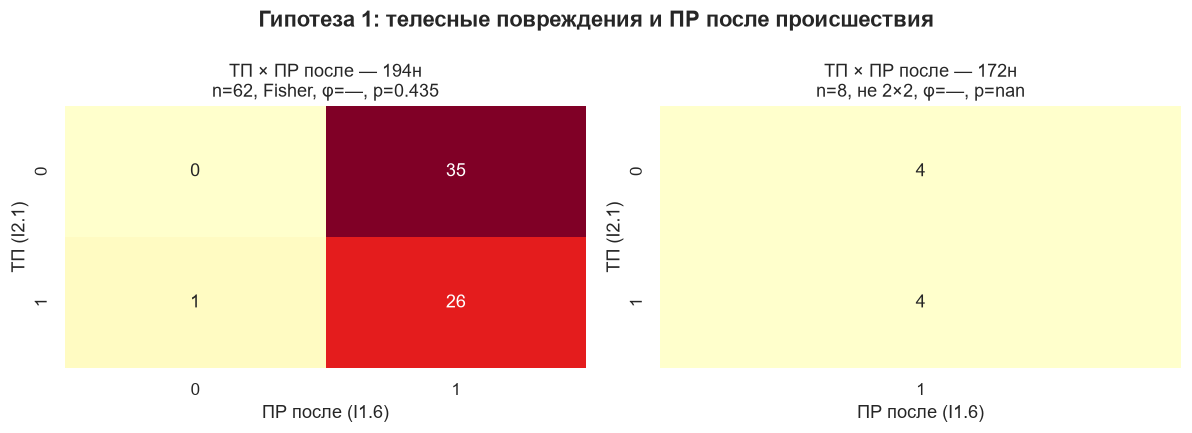

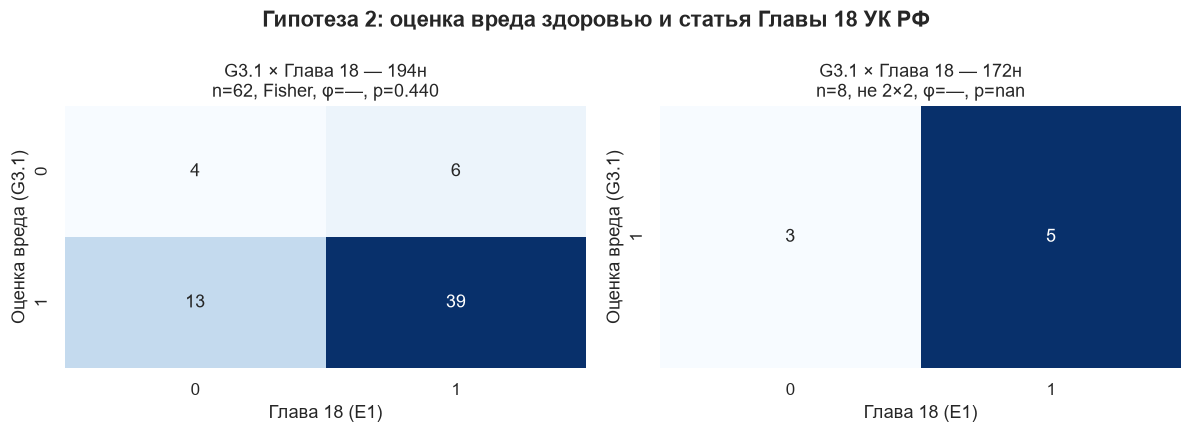

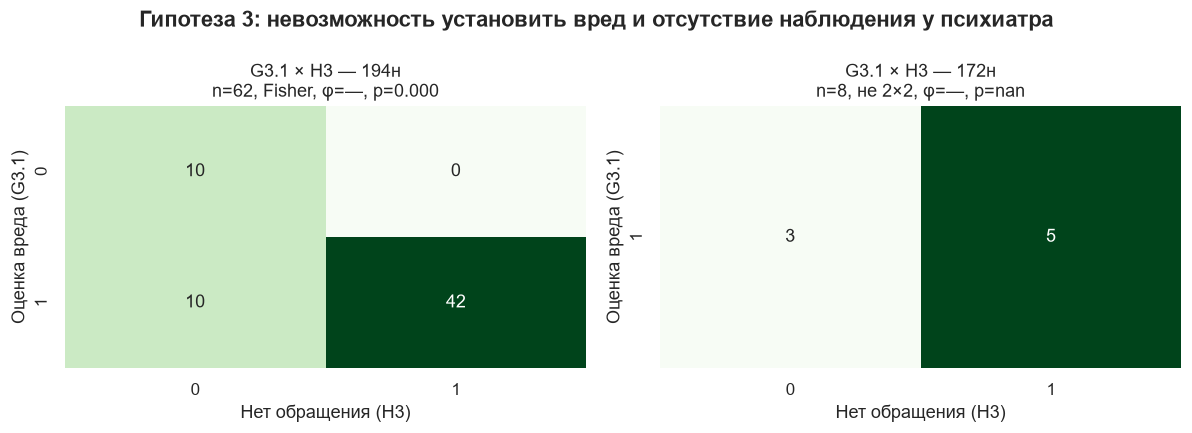

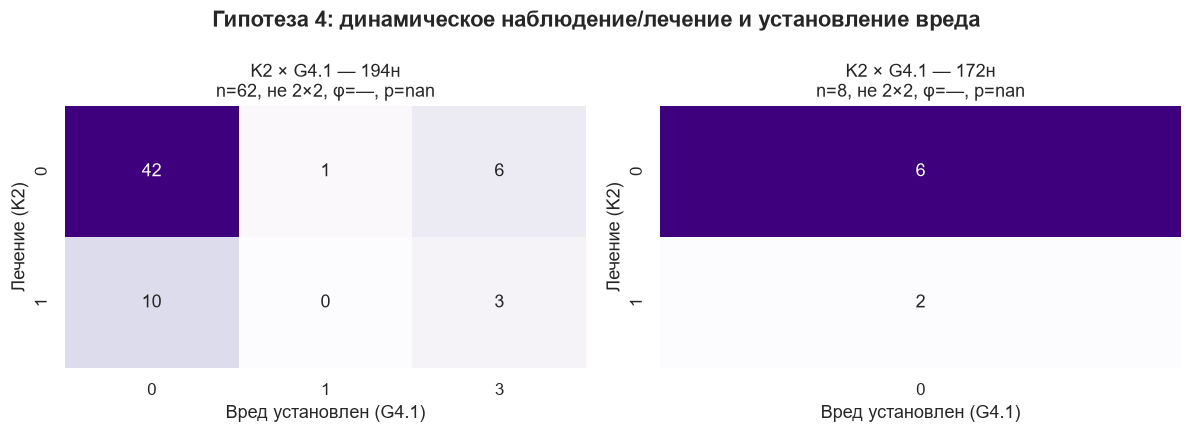

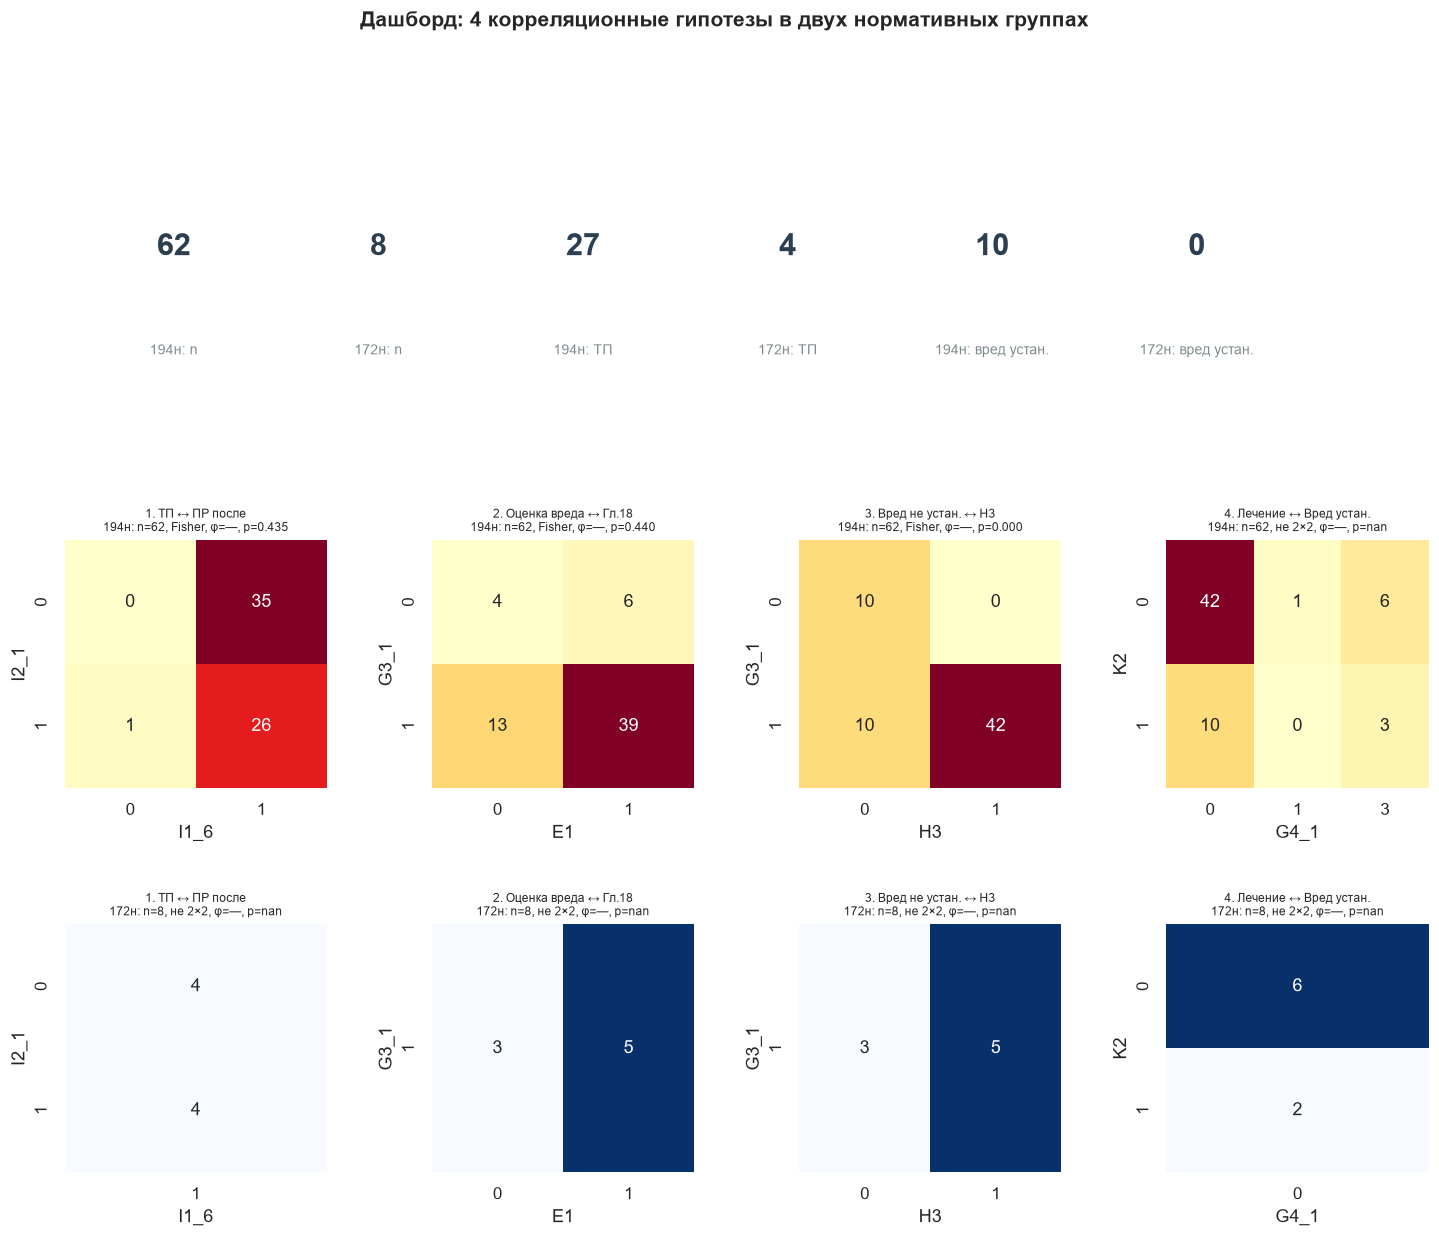

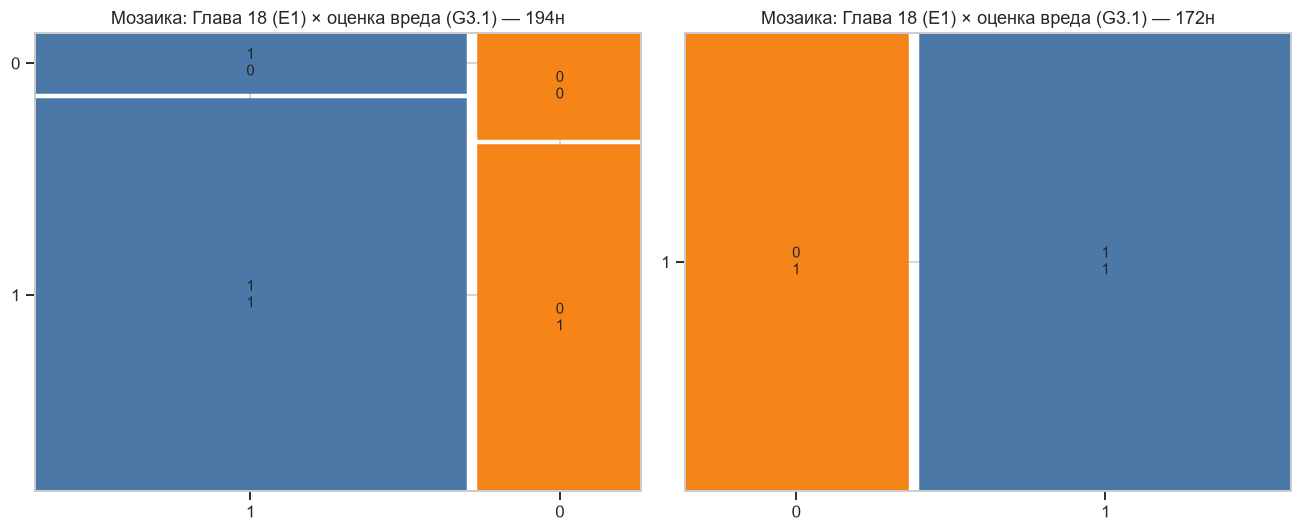

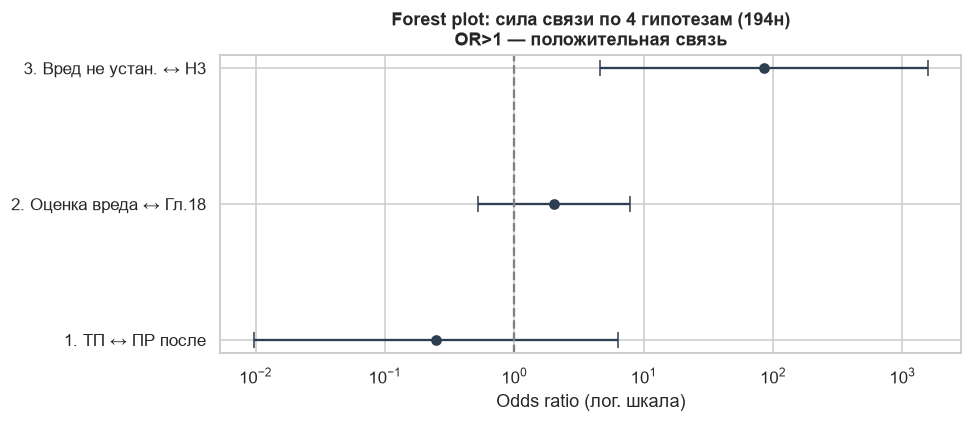

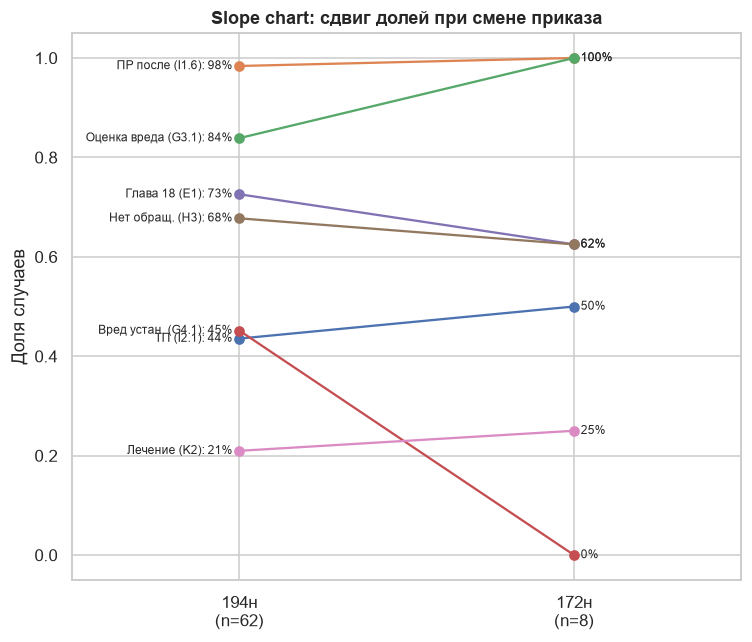

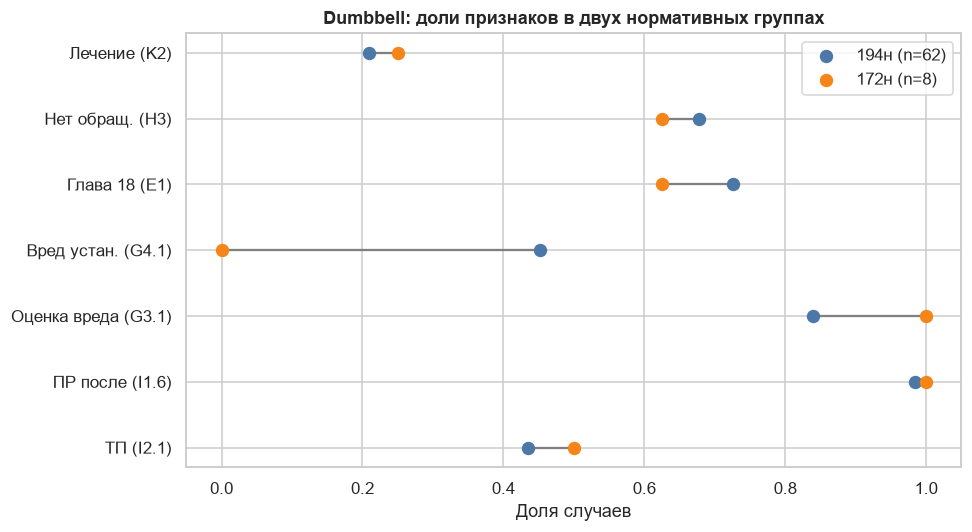

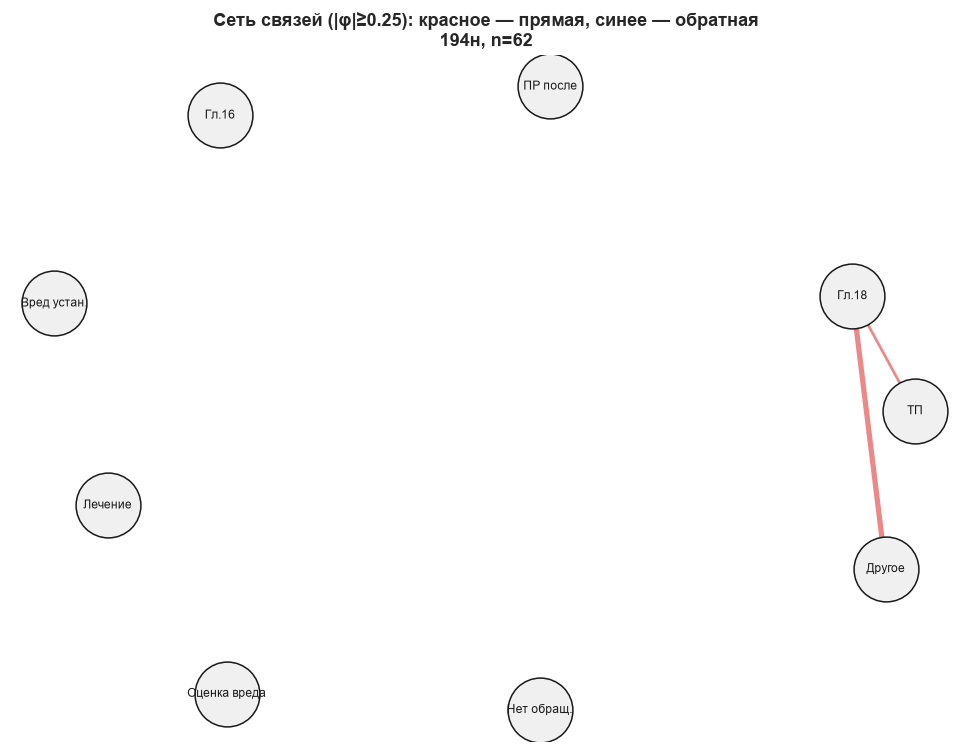

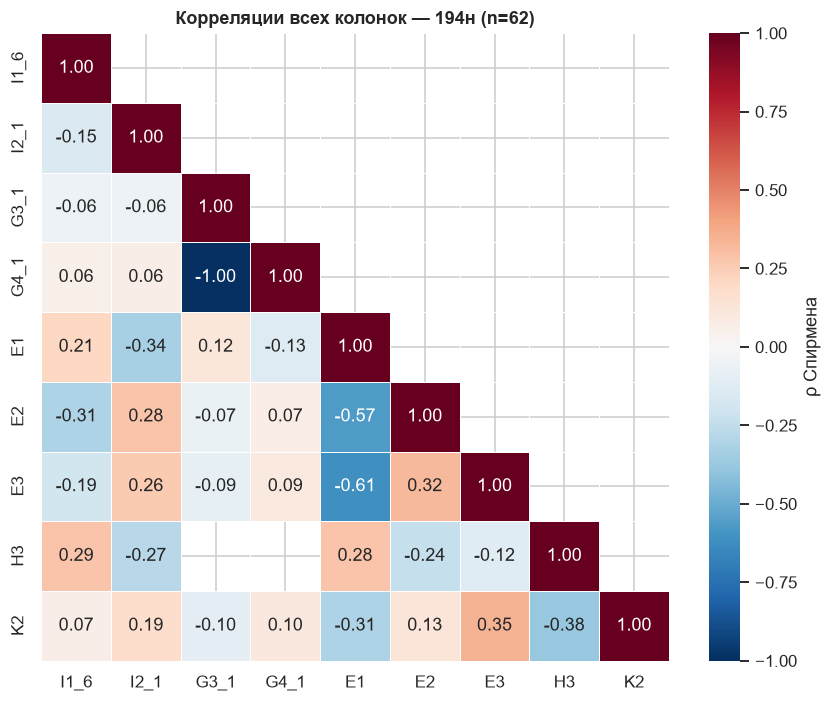

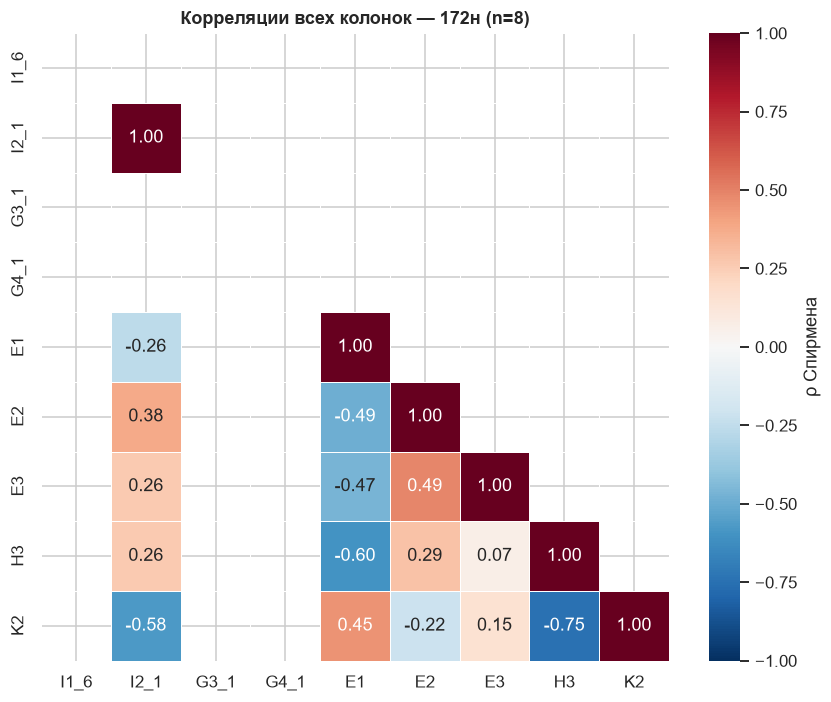

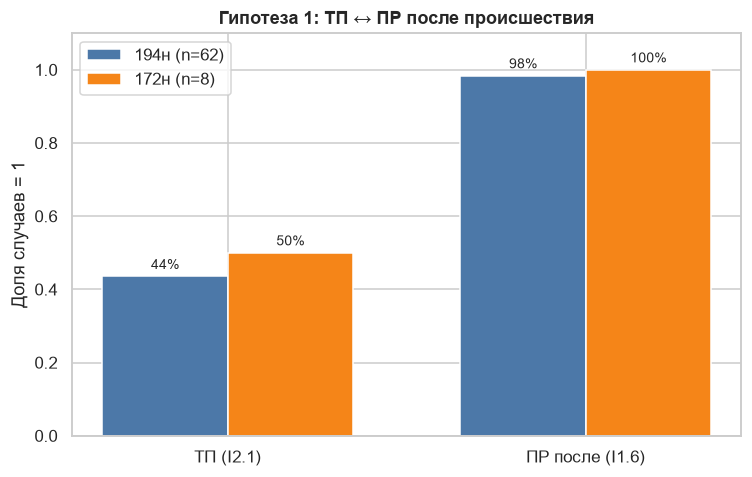

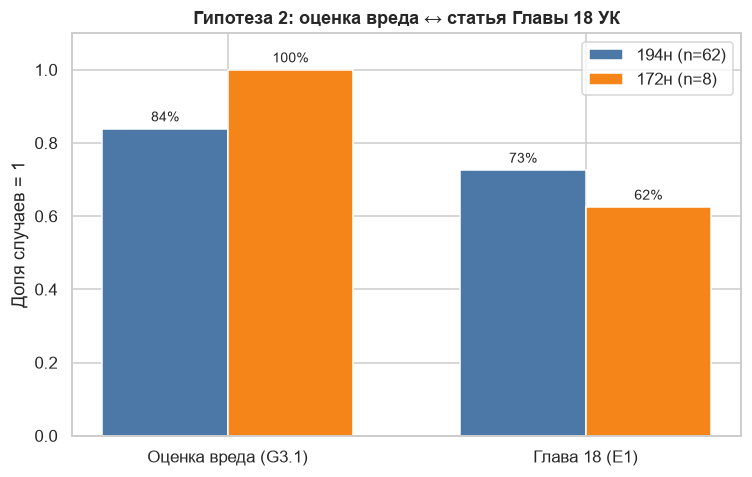

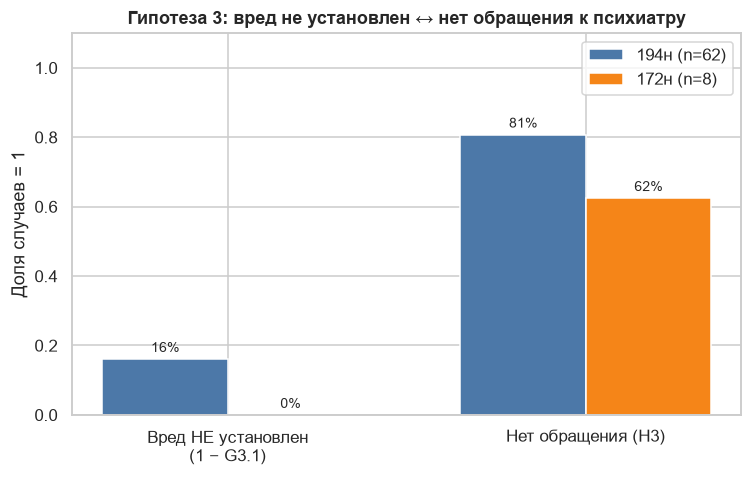

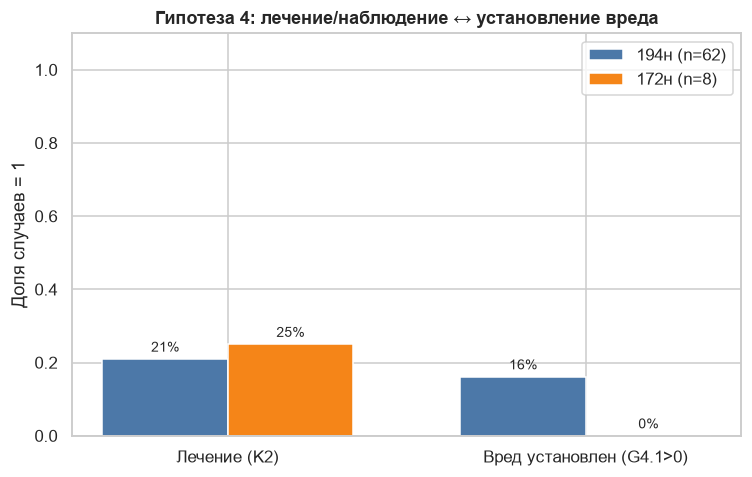

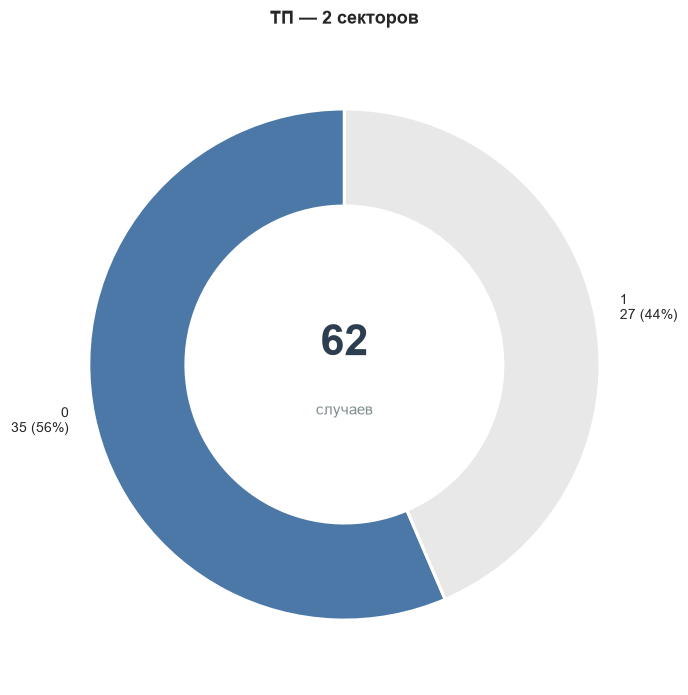

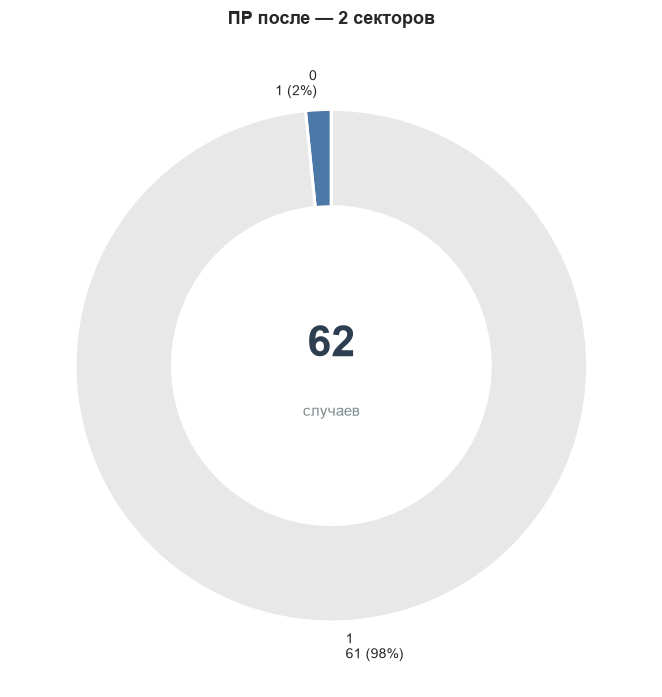

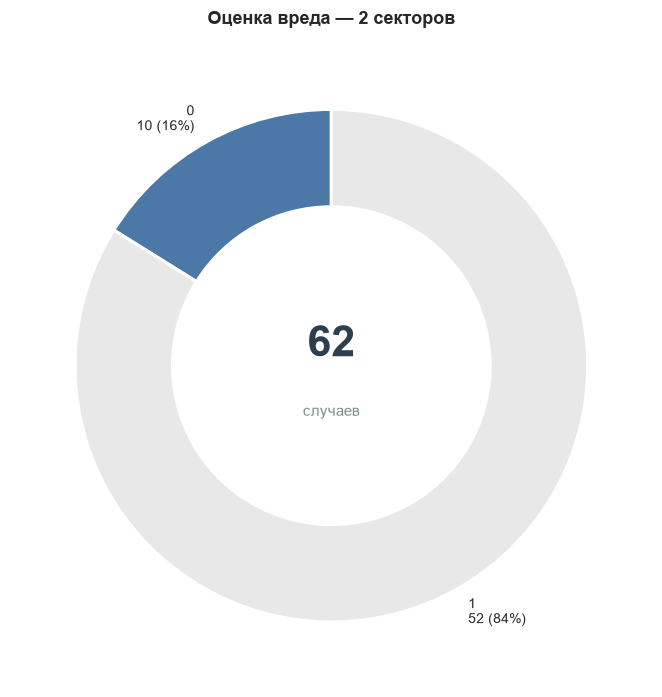

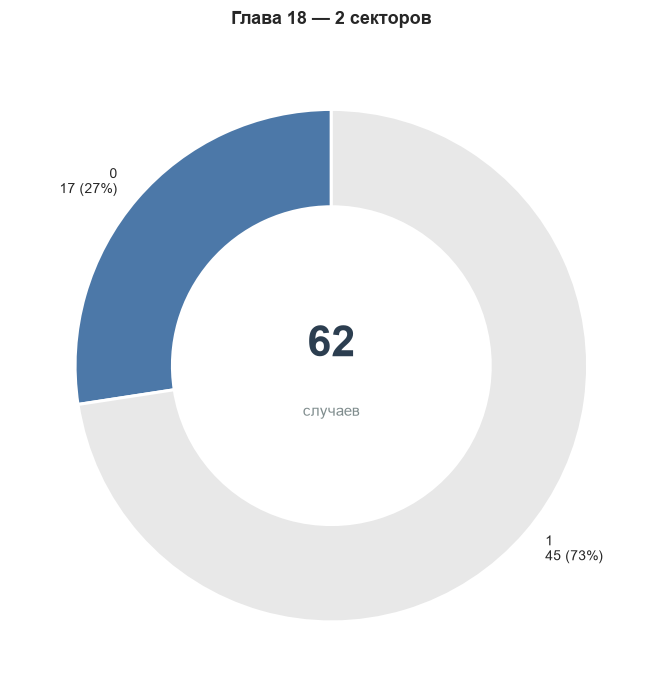

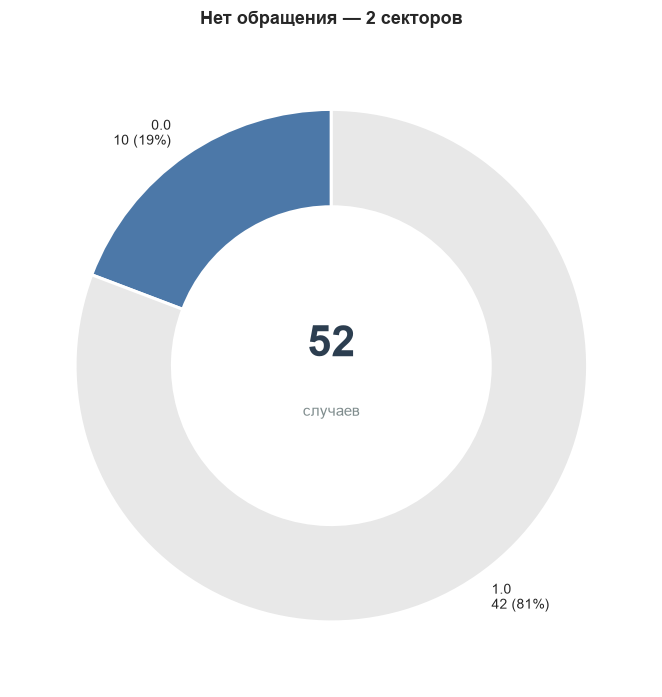

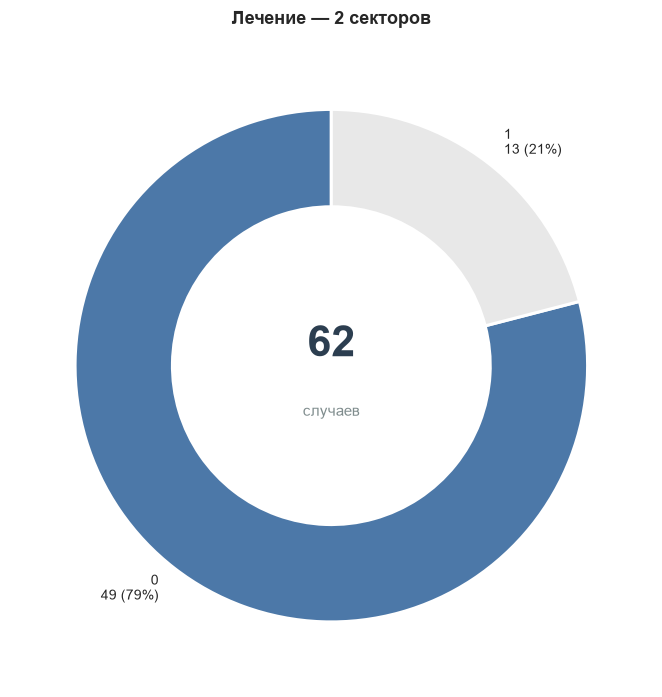

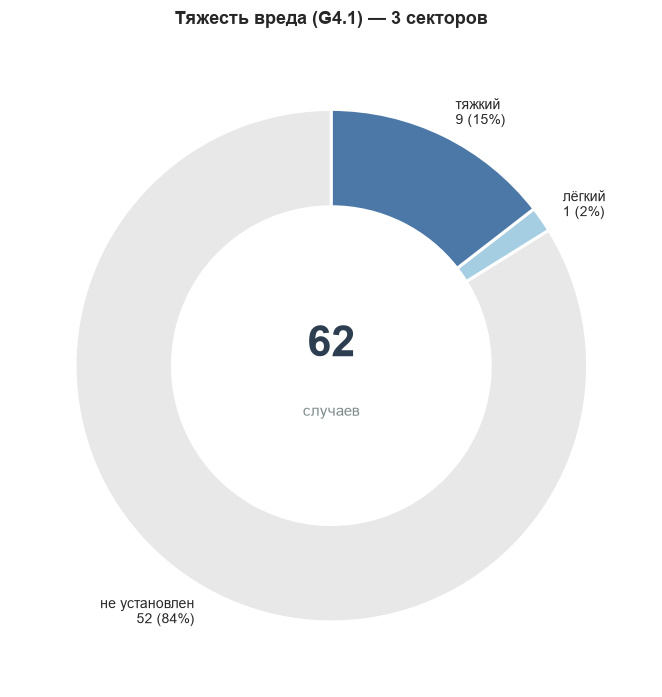

G4_1
0    52
1     1
3     9
Name: count, dtype: int64

In [20]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, fisher_exact

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

path = "Таблица для визуализаций.xlsx"

# Данные начинаются с 6-й строки Excel (iloc=5).
# Колонки: A..I -> I1.6, I2.1, G3.1, G4.1, E1, E2, E3, H3, K2
def load(sheet):
    raw = pd.read_excel(path, sheet_name=sheet, header=None)
    d = raw.iloc[5: , 0:9].copy()
    d.columns = ["I1_6","I2_1","G3_1","G4_1","E1","E2","E3","H3","K2"]
    # оставляем только строки с данными (I1.6 заполнен 0/1)
    d = d[pd.to_numeric(d["I1_6"], errors="coerce").isin([0,1])].reset_index(drop=True)
    for c in d.columns:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    return d

t194 = load("194н")
t172 = load("172н")
print(f"194н: n={len(t194)} | 172н: n={len(t172)}")
print(t194.head())

#-----------------------------------------------------------------------------------
#-----------------------------------------------------------------------------------
#-----------------------------------------------------------------------------------

def corr_stats(df, c1, c2):
    x = df[c1].fillna(0).astype(int)
    y = df[c2].fillna(0).astype(int)
    ct = pd.crosstab(x, y)
    n = int(ct.values.sum())
    if ct.shape != (2, 2):
        return ct, n, np.nan, np.nan, "не 2×2"
    exp = chi2_contingency(ct, correction=False)[3]
    if (exp < 5).any():
        _, p = fisher_exact(ct.values)
        return ct, n, np.nan, p, "Fisher"
    chi2, p, _, _ = chi2_contingency(ct)
    return ct, n, np.sqrt(chi2 / n), p, "χ²/φ"

HYP = {
    "1. ТП ↔ ПР после":         ("I2_1", "I1_6"),
    "2. Оценка вреда ↔ Гл.18":  ("G3_1", "E1"),
    "3. Вред не устан. ↔ H3":   ("G3_1", "H3"),
    "4. Лечение ↔ Вред устан.": ("K2",  "G4_1"),
}

#-----------------------------------------------------------------------------------
#-----------------------------------------------------------------------------------
#-----------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (df, title) in zip(axes, [(t194, "194н"), (t172, "172н")]):
    ct, n, phi, p, m = corr_stats(df, "I2_1", "I1_6")
    sns.heatmap(ct, annot=True, fmt="d", cmap="YlOrRd", cbar=False, ax=ax)
    phi_s = f"{phi:.2f}" if pd.notna(phi) else "—"
    ax.set_title(f"ТП × ПР после — {title}\nn={n}, {m}, φ={phi_s}, p={p:.3f}")
    ax.set_xlabel("ПР после (I1.6)"); ax.set_ylabel("ТП (I2.1)")
plt.suptitle("Гипотеза 1: телесные повреждения и ПР после происшествия", weight="bold")
plt.tight_layout(); plt.savefig("corr1.png", bbox_inches="tight"); plt.show()

#-----------------------------------------------------------------------------------
#-----------------------------------------------------------------------------------
#-----------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (df, title) in zip(axes, [(t194, "194н"), (t172, "172н")]):
    ct, n, phi, p, m = corr_stats(df, "G3_1", "E1")
    sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    phi_s = f"{phi:.2f}" if pd.notna(phi) else "—"
    ax.set_title(f"G3.1 × Глава 18 — {title}\nn={n}, {m}, φ={phi_s}, p={p:.3f}")
    ax.set_xlabel("Глава 18 (E1)"); ax.set_ylabel("Оценка вреда (G3.1)")
plt.suptitle("Гипотеза 2: оценка вреда здоровью и статья Главы 18 УК РФ", weight="bold")
plt.tight_layout(); plt.savefig("corr2.png", bbox_inches="tight"); plt.show()

#-----------------------------------------------------------------------------------
#-----------------------------------------------------------------------------------
#-----------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (df, title) in zip(axes, [(t194, "194н"), (t172, "172н")]):
    ct, n, phi, p, m = corr_stats(df, "G3_1", "H3")
    sns.heatmap(ct, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax)
    phi_s = f"{phi:.2f}" if pd.notna(phi) else "—"
    ax.set_title(f"G3.1 × H3 — {title}\nn={n}, {m}, φ={phi_s}, p={p:.3f}")
    ax.set_xlabel("Нет обращения (H3)"); ax.set_ylabel("Оценка вреда (G3.1)")
plt.suptitle("Гипотеза 3: невозможность установить вред и отсутствие наблюдения у психиатра", weight="bold")
plt.tight_layout(); plt.savefig("corr3.png", bbox_inches="tight"); plt.show()

#-----------------------------------------------------------------------------------
#-----------------------------------------------------------------------------------
#-----------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (df, title) in zip(axes, [(t194, "194н"), (t172, "172н")]):
    ct, n, phi, p, m = corr_stats(df, "K2", "G4_1")
    sns.heatmap(ct, annot=True, fmt="d", cmap="Purples", cbar=False, ax=ax)
    phi_s = f"{phi:.2f}" if pd.notna(phi) else "—"
    ax.set_title(f"K2 × G4.1 — {title}\nn={n}, {m}, φ={phi_s}, p={p:.3f}")
    ax.set_xlabel("Вред установлен (G4.1)"); ax.set_ylabel("Лечение (K2)")
plt.suptitle("Гипотеза 4: динамическое наблюдение/лечение и установление вреда", weight="bold")
plt.tight_layout(); plt.savefig("corr4.png", bbox_inches="tight"); plt.show()

#-----------------------------------------------------------------------------------
#-----------------------------------------------------------------------------------
#-----------------------------------------------------------------------------------



#-----------------------------------------------------------------------------------
#-----------------------------------------------------------------------------------
#-----------------------------------------------------------------------------------

from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(16, 12))
gs = GridSpec(3, 4, figure=fig, hspace=0.55, wspace=0.4)

# --- KPI ---
ax_k = fig.add_subplot(gs[0, :]); ax_k.axis("off")
kpi = [
    ("194н: n", len(t194)), ("172н: n", len(t172)),
    ("194н: ТП", int(t194["I2_1"].fillna(0).sum())),
    ("172н: ТП", int(t172["I2_1"].fillna(0).sum())),
    ("194н: вред устан.", int(t194["G4_1"].fillna(0).gt(0).sum())),
    ("172н: вред устан.", int(t172["G4_1"].fillna(0).gt(0).sum())),
]
for i,(lbl,val) in enumerate(kpi):
    ax_k.text(0.08+i*0.15, 0.6, str(val), fontsize=20, weight="bold",
              ha="center", color="#2c3e50")
    ax_k.text(0.08+i*0.15, 0.2, lbl, fontsize=9, ha="center", color="#7f8c8d")

# --- 4 гипотезы: 194н (верх) и 172н (низ) ---
for j,(name,(c1,c2)) in enumerate(HYP.items()):
    for i,(df,label,cmap) in enumerate([(t194,"194н","YlOrRd"),(t172,"172н","Blues")]):
        ax = fig.add_subplot(gs[1+i, j])
        ct, n, phi, p, m = corr_stats(df, c1, c2)
        sns.heatmap(ct, annot=True, fmt="d", cmap=cmap, cbar=False, ax=ax)
        phi_s = f"{phi:.2f}" if pd.notna(phi) else "—"
        ax.set_title(f"{name}\n{label}: n={n}, {m}, φ={phi_s}, p={p:.3f}", fontsize=8)

fig.suptitle("Дашборд: 4 корреляционные гипотезы в двух нормативных группах",
             fontsize=14, weight="bold", y=0.99)
plt.savefig("dashboard_corr.png", bbox_inches="tight", dpi=150); plt.show()

#-----------------------------------------------------------------------------------
#-----------------------------------------------------------------------------------
#-----------------------------------------------------------------------------------


#---------------------------------Тесты графиков -----------------------------------
from statsmodels.graphics.mosaicplot import mosaic

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (df, title) in zip(axes, [(t194, "194н"), (t172, "172н")]):
    mosaic(df, ["E1", "G3_1"], ax=ax, gap=0.02,
           properties=lambda k: {"color": "#4c78a8" if k[0]=="1" else "#f58518"})
    ax.set_title(f"Мозаика: Глава 18 (E1) × оценка вреда (G3.1) — {title}")
plt.tight_layout(); plt.savefig("mosaic.png", bbox_inches="tight"); plt.show()

#-----------------------------------------------------------------------------------
from scipy.stats import fisher_exact

def odds_ci(df, c1, c2):
    ct = pd.crosstab(df[c1].fillna(0).astype(int), df[c2].fillna(0).astype(int))
    if ct.shape != (2,2): return None
    a,b,c,d = ct.values.ravel()
    # поправка Хаулдейна при нулях
    a,b,c,d = a+0.5, b+0.5, c+0.5, d+0.5
    or_ = (a*d)/(b*c)
    se = np.sqrt(1/a+1/b+1/c+1/d)
    lo, hi = np.exp(np.log(or_)-1.96*se), np.exp(np.log(or_)+1.96*se)
    return or_, lo, hi

rows = []
for name,(c1,c2) in HYP.items():
    r = odds_ci(t194, c1, c2)
    if r: rows.append({"Гипотеза": name, "OR": r[0], "lo": r[1], "hi": r[2]})
forest = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(forest))
ax.errorbar(forest["OR"], y, xerr=[forest["OR"]-forest["lo"], forest["hi"]-forest["OR"]],
            fmt="o", color="#2c3e50", capsize=5)
ax.axvline(1, color="gray", ls="--")
ax.set_yticks(y); ax.set_yticklabels(forest["Гипотеза"])
ax.set_xscale("log"); ax.set_xlabel("Odds ratio (лог. шкала)")
ax.set_title("Forest plot: сила связи по 4 гипотезам (194н)\nOR>1 — положительная связь", weight="bold")
plt.tight_layout(); plt.savefig("forest.png", bbox_inches="tight"); plt.show()

#----------------------------------------------------------------------------------------------------------
compare = {"ТП (I2.1)":"I2_1","ПР после (I1.6)":"I1_6","Оценка вреда (G3.1)":"G3_1",
           "Вред устан. (G4.1)":"G4_1","Глава 18 (E1)":"E1","Нет обращ. (H3)":"H3","Лечение (K2)":"K2"}
d194 = [t194[c].fillna(0).astype(float).mean() for c in compare.values()]
d172 = [t172[c].fillna(0).astype(float).mean() for c in compare.values()]

fig, ax = plt.subplots(figsize=(7, 6))
for lbl, a, b in zip(compare.keys(), d194, d172):
    ax.plot([0,1], [a,b], marker="o", lw=1.5)
    ax.text(-0.02, a, f"{lbl}: {a:.0%}", ha="right", va="center", fontsize=8)
    ax.text(1.02, b, f"{b:.0%}", ha="left", va="center", fontsize=8)
ax.set_xticks([0,1]); ax.set_xticklabels([f"194н\n(n={len(t194)})", f"172н\n(n={len(t172)})"])
ax.set_ylabel("Доля случаев"); ax.set_xlim(-0.5, 1.5)
ax.set_title("Slope chart: сдвиг долей при смене приказа", weight="bold")
plt.tight_layout(); plt.savefig("slope.png", bbox_inches="tight"); plt.show()

#----------------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(compare))
ax.hlines(y, d194, d172, color="gray", lw=1.5)
ax.scatter(d194, y, color="#4c78a8", s=60, label=f"194н (n={len(t194)})", zorder=3)
ax.scatter(d172, y, color="#f58518", s=60, label=f"172н (n={len(t172)})", zorder=3)
ax.set_yticks(y); ax.set_yticklabels(list(compare.keys()))
ax.set_xlabel("Доля случаев"); ax.legend()
ax.set_title("Dumbbell: доли признаков в двух нормативных группах", weight="bold")
plt.tight_layout(); plt.savefig("dumbbell.png", bbox_inches="tight"); plt.show()

#----------------------------------------------------------------------------------------------------------
import networkx as nx

keys = {"ПР после":"I1_6","ТП":"I2_1","Оценка вреда":"G3_1","Вред устан.":"G4_1",
        "Гл.18":"E1","Гл.16":"E2","Другое":"E3","Нет обращ.":"H3","Лечение":"K2"}
df = t194[list(keys.values())].fillna(0).astype(int); df.columns = list(keys.keys())
M = phi_matrix(df)  # из предыдущего ответа

G = nx.Graph()
for n in M.index: G.add_node(n)
for i in M.index:
    for j in M.columns:
        if i < j and pd.notna(M.loc[i,j]) and abs(M.loc[i,j]) >= 0.25:
            G.add_edge(i, j, weight=abs(M.loc[i,j]), sign=np.sign(M.loc[i,j]))

fig, ax = plt.subplots(figsize=(9, 7))
pos = nx.spring_layout(G, seed=42, k=1.2)
edges = G.edges(data=True)
colors = ["#e45756" if d["sign"]>0 else "#4c78a8" for *_,d in edges]
widths = [d["weight"]*6 for *_,d in edges]
nx.draw_networkx_nodes(G, pos, node_color="#f0f0f0", edgecolors="k", node_size=1800, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)
nx.draw_networkx_edges(G, pos, edge_color=colors, width=widths, alpha=0.7, ax=ax)
ax.set_title("Сеть связей (|φ|≥0.25): красное — прямая, синее — обратная\n194н, n=62", weight="bold")
ax.axis("off")
plt.tight_layout(); plt.savefig("network.png", bbox_inches="tight"); plt.show()

#-----------------------------------------------------------------------------------------------------
for df, name in [(t194, "194н"), (t172, "172н")]:
    corr = df.corr(method="spearman")
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)  # скрыть верхний треугольник

    plt.figure(figsize=(8, 6.5))
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",
                cmap="RdBu_r", vmin=-1, vmax=1, center=0,
                square=True, linewidths=0.5,
                cbar_kws={"label": "ρ Спирмена"})
    plt.title(f"Корреляции всех колонок — {name} (n={len(df)})", weight="bold")
    plt.tight_layout()
    plt.savefig(f"heatmap_corr_{name}.png", bbox_inches="tight", dpi=120)
    plt.show()

#----------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(2); w = 0.35
v194 = [t194["I2_1"].mean(), t194["I1_6"].mean()]
v172 = [t172["I2_1"].mean(), t172["I1_6"].mean()]
ax.bar(x-w/2, v194, w, label=f"194н (n={len(t194)})", color="#4c78a8")
ax.bar(x+w/2, v172, w, label=f"172н (n={len(t172)})", color="#f58518")
for i,(a,b) in enumerate(zip(v194, v172)):
    ax.text(i-w/2, a+0.02, f"{a:.0%}", ha="center", fontsize=9)
    ax.text(i+w/2, b+0.02, f"{b:.0%}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(["ТП (I2.1)", "ПР после (I1.6)"])
ax.set_ylim(0, 1.1); ax.set_ylabel("Доля случаев = 1")
ax.set_title("Гипотеза 1: ТП ↔ ПР после происшествия", weight="bold")
ax.legend()
plt.tight_layout(); plt.savefig("hist1.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
v194 = [t194["G3_1"].mean(), t194["E1"].mean()]
v172 = [t172["G3_1"].mean(), t172["E1"].mean()]
ax.bar(x-w/2, v194, w, label=f"194н (n={len(t194)})", color="#4c78a8")
ax.bar(x+w/2, v172, w, label=f"172н (n={len(t172)})", color="#f58518")
for i,(a,b) in enumerate(zip(v194, v172)):
    ax.text(i-w/2, a+0.02, f"{a:.0%}", ha="center", fontsize=9)
    ax.text(i+w/2, b+0.02, f"{b:.0%}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(["Оценка вреда (G3.1)", "Глава 18 (E1)"])
ax.set_ylim(0, 1.1); ax.set_ylabel("Доля случаев = 1")
ax.set_title("Гипотеза 2: оценка вреда ↔ статья Главы 18 УК", weight="bold")
ax.legend()
plt.tight_layout(); plt.savefig("hist2.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
# «вред не установлен» = 1 - доля G3.1=1
v194 = [1 - t194["G3_1"].mean(), t194["H3"].mean()]
v172 = [1 - t172["G3_1"].mean(), t172["H3"].mean()]
ax.bar(x-w/2, v194, w, label=f"194н (n={len(t194)})", color="#4c78a8")
ax.bar(x+w/2, v172, w, label=f"172н (n={len(t172)})", color="#f58518")
for i,(a,b) in enumerate(zip(v194, v172)):
    ax.text(i-w/2, a+0.02, f"{a:.0%}", ha="center", fontsize=9)
    ax.text(i+w/2, b+0.02, f"{b:.0%}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(["Вред НЕ установлен\n(1 − G3.1)", "Нет обращения (H3)"])
ax.set_ylim(0, 1.1); ax.set_ylabel("Доля случаев = 1")
ax.set_title("Гипотеза 3: вред не установлен ↔ нет обращения к психиатру", weight="bold")
ax.legend()
plt.tight_layout(); plt.savefig("hist3.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
v194 = [t194["K2"].mean(), t194["G4_1"].gt(0).mean()]   # G4.1>0 = вред установлен
v172 = [t172["K2"].mean(), t172["G4_1"].gt(0).mean()]
ax.bar(x-w/2, v194, w, label=f"194н (n={len(t194)})", color="#4c78a8")
ax.bar(x+w/2, v172, w, label=f"172н (n={len(t172)})", color="#f58518")
for i,(a,b) in enumerate(zip(v194, v172)):
    ax.text(i-w/2, a+0.02, f"{a:.0%}", ha="center", fontsize=9)
    ax.text(i+w/2, b+0.02, f"{b:.0%}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(["Лечение (K2)", "Вред установлен (G4.1>0)"])
ax.set_ylim(0, 1.1); ax.set_ylabel("Доля случаев = 1")
ax.set_title("Гипотеза 4: лечение/наблюдение ↔ установление вреда", weight="bold")
ax.legend()
plt.tight_layout(); plt.savefig("hist4.png", bbox_inches="tight"); plt.show()

import pandas as pd
import matplotlib.pyplot as plt

def donut_all(series, title, labels_map=None, colors=None, center_label="случаев"):
    """
    Donut на ВСЕ реально встречающиеся значения, без схлопывания.
    - сектор = уникальное значение (0, 1, 2, 3, ...)
    - пустые (NaN) отбрасываются
    - в центре — n
    """
    s = series.dropna()
    vc = s.value_counts().sort_index()
    n = int(vc.sum())

    labs = []
    for k, v in vc.items():
        name = labels_map.get(k, str(k)) if labels_map else str(k)
        labs.append(f"{name}\n{v} ({v/n:.0%})")

    if colors is None:
        colors = plt.cm.tab10.colors
    colors = list(colors)[:len(vc)]

    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    wedges, _ = ax.pie(
        vc.values,
        labels=labs,
        colors=colors,
        startangle=90,
        wedgeprops={"width": 0.38, "edgecolor": "white", "linewidth": 2},
        textprops={"fontsize": 9},
    )
    ax.text(0, 0.08, f"{n}", ha="center", va="center",
            fontsize=28, weight="bold", color="#2c3e50")
    ax.text(0, -0.18, center_label, ha="center", va="center",
            fontsize=10, color="#7f8c8d")
    ax.set_title(f"{title} — {len(vc)} секторов", weight="bold", fontsize=12, pad=14)
    ax.set_aspect("equal")
    plt.tight_layout(); plt.show()
    return vc

G41_LABELS = {0: "не установлен", 1: "лёгкий", 2: "средний", 3: "тяжкий"}
G41_COLORS = ["#e8e8e8", "#a6cee3", "#4c78a8", "#1f3b5c"]

BINARY_COLORS = ["#4c78a8", "#e8e8e8"]

# Бинарные — 2 сектора
for col, title in [("I2_1", "ТП"), ("I1_6", "ПР после"),
                   ("G3_1", "Оценка вреда"), ("E1", "Глава 18"),
                   ("H3", "Нет обращения"), ("K2", "Лечение")]:
    donut_all(t194[col], title, colors=BINARY_COLORS)

# G4.1 — 4 сектора (или 3, если какого-то значения нет в данных)
donut_all(t194["G4_1"], "Тяжесть вреда (G4.1)",
          labels_map=G41_LABELS, colors=G41_COLORS)

# Тепловые карты попарно

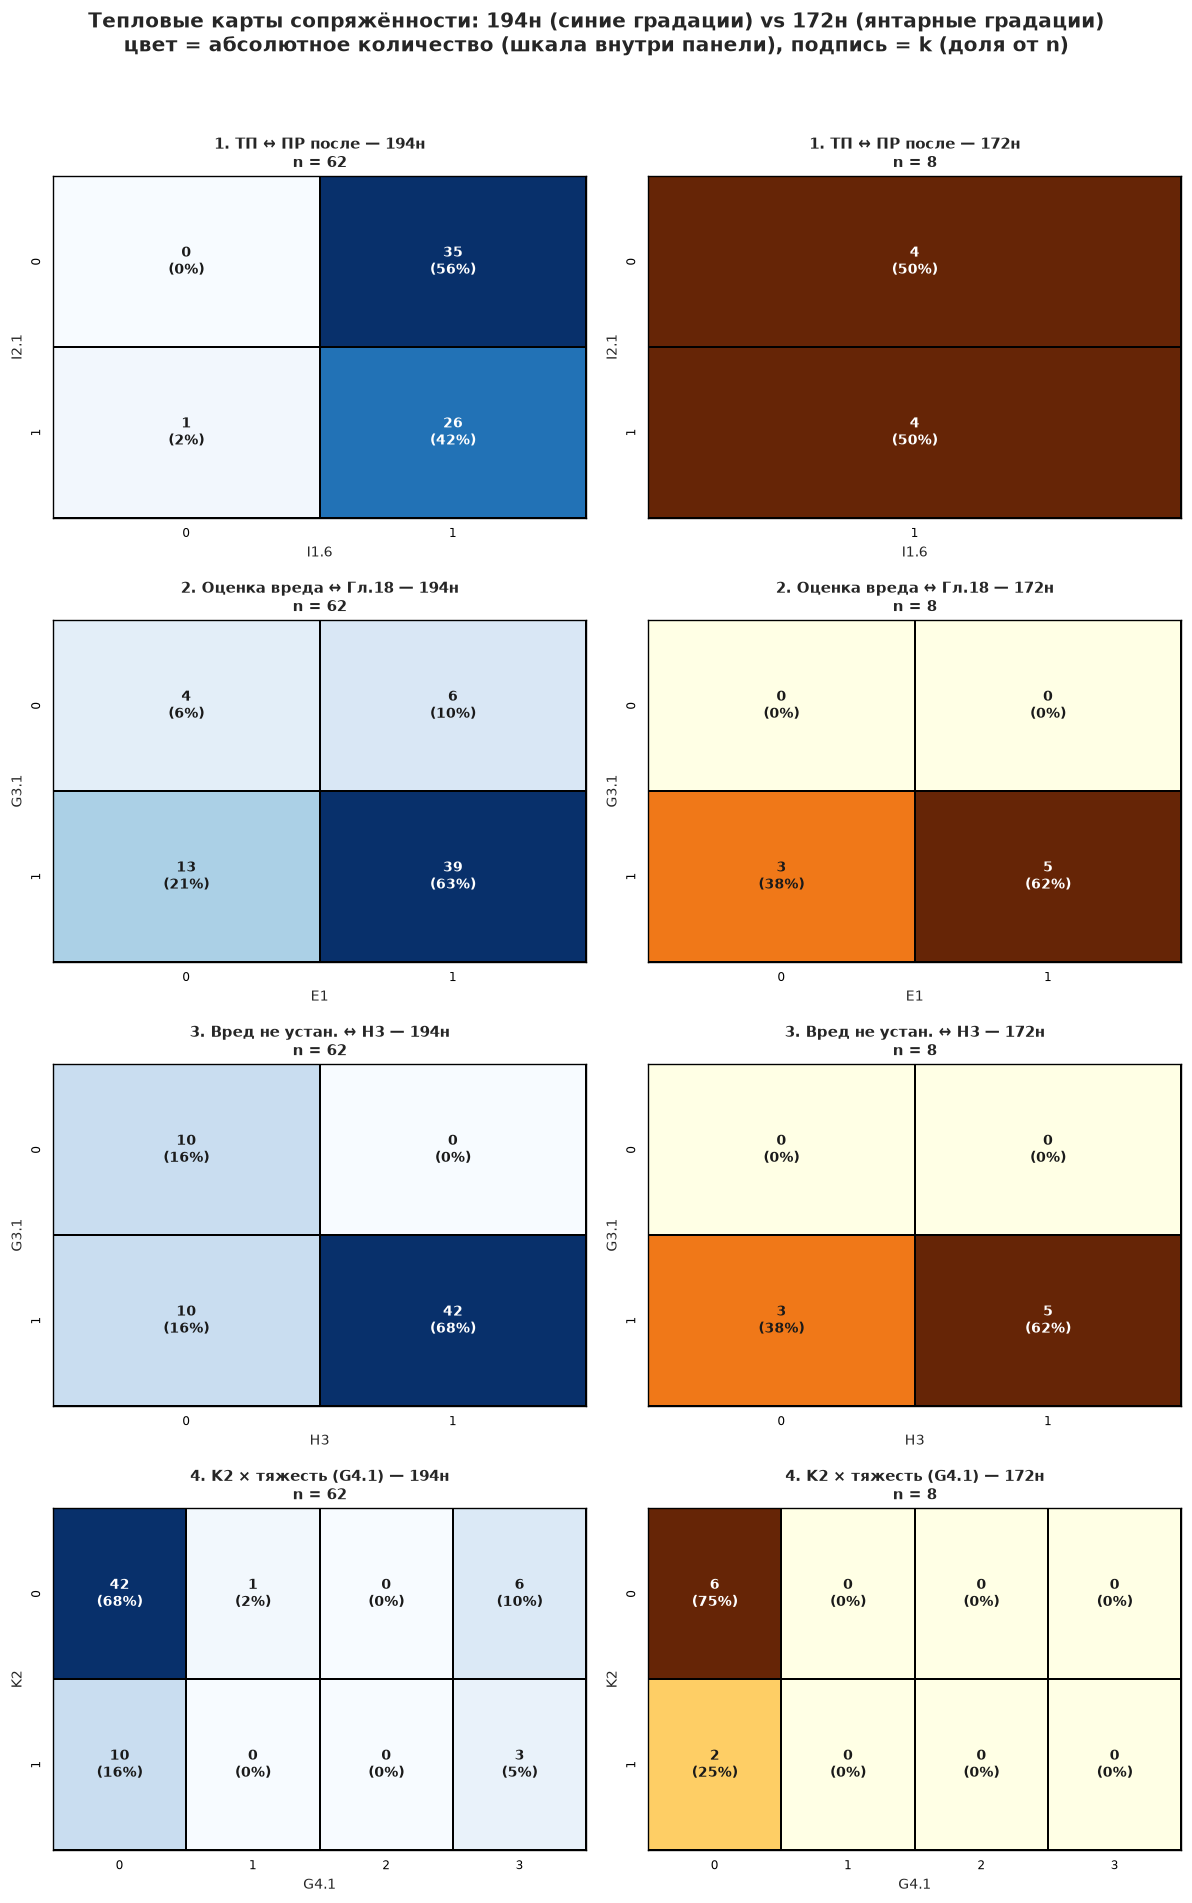

In [24]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import Normalize
from scipy.stats import chi2_contingency, fisher_exact

# --- общий стиль: белая сетка заменена на чёрную ---
sns.set_theme(style="whitegrid", rc={
    "grid.color": "#000000",      # чёрный цвет сетки
    "grid.linestyle": "-",        # сплошные линии
    "grid.linewidth": 0.6,        # тонкие линии
    "axes.edgecolor": "#000000",
    "axes.linewidth": 0.8,
})
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["axes.titlesize"] = 10
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 9
plt.rcParams["xtick.labelsize"] = 8
plt.rcParams["ytick.labelsize"] = 8
plt.rcParams["font.family"] = "DejaVu Sans"

PATH = "Таблица для визуализаций.xlsx"

def load(sheet):
    raw = pd.read_excel(PATH, sheet_name=sheet, header=None)
    d = raw.iloc[5:, 0:9].copy()
    d.columns = ["I1.6","I2.1","G3.1","G4.1","E1","E2","E3","H3","K2"]
    d = d[pd.to_numeric(d["I1.6"], errors="coerce").isin([0,1])]
    return d.apply(pd.to_numeric, errors="coerce")

t194 = load("194н")
t172 = load("172н")

SCHEME = {
    "194н": {
        "cmap": "Blues",
        "on":  "#1f4e79",
        "off": "#dce6f0",
        "line": "#000000",    # внешняя рамка панели — чёрная
    },
    "172н": {
        "cmap": "YlOrBr",
        "on":  "#7a3e00",
        "off": "#fbe8c4",
        "line": "#000000",
    },
}

COLOR_MODE = "count"   # "count" | "global"

def style_heat_axes(ax, c1, c2, title, scheme):
    ax.set_title(title, fontsize=10, weight="bold", pad=6)
    ax.set_xlabel(c2, fontsize=9, labelpad=4)
    ax.set_ylabel(c1, fontsize=9, labelpad=4)
    ax.tick_params(axis="both", labelsize=8, length=3,
                   colors="#000", width=0.8)
    for s in ax.spines.values():
        s.set_visible(True)
        s.set_linewidth(0.9)
        s.set_color("#000000")
    # сетка под клетками
    ax.set_axisbelow(True)
    ax.grid(True, which="major", color="#000000", linewidth=0.5, alpha=0.7)

def ct_heat(ax, df, c1, c2, title, scheme, values=None, mode=COLOR_MODE):
    ct = pd.crosstab(df[c1].fillna(0).astype(int),
                     df[c2].fillna(0).astype(int))
    if values is not None:
        ct = ct.reindex(columns=values, fill_value=0)
    ct = ct.reindex(index=[0, 1], fill_value=0)

    n = int(ct.values.sum())
    counts = ct.values.astype(float)

    if mode == "global":
        mat = counts / n if n > 0 else counts
        vmax = mat.max() if mat.max() > 0 else 1.0
    else:
        mat = counts
        vmax = counts.max() if counts.max() > 0 else 1.0

    annot = (ct.astype(int).astype(str)
             + "\n(" + (counts / max(n, 1) * 100).round(0).astype(int).astype(str) + "%)")

    sns.heatmap(mat, annot=annot, fmt="", cmap=scheme["cmap"],
                vmin=0, vmax=vmax, cbar=False, ax=ax,
                annot_kws={"fontsize": 9, "fontweight": "bold"},
                linewidths=1.2, linecolor="black",   # ← чёрные линии между полями
                xticklabels=[str(v) for v in ct.columns],
                yticklabels=["0", "1"])

    # цвет текста по яркости фона
    cmap = plt.get_cmap(scheme["cmap"])
    norm = Normalize(vmin=0, vmax=vmax)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            rgba = cmap(norm(mat[i, j]))
            r, g, b = rgba[:3]
            lum = 0.2126*r + 0.7152*g + 0.0722*b
            color = "#ffffff" if lum < 0.5 else "#1a1a1a"
            for text in ax.texts:
                if text.get_position() == (j + 0.5, i + 0.5):
                    text.set_color(color)
                    break

    style_heat_axes(ax, c1, c2, f"{title}\nn = {n}", scheme)
    return ct

BOOL_HYP = {
    "1. ТП ↔ ПР после":        ("I2.1", "I1.6"),
    "2. Оценка вреда ↔ Гл.18": ("G3.1", "E1"),
    "3. Вред не устан. ↔ H3":  ("G3.1", "H3"),
}
HYP4 = ("K2", "G4.1")

fig, axes = plt.subplots(4, 2, figsize=(11, 4.3*4))

for i, (name, (c1, c2)) in enumerate(BOOL_HYP.items()):
    ct_heat(axes[i,0], t194, c1, c2, f"{name} — 194н", SCHEME["194н"])
    ct_heat(axes[i,1], t172, c1, c2, f"{name} — 172н", SCHEME["172н"])

ct_heat(axes[3,0], t194, HYP4[0], HYP4[1],
        "4. K2 × тяжесть (G4.1) — 194н", SCHEME["194н"], values=[0,1,2,3])
ct_heat(axes[3,1], t172, HYP4[0], HYP4[1],
        "4. K2 × тяжесть (G4.1) — 172н", SCHEME["172н"], values=[0,1,2,3])

fig.suptitle(
    "Тепловые карты сопряжённости: 194н (синие градации) vs 172н (янтарные градации)\n"
    "цвет = абсолютное количество (шкала внутри панели), подпись = k (доля от n)",
    weight="bold", fontsize=13, y=1.005
)

plt.tight_layout(rect=[0, 0, 1, 0.985])
plt.savefig("heat_all_2colors.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.savefig("heat_all_2colors.pdf", bbox_inches="tight", facecolor="white")
plt.show()

# Диаграмма 4-х полей

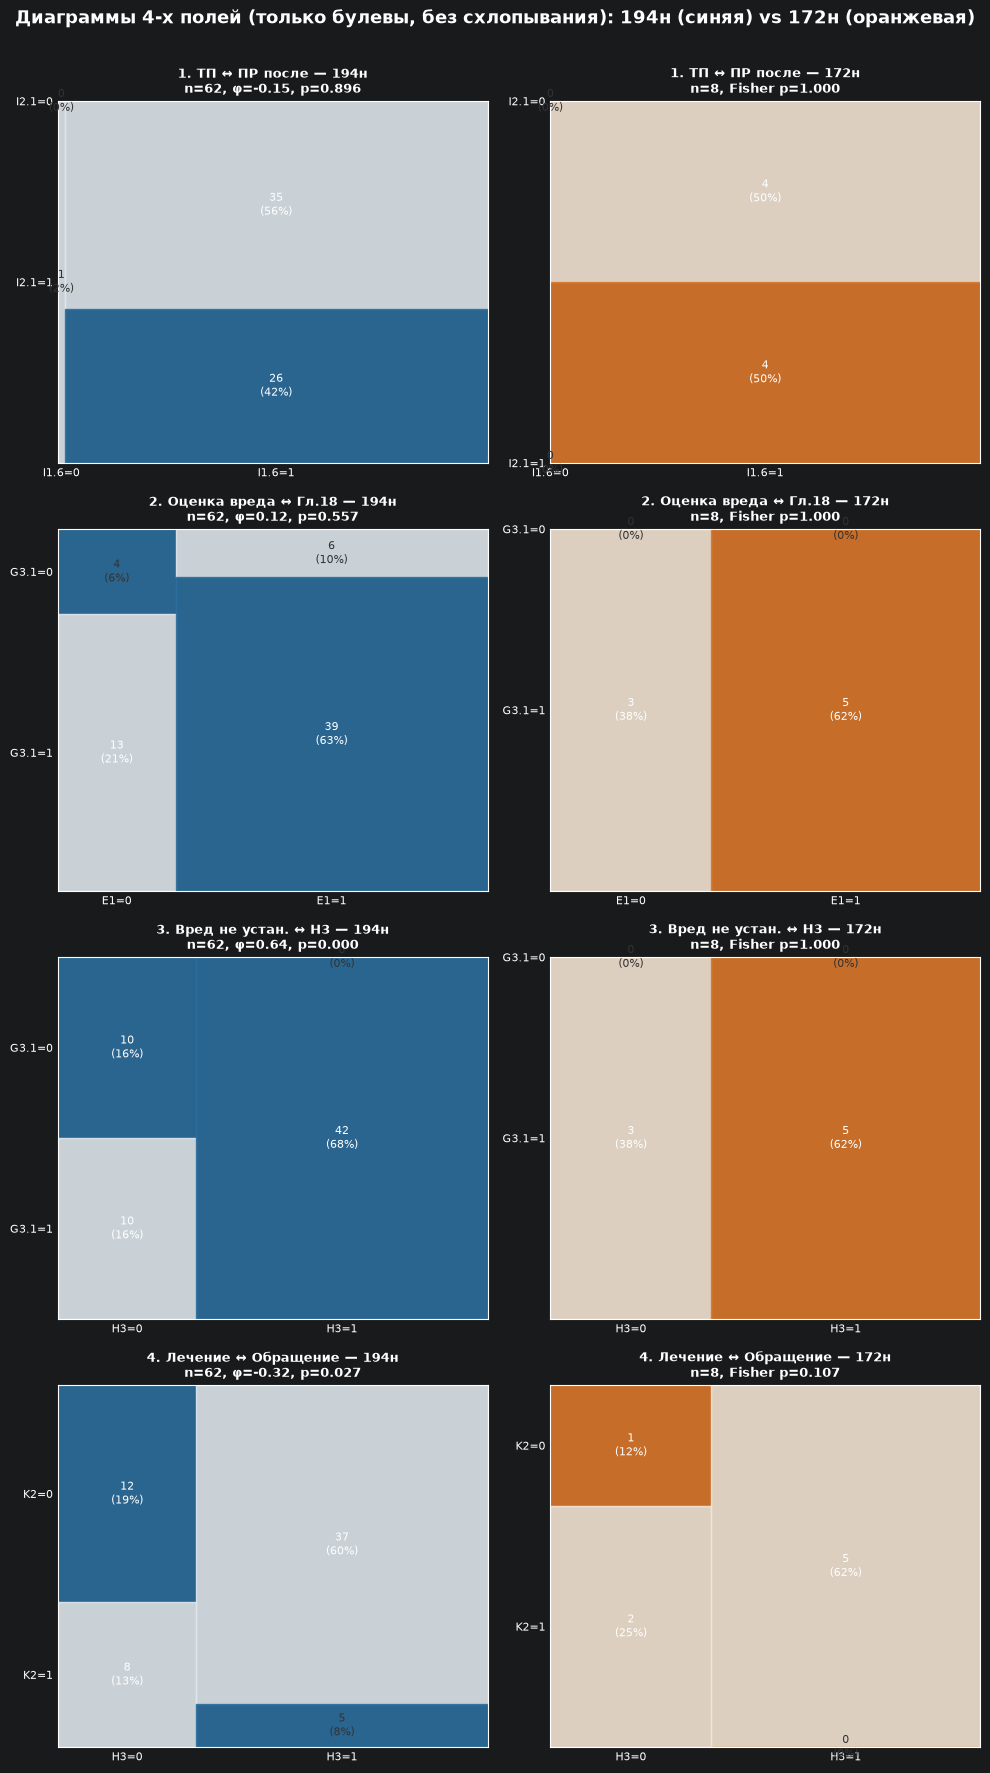

C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\1948532827.py:145: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 1 - h0), w, h0,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\1948532827.py:149: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 0), w, h1,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\1948532827.py:145: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 1 - h0), w, h0,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\1948532827.py:149: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 0), w, h1,


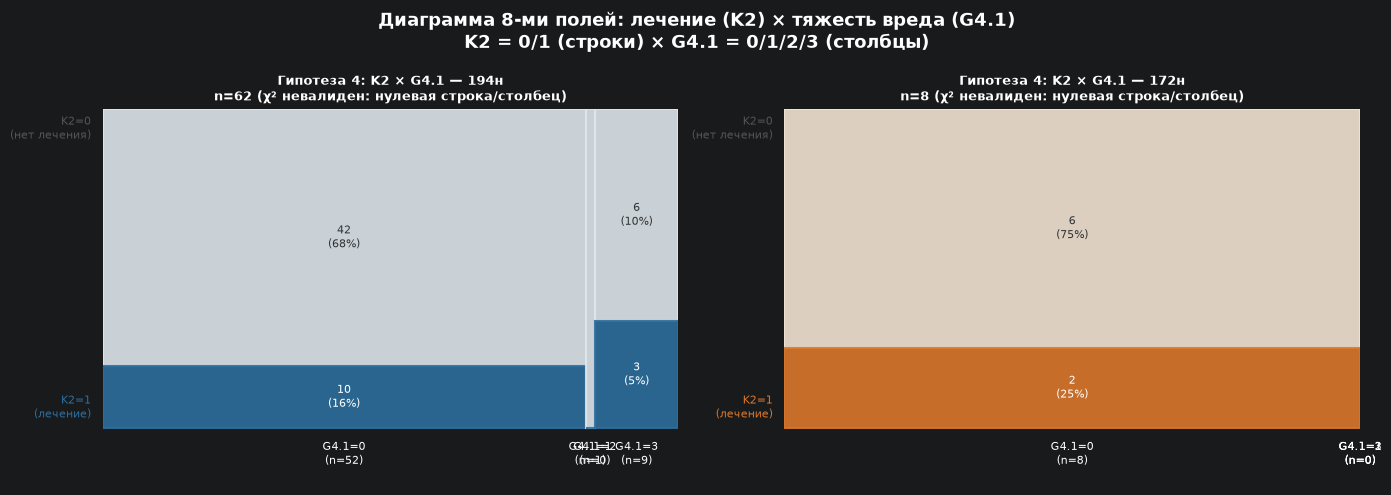

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, fisher_exact

PATH = "Таблица для визуализаций.xlsx"

def load(sheet):
    raw = pd.read_excel(PATH, sheet_name=sheet, header=None)
    d = raw.iloc[5:, 0:9].copy()
    d.columns = ["I1.6","I2.1","G3.1","G4.1","E1","E2","E3","H3","K2"]
    d = d[pd.to_numeric(d["I1.6"], errors="coerce").isin([0,1])]
    return d.apply(pd.to_numeric, errors="coerce")

t194 = load("194н")
t172 = load("172н")

SCHEME = {
    "194н": {"on": "#2c6e9e", "off": "#dfe6ec"},
    "172н": {"on": "#d9772b", "off": "#f3e4d3"},
}

def fourfold(ax, df, c1, c2, title, scheme):
    ct = pd.crosstab(df[c1].fillna(0).astype(int),
                     df[c2].fillna(0).astype(int))\
           .reindex(index=[0,1], columns=[0,1], fill_value=0)
    a, b = ct.loc[0,0], ct.loc[0,1]
    c, d = ct.loc[1,0], ct.loc[1,1]
    n = a + b + c + d
    denom = np.sqrt((a+b)*(c+d)*(a+c)*(b+d))
    phi = (a*d - b*c)/denom if denom > 0 else np.nan

    w0 = (a+c)/n if n else 0.5
    w1 = (b+d)/n if n else 0.5
    h_a = a/(a+c) if (a+c) else 0
    h_b = b/(b+d) if (b+d) else 0
    h_c = c/(a+c) if (a+c) else 0
    h_d = d/(b+d) if (b+d) else 0

    ON, OFF = scheme["on"], scheme["off"]
    ax.add_patch(plt.Rectangle((0, 1-h_a), w0, h_a, color=ON,  alpha=0.9))
    ax.add_patch(plt.Rectangle((w0, 1-h_b), w1, h_b, color=OFF, alpha=0.9))
    ax.add_patch(plt.Rectangle((0, 0),      w0, h_c, color=OFF, alpha=0.9))
    ax.add_patch(plt.Rectangle((w0, 0),     w1, h_d, color=ON,  alpha=0.9))

    def lab(x, y, k):
        color = "white" if k/n > 0.1 else "#333"
        ax.text(x, y, f"{k}\n({k/n*100:.0f}%)", ha="center", va="center",
                fontsize=8, color=color)

    lab(w0/2, 1-h_a/2, a); lab(w0+w1/2, 1-h_b/2, b)
    lab(w0/2, h_c/2, c);   lab(w0+w1/2, h_d/2, d)

    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_xticks([w0/2, w0+w1/2]); ax.set_xticklabels([f"{c2}=0", f"{c2}=1"], fontsize=8)
    ax.set_yticks([1-h_a/2, h_c/2]); ax.set_yticklabels([f"{c1}=0", f"{c1}=1"], fontsize=8)
    ax.tick_params(length=0)

    if n <= 10:
        _, p = fisher_exact([[a,b],[c,d]])
        sub = f"n={n}, Fisher p={p:.3f}"
    else:
        _, p, _, _ = chi2_contingency([[a,b],[c,d]])
        sub = f"n={n}, φ={phi:.2f}, p={p:.3f}"
    ax.set_title(f"{title}\n{sub}", fontsize=9, weight="bold")
    return phi, n

# Все 4 гипотезы — только булевы пары (G4.1 не схлопываем, а не используем в fourfold;
# вместо него — логически связанная пара K2 × H3: лечение ↔ обращение)
BOOL_HYP = {
    "1. ТП ↔ ПР после":        ("I2.1", "I1.6"),
    "2. Оценка вреда ↔ Гл.18": ("G3.1", "E1"),
    "3. Вред не устан. ↔ H3":  ("G3.1", "H3"),
    "4. Лечение ↔ Обращение":  ("K2",   "H3"),
}

fig, axes = plt.subplots(4, 2, figsize=(10, 4.4*4))
for i, (name, (c1, c2)) in enumerate(BOOL_HYP.items()):
    fourfold(axes[i,0], t194, c1, c2, f"{name} — 194н", SCHEME["194н"])
    fourfold(axes[i,1], t172, c1, c2, f"{name} — 172н", SCHEME["172н"])

fig.suptitle("Диаграммы 4-х полей (только булевы, без схлопывания): 194н (синяя) vs 172н (оранжевая)",
             weight="bold", fontsize=13, y=1.005)
plt.tight_layout()
plt.savefig("fourfold_all_2colors.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.savefig("fourfold_all_2colors.pdf", bbox_inches="tight")
plt.show()


import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

PATH = "Таблица для визуализаций.xlsx"

def load(sheet):
    raw = pd.read_excel(PATH, sheet_name=sheet, header=None)
    d = raw.iloc[5:, 0:9].copy()
    d.columns = ["I1.6","I2.1","G3.1","G4.1","E1","E2","E3","H3","K2"]
    d = d[pd.to_numeric(d["I1.6"], errors="coerce").isin([0,1])]
    return d.apply(pd.to_numeric, errors="coerce")

t194 = load("194н")
t172 = load("172н")

SCHEME = {
    "194н": {"on": "#2c6e9e", "off": "#dfe6ec"},
    "172н": {"on": "#d9772b", "off": "#f3e4d3"},
}

def eightfold(ax, df, c1, c2, title, scheme, c2_vals=(0,1,2,3)):
    """
    Диаграмма 8 полей: c1 ∈ {0,1} (строки) × c2 ∈ c2_vals (столбцы).
    Площадь каждой клетки = частота / n.
    Цвет: 'on' если c1=1 (лечение есть), 'off' если c1=0.
    """
    ct = pd.crosstab(df[c1].fillna(0).astype(int),
                     df[c2].fillna(0).astype(int))\
           .reindex(index=[0,1], columns=list(c2_vals), fill_value=0)
    n = int(ct.values.sum())

    if n == 0:
        ax.axis("off")
        ax.text(0.5, 0.5, f"{title}\n\nнет данных", ha="center", va="center",
                fontsize=9, color="#888")
        return ct, n

    # Ширины столбцов = доля каждого значения G4.1
    col_sums = ct.sum(axis=0).values          # [n0, n1, n2, n3]
    widths = col_sums / n
    # Высоты внутри столбца = доля K2=0 и K2=1 среди этого G4.1
    heights = {}
    for j, v in enumerate(c2_vals):
        col_n = col_sums[j]
        if col_n == 0:
            heights[v] = (0, 0)
        else:
            heights[v] = (ct.loc[0, v] / col_n,   # доля K2=0
                          ct.loc[1, v] / col_n)   # доля K2=1

    x = 0
    for j, v in enumerate(c2_vals):
        w = widths[j]
        h0, h1 = heights[v]
        # K2=0 (верхняя часть столбца)
        ax.add_patch(plt.Rectangle((x, 1 - h0), w, h0,
                                   color=scheme["off"], alpha=0.9,
                                   edgecolor="white", linewidth=1.5))
        # K2=1 (нижняя часть столбца)
        ax.add_patch(plt.Rectangle((x, 0), w, h1,
                                   color=scheme["on"], alpha=0.9,
                                   edgecolor="white", linewidth=1.5))
        # Подписи (число + % от n), только если клетка достаточно велика
        k0 = ct.loc[0, v]; k1 = ct.loc[1, v]
        if w > 0.08 and h0 > 0.12:
            ax.text(x + w/2, 1 - h0/2, f"{k0}\n({k0/n*100:.0f}%)",
                    ha="center", va="center", fontsize=8,
                    color="#333" if scheme["off"] != "#ffffff" else "#333")
        if w > 0.08 and h1 > 0.12:
            ax.text(x + w/2, h1/2, f"{k1}\n({k1/n*100:.0f}%)",
                    ha="center", va="center", fontsize=8, color="white")
        # Подпись категории под столбцом
        ax.text(x + w/2, -0.04, f"G4.1={v}\n(n={col_sums[j]})",
                ha="center", va="top", fontsize=8)
        x += w

    # Рамка и оси
    ax.set_xlim(0, 1); ax.set_ylim(-0.18, 1)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

    # Легенда K2
    ax.text(-0.02, 0.98, "K2=0\n(нет лечения)", ha="right", va="top",
            fontsize=8, color="#555")
    ax.text(-0.02, 0.02, "K2=1\n(лечение)", ha="right", va="bottom",
            fontsize=8, color=scheme["on"])

    # Заголовок с χ² (2×4)
    if n > 0 and (ct.values.sum(axis=0) > 0).all() and (ct.values.sum(axis=1) > 0).all():
        try:
            chi2, p, _, _ = chi2_contingency(ct.values)
            cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
            sub = f"n={n}, χ² p={p:.3f}, V={cramers_v:.2f}"
        except ValueError:
            sub = f"n={n} (χ² невалиден: нулевая клетка)"
    else:
        sub = f"n={n} (χ² невалиден: нулевая строка/столбец)"
    ax.set_title(f"{title}\n{sub}", fontsize=9, weight="bold")
    return ct, n

# --- Построение: 194н слева, 172н справа ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ct194, n194 = eightfold(axes[0], t194, "K2", "G4.1",
                        "Гипотеза 4: K2 × G4.1 — 194н",
                        SCHEME["194н"])
ct172, n172 = eightfold(axes[1], t172, "K2", "G4.1",
                        "Гипотеза 4: K2 × G4.1 — 172н",
                        SCHEME["172н"])

fig.suptitle("Диаграмма 8-ми полей: лечение (K2) × тяжесть вреда (G4.1)\n"
             "K2 = 0/1 (строки) × G4.1 = 0/1/2/3 (столбцы)",
             weight="bold", fontsize=13)
plt.tight_layout()
plt.savefig("eightfold_K2_G41.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.savefig("eightfold_K2_G41.pdf", bbox_inches="tight")
plt.show()

# # --- Консольный вывод таблиц для проверки ---
# print("\n194н: K2 × G4.1")
# print(ct194)
# print(f"n = {n194}\n")
# print("172н: K2 × G4.1")
# print(ct172)
# print(f"n = {n172}")

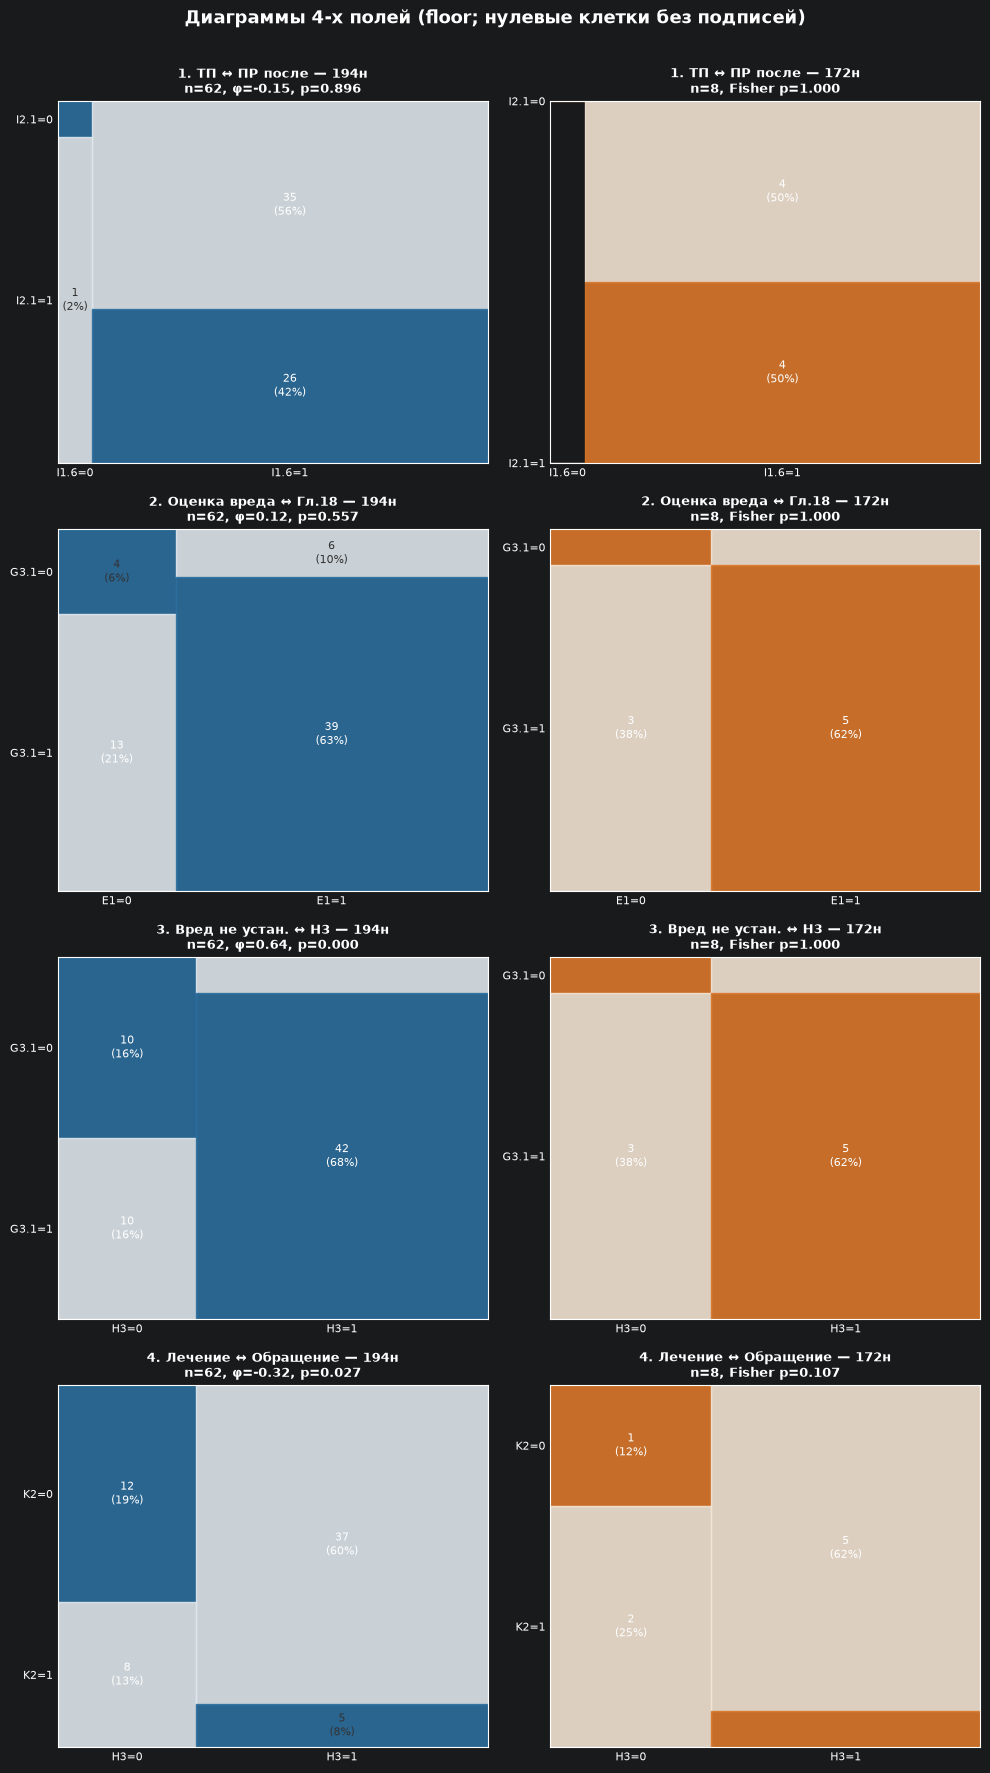

C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\1759161991.py:150: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 1 - h0), w, h0,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\1759161991.py:153: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 0), w, h1,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\1759161991.py:157: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 0), w, 1.0,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\1759161991.py:150: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 1 - h0), w, h0,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\1759161991.py:153: UserWarning: Setting the 'color' property will override the edgecolor or facecolor prope

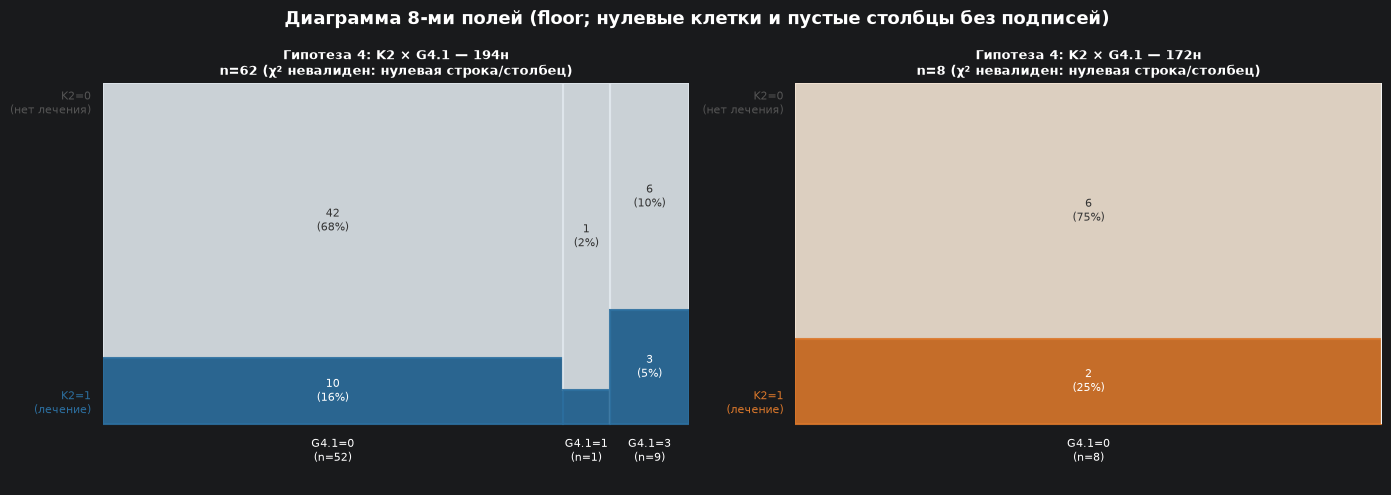

In [8]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, fisher_exact

PATH = "Таблица для визуализаций.xlsx"

MIN_W = 0.08
MIN_H = 0.10

def clamp_shares(vals, minimum):
    vals = np.asarray(vals, dtype=float)
    s = vals.sum()
    if s == 0:
        return vals
    vals = vals / s
    small = vals < minimum
    if not small.any():
        return vals
    deficit = (minimum - vals[small]).sum()
    big = (~small) & (vals > 0)
    if big.any():
        vals[big] -= deficit * vals[big] / vals[big].sum()
    vals[small] = minimum
    vals = np.clip(vals, 0, None)
    total = vals.sum()
    return vals / total if total > 0 else vals

def load(sheet):
    raw = pd.read_excel(PATH, sheet_name=sheet, header=None)
    d = raw.iloc[5:, 0:9].copy()
    d.columns = ["I1.6","I2.1","G3.1","G4.1","E1","E2","E3","H3","K2"]
    d = d[pd.to_numeric(d["I1.6"], errors="coerce").isin([0,1])]
    return d.apply(pd.to_numeric, errors="coerce")

t194 = load("194н")
t172 = load("172н")

SCHEME = {
    "194н": {"on": "#2c6e9e", "off": "#dfe6ec"},
    "172н": {"on": "#d9772b", "off": "#f3e4d3"},
}

def fourfold(ax, df, c1, c2, title, scheme):
    ct = pd.crosstab(df[c1].fillna(0).astype(int),
                     df[c2].fillna(0).astype(int))\
           .reindex(index=[0,1], columns=[0,1], fill_value=0)
    a, b = ct.loc[0,0], ct.loc[0,1]
    c, d = ct.loc[1,0], ct.loc[1,1]
    n = a + b + c + d
    denom = np.sqrt((a+b)*(c+d)*(a+c)*(b+d))
    phi = (a*d - b*c)/denom if denom > 0 else np.nan

    if n:
        w0, w1 = clamp_shares([a+c, b+d], MIN_W)
    else:
        w0, w1 = 0.5, 0.5
    h_a, h_c = clamp_shares([a, c], MIN_H) if (a+c) > 0 else (0.0, 0.0)
    h_b, h_d = clamp_shares([b, d], MIN_H) if (b+d) > 0 else (0.0, 0.0)

    ON, OFF = scheme["on"], scheme["off"]
    ax.add_patch(plt.Rectangle((0, 1-h_a), w0, h_a, color=ON,  alpha=0.9))
    ax.add_patch(plt.Rectangle((w0, 1-h_b), w1, h_b, color=OFF, alpha=0.9))
    ax.add_patch(plt.Rectangle((0, 0),      w0, h_c, color=OFF, alpha=0.9))
    ax.add_patch(plt.Rectangle((w0, 0),     w1, h_d, color=ON,  alpha=0.9))

    def floored(k, part_total, minimum):
        return part_total > 0 and k > 0 and (k / part_total) < minimum

    def lab(x, y, k, fl=False):
        if n == 0 or k == 0:          # <-- скрываем нули
            return
        color = "white" if k/n > 0.1 else "#333"
        mark = "*" if fl else ""
        ax.text(x, y, f"{k}\n({k/n*100:.0f}%){mark}", ha="center", va="center",
                fontsize=8, color=color)

    lab(w0/2, 1-h_a/2, a, floored(a, a+c, MIN_H))
    lab(w0+w1/2, 1-h_b/2, b, floored(b, b+d, MIN_H))
    lab(w0/2, h_c/2, c, floored(c, a+c, MIN_H))
    lab(w0+w1/2, h_d/2, d, floored(d, b+d, MIN_H))

    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_xticks([w0/2, w0+w1/2]); ax.set_xticklabels([f"{c2}=0", f"{c2}=1"], fontsize=8)
    ax.set_yticks([1-h_a/2, h_c/2]); ax.set_yticklabels([f"{c1}=0", f"{c1}=1"], fontsize=8)
    ax.tick_params(length=0)

    if n <= 10:
        _, p = fisher_exact([[a,b],[c,d]])
        sub = f"n={n}, Fisher p={p:.3f}"
    else:
        _, p, _, _ = chi2_contingency([[a,b],[c,d]])
        sub = f"n={n}, φ={phi:.2f}, p={p:.3f}"
    ax.set_title(f"{title}\n{sub}", fontsize=9, weight="bold")
    return phi, n

BOOL_HYP = {
    "1. ТП ↔ ПР после":        ("I2.1", "I1.6"),
    "2. Оценка вреда ↔ Гл.18": ("G3.1", "E1"),
    "3. Вред не устан. ↔ H3":  ("G3.1", "H3"),
    "4. Лечение ↔ Обращение":  ("K2",   "H3"),
}

fig, axes = plt.subplots(4, 2, figsize=(10, 4.4*4))
for i, (name, (c1, c2)) in enumerate(BOOL_HYP.items()):
    fourfold(axes[i,0], t194, c1, c2, f"{name} — 194н", SCHEME["194н"])
    fourfold(axes[i,1], t172, c1, c2, f"{name} — 172н", SCHEME["172н"])

fig.suptitle("Диаграммы 4-х полей (floor; нулевые клетки без подписей)",
             weight="bold", fontsize=13, y=1.005)
plt.tight_layout()
plt.savefig("fourfold_all_2colors.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.savefig("fourfold_all_2colors.pdf", bbox_inches="tight")
plt.show()


# ====== eightfold: нулевые клетки и пустые столбцы без подписей ======
def eightfold(ax, df, c1, c2, title, scheme, c2_vals=(0,1,2,3)):
    ct = pd.crosstab(df[c1].fillna(0).astype(int),
                     df[c2].fillna(0).astype(int))\
           .reindex(index=[0,1], columns=list(c2_vals), fill_value=0)
    n = int(ct.values.sum())
    if n == 0:
        ax.axis("off")
        ax.text(0.5, 0.5, f"{title}\n\nнет данных", ha="center", va="center",
                fontsize=9, color="#888")
        return ct, n

    col_sums = ct.sum(axis=0).values
    nonempty = col_sums > 0
    widths = np.zeros_like(col_sums, dtype=float)
    if nonempty.any():
        widths[nonempty] = clamp_shares(col_sums[nonempty], MIN_W)
    rest = 1.0 - widths.sum()
    if (~nonempty).any() and rest > 0:
        widths[~nonempty] = rest / (~nonempty).sum()

    heights = {}
    for j, v in enumerate(c2_vals):
        if col_sums[j] == 0:
            heights[v] = (0.0, 0.0)
        else:
            heights[v] = tuple(clamp_shares([ct.loc[0, v], ct.loc[1, v]], MIN_H))

    x = 0
    for j, v in enumerate(c2_vals):
        w = widths[j]
        h0, h1 = heights[v]
        # пустой столбец — только серый фон минимальной ширины, без надписей
        if col_sums[j] > 0:
            ax.add_patch(plt.Rectangle((x, 1 - h0), w, h0,
                                       color=scheme["off"], alpha=0.9,
                                       edgecolor="white", linewidth=1.5))
            ax.add_patch(plt.Rectangle((x, 0), w, h1,
                                       color=scheme["on"], alpha=0.9,
                                       edgecolor="white", linewidth=1.5))
        else:
            ax.add_patch(plt.Rectangle((x, 0), w, 1.0,
                                       color="#f5f5f5", alpha=0.9,
                                       edgecolor="white", linewidth=1.5))

        k0 = ct.loc[0, v]; k1 = ct.loc[1, v]

        # подписи только для ненулевых клеток
        if k0 > 0 and w > 0.04 and h0 > 0.10:
            ax.text(x + w/2, 1 - h0/2, f"{k0}\n({k0/n*100:.0f}%)",
                    ha="center", va="center", fontsize=8, color="#333")
        if k1 > 0 and w > 0.04 and h1 > 0.10:
            ax.text(x + w/2, h1/2, f"{k1}\n({k1/n*100:.0f}%)",
                    ha="center", va="center", fontsize=8, color="white")

        # подпись категории — только если столбец непустой
        if col_sums[j] > 0:
            ax.text(x + w/2, -0.04, f"G4.1={v}\n(n={col_sums[j]})",
                    ha="center", va="top", fontsize=8)
        # для полностью пустого столбца подпись категории не рисуется
        x += w

    ax.set_xlim(0, 1); ax.set_ylim(-0.18, 1)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.text(-0.02, 0.98, "K2=0\n(нет лечения)", ha="right", va="top",
            fontsize=8, color="#555")
    ax.text(-0.02, 0.02, "K2=1\n(лечение)", ha="right", va="bottom",
            fontsize=8, color=scheme["on"])

    if n > 0 and (ct.values.sum(axis=0) > 0).all() and (ct.values.sum(axis=1) > 0).all():
        try:
            chi2, p, _, _ = chi2_contingency(ct.values)
            cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
            sub = f"n={n}, χ² p={p:.3f}, V={cramers_v:.2f}"
        except ValueError:
            sub = f"n={n} (χ² невалиден: нулевая клетка)"
    else:
        sub = f"n={n} (χ² невалиден: нулевая строка/столбец)"
    ax.set_title(f"{title}\n{sub}", fontsize=9, weight="bold")
    return ct, n

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ct194, n194 = eightfold(axes[0], t194, "K2", "G4.1",
                        "Гипотеза 4: K2 × G4.1 — 194н", SCHEME["194н"])
ct172, n172 = eightfold(axes[1], t172, "K2", "G4.1",
                        "Гипотеза 4: K2 × G4.1 — 172н", SCHEME["172н"])

fig.suptitle("Диаграмма 8-ми полей (floor; нулевые клетки и пустые столбцы без подписей)",
             weight="bold", fontsize=13)
plt.tight_layout()
plt.savefig("eightfold_K2_G41.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.savefig("eightfold_K2_G41.pdf", bbox_inches="tight")
plt.show()

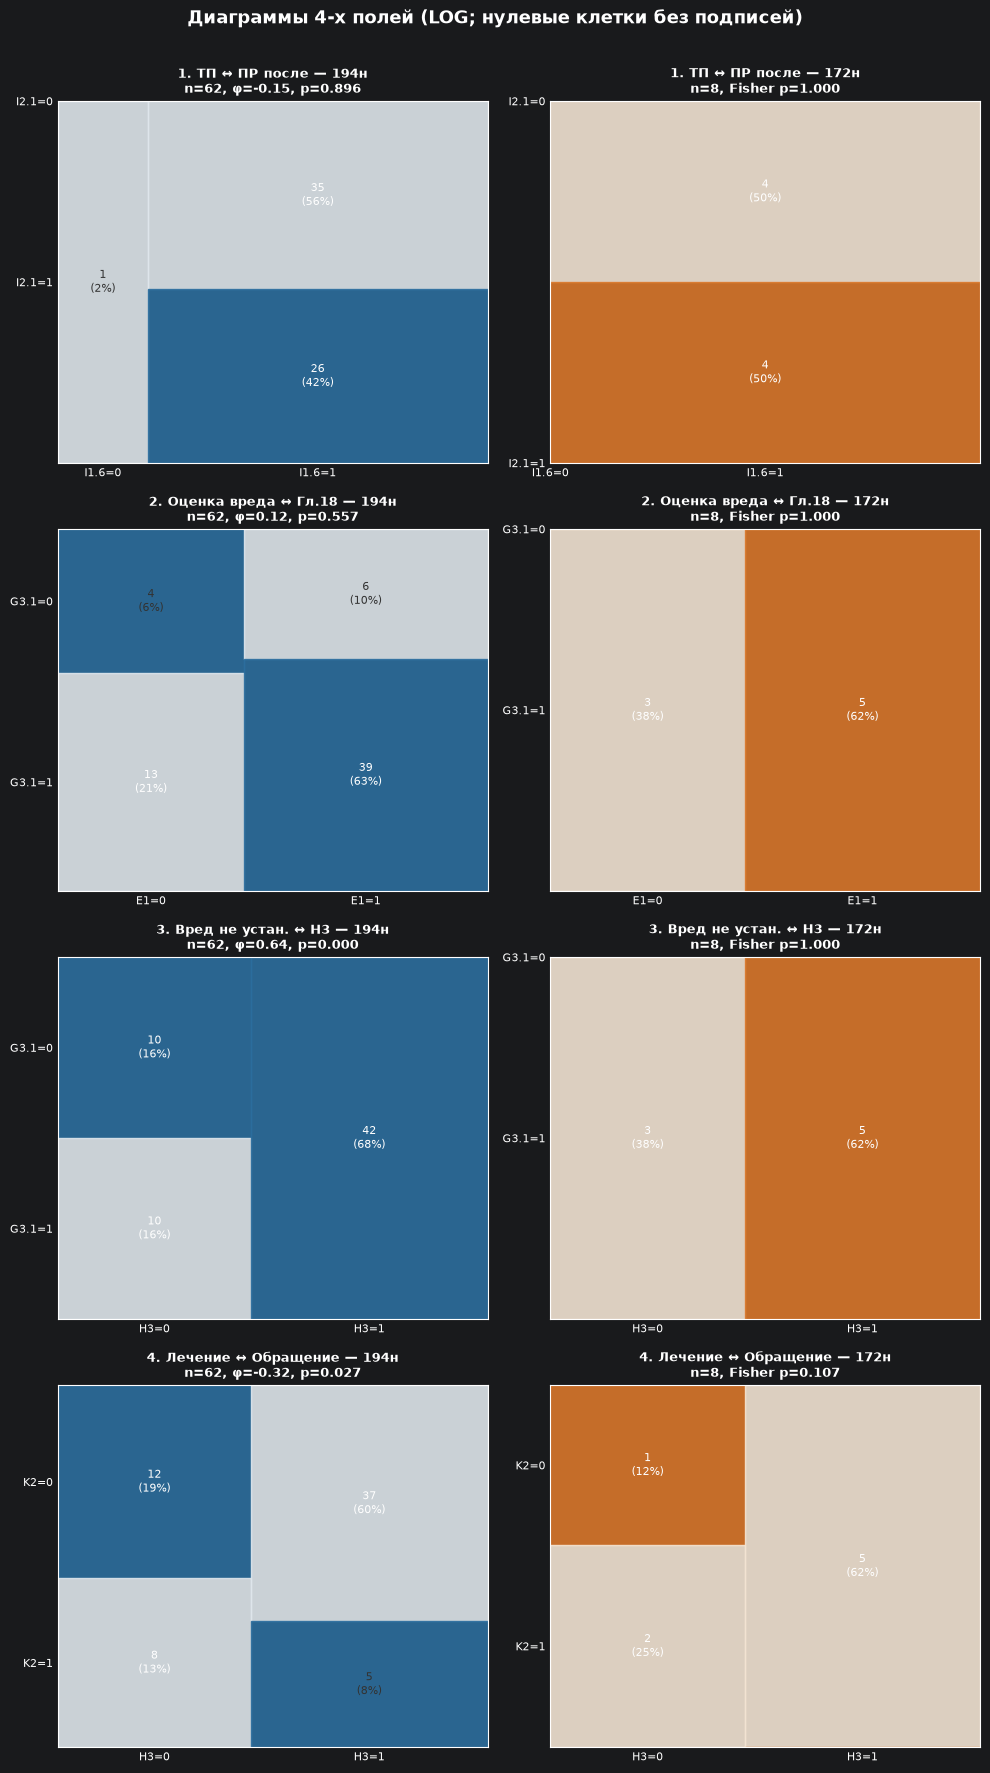

C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\2810034127.py:122: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 1 - h0), w, h0,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\2810034127.py:125: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 0), w, h1,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\2810034127.py:129: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 0), w, 1.0,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\2810034127.py:122: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 1 - h0), w, h0,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\2810034127.py:125: UserWarning: Setting the 'color' property will override the edgecolor or facecolor prope

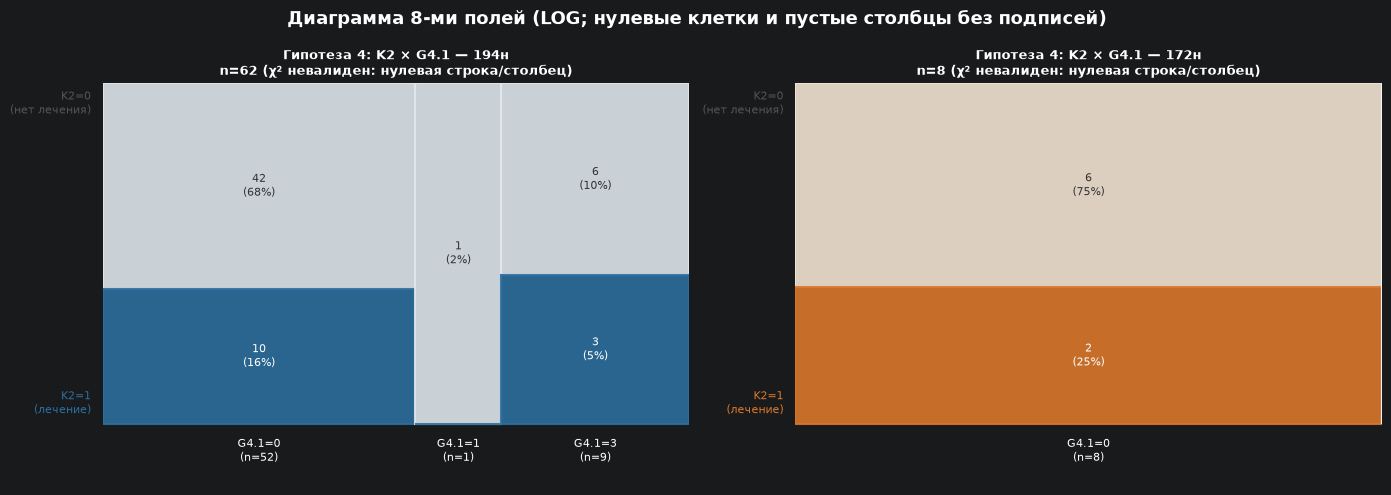

In [9]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, fisher_exact

PATH = "Таблица для визуализаций.xlsx"

LOG_EPS = 1.0

def log_shares(vals):
    v = np.asarray(vals, dtype=float)
    if v.sum() == 0:
        return v
    scaled = np.where(v > 0, np.log1p(v + LOG_EPS), 0.0)
    s = scaled.sum()
    return scaled / s if s > 0 else v

def load(sheet):
    raw = pd.read_excel(PATH, sheet_name=sheet, header=None)
    d = raw.iloc[5:, 0:9].copy()
    d.columns = ["I1.6","I2.1","G3.1","G4.1","E1","E2","E3","H3","K2"]
    d = d[pd.to_numeric(d["I1.6"], errors="coerce").isin([0,1])]
    return d.apply(pd.to_numeric, errors="coerce")

t194 = load("194н")
t172 = load("172н")

SCHEME = {
    "194н": {"on": "#2c6e9e", "off": "#dfe6ec"},
    "172н": {"on": "#d9772b", "off": "#f3e4d3"},
}

def fourfold(ax, df, c1, c2, title, scheme):
    ct = pd.crosstab(df[c1].fillna(0).astype(int),
                     df[c2].fillna(0).astype(int))\
           .reindex(index=[0,1], columns=[0,1], fill_value=0)
    a, b = ct.loc[0,0], ct.loc[0,1]
    c, d = ct.loc[1,0], ct.loc[1,1]
    n = a + b + c + d
    denom = np.sqrt((a+b)*(c+d)*(a+c)*(b+d))
    phi = (a*d - b*c)/denom if denom > 0 else np.nan

    w0, w1 = log_shares([a+c, b+d]) if n else (0.5, 0.5)
    h_a, h_c = log_shares([a, c]) if (a+c) > 0 else (0.0, 0.0)
    h_b, h_d = log_shares([b, d]) if (b+d) > 0 else (0.0, 0.0)

    ON, OFF = scheme["on"], scheme["off"]
    ax.add_patch(plt.Rectangle((0, 1-h_a), w0, h_a, color=ON,  alpha=0.9))
    ax.add_patch(plt.Rectangle((w0, 1-h_b), w1, h_b, color=OFF, alpha=0.9))
    ax.add_patch(plt.Rectangle((0, 0),      w0, h_c, color=OFF, alpha=0.9))
    ax.add_patch(plt.Rectangle((w0, 0),     w1, h_d, color=ON,  alpha=0.9))

    def lab(x, y, k):
        if n == 0 or k == 0:          # <-- скрываем нули
            return
        color = "white" if k/n > 0.1 else "#333"
        ax.text(x, y, f"{k}\n({k/n*100:.0f}%)", ha="center", va="center",
                fontsize=8, color=color)

    lab(w0/2, 1-h_a/2, a); lab(w0+w1/2, 1-h_b/2, b)
    lab(w0/2, h_c/2, c);   lab(w0+w1/2, h_d/2, d)

    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_xticks([w0/2, w0+w1/2]); ax.set_xticklabels([f"{c2}=0", f"{c2}=1"], fontsize=8)
    ax.set_yticks([1-h_a/2, h_c/2]); ax.set_yticklabels([f"{c1}=0", f"{c1}=1"], fontsize=8)
    ax.tick_params(length=0)

    if n <= 10:
        _, p = fisher_exact([[a,b],[c,d]])
        sub = f"n={n}, Fisher p={p:.3f}"
    else:
        _, p, _, _ = chi2_contingency([[a,b],[c,d]])
        sub = f"n={n}, φ={phi:.2f}, p={p:.3f}"
    ax.set_title(f"{title}\n{sub}", fontsize=9, weight="bold")
    return phi, n

BOOL_HYP = {
    "1. ТП ↔ ПР после":        ("I2.1", "I1.6"),
    "2. Оценка вреда ↔ Гл.18": ("G3.1", "E1"),
    "3. Вред не устан. ↔ H3":  ("G3.1", "H3"),
    "4. Лечение ↔ Обращение":  ("K2",   "H3"),
}

fig, axes = plt.subplots(4, 2, figsize=(10, 4.4*4))
for i, (name, (c1, c2)) in enumerate(BOOL_HYP.items()):
    fourfold(axes[i,0], t194, c1, c2, f"{name} — 194н", SCHEME["194н"])
    fourfold(axes[i,1], t172, c1, c2, f"{name} — 172н", SCHEME["172н"])

fig.suptitle("Диаграммы 4-х полей (LOG; нулевые клетки без подписей)",
             weight="bold", fontsize=13, y=1.005)
plt.tight_layout()
plt.savefig("fourfold_all_2colors.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.savefig("fourfold_all_2colors.pdf", bbox_inches="tight")
plt.show()


# ====== eightfold с log-масштабом + скрытие нулей ======
def eightfold(ax, df, c1, c2, title, scheme, c2_vals=(0,1,2,3)):
    ct = pd.crosstab(df[c1].fillna(0).astype(int),
                     df[c2].fillna(0).astype(int))\
           .reindex(index=[0,1], columns=list(c2_vals), fill_value=0)
    n = int(ct.values.sum())
    if n == 0:
        ax.axis("off")
        ax.text(0.5, 0.5, f"{title}\n\nнет данных", ha="center", va="center",
                fontsize=9, color="#888")
        return ct, n

    col_sums = ct.sum(axis=0).values
    widths = log_shares(col_sums)
    heights = {}
    for j, v in enumerate(c2_vals):
        if col_sums[j] == 0:
            heights[v] = (0.0, 0.0)
        else:
            heights[v] = tuple(log_shares([ct.loc[0, v], ct.loc[1, v]]))

    x = 0
    for j, v in enumerate(c2_vals):
        w = widths[j]
        h0, h1 = heights[v]
        if col_sums[j] > 0:
            ax.add_patch(plt.Rectangle((x, 1 - h0), w, h0,
                                       color=scheme["off"], alpha=0.9,
                                       edgecolor="white", linewidth=1.5))
            ax.add_patch(plt.Rectangle((x, 0), w, h1,
                                       color=scheme["on"], alpha=0.9,
                                       edgecolor="white", linewidth=1.5))
        else:
            ax.add_patch(plt.Rectangle((x, 0), w, 1.0,
                                       color="#f5f5f5", alpha=0.9,
                                       edgecolor="white", linewidth=1.5))

        k0 = ct.loc[0, v]; k1 = ct.loc[1, v]
        if k0 > 0 and w > 0.06 and h0 > 0.12:
            ax.text(x + w/2, 1 - h0/2, f"{k0}\n({k0/n*100:.0f}%)",
                    ha="center", va="center", fontsize=8, color="#333")
        if k1 > 0 and w > 0.06 and h1 > 0.12:
            ax.text(x + w/2, h1/2, f"{k1}\n({k1/n*100:.0f}%)",
                    ha="center", va="center", fontsize=8, color="white")

        if col_sums[j] > 0:
            ax.text(x + w/2, -0.04, f"G4.1={v}\n(n={col_sums[j]})",
                    ha="center", va="top", fontsize=8)
        x += w

    ax.set_xlim(0, 1); ax.set_ylim(-0.18, 1)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.text(-0.02, 0.98, "K2=0\n(нет лечения)", ha="right", va="top",
            fontsize=8, color="#555")
    ax.text(-0.02, 0.02, "K2=1\n(лечение)", ha="right", va="bottom",
            fontsize=8, color=scheme["on"])

    if n > 0 and (ct.values.sum(axis=0) > 0).all() and (ct.values.sum(axis=1) > 0).all():
        try:
            chi2, p, _, _ = chi2_contingency(ct.values)
            cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
            sub = f"n={n}, χ² p={p:.3f}, V={cramers_v:.2f}"
        except ValueError:
            sub = f"n={n} (χ² невалиден: нулевая клетка)"
    else:
        sub = f"n={n} (χ² невалиден: нулевая строка/столбец)"
    ax.set_title(f"{title}\n{sub}", fontsize=9, weight="bold")
    return ct, n

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ct194, n194 = eightfold(axes[0], t194, "K2", "G4.1",
                        "Гипотеза 4: K2 × G4.1 — 194н", SCHEME["194н"])
ct172, n172 = eightfold(axes[1], t172, "K2", "G4.1",
                        "Гипотеза 4: K2 × G4.1 — 172н", SCHEME["172н"])

fig.suptitle("Диаграмма 8-ми полей (LOG; нулевые клетки и пустые столбцы без подписей)",
             weight="bold", fontsize=13)
plt.tight_layout()
plt.savefig("eightfold_K2_G41.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.savefig("eightfold_K2_G41.pdf", bbox_inches="tight")
plt.show()

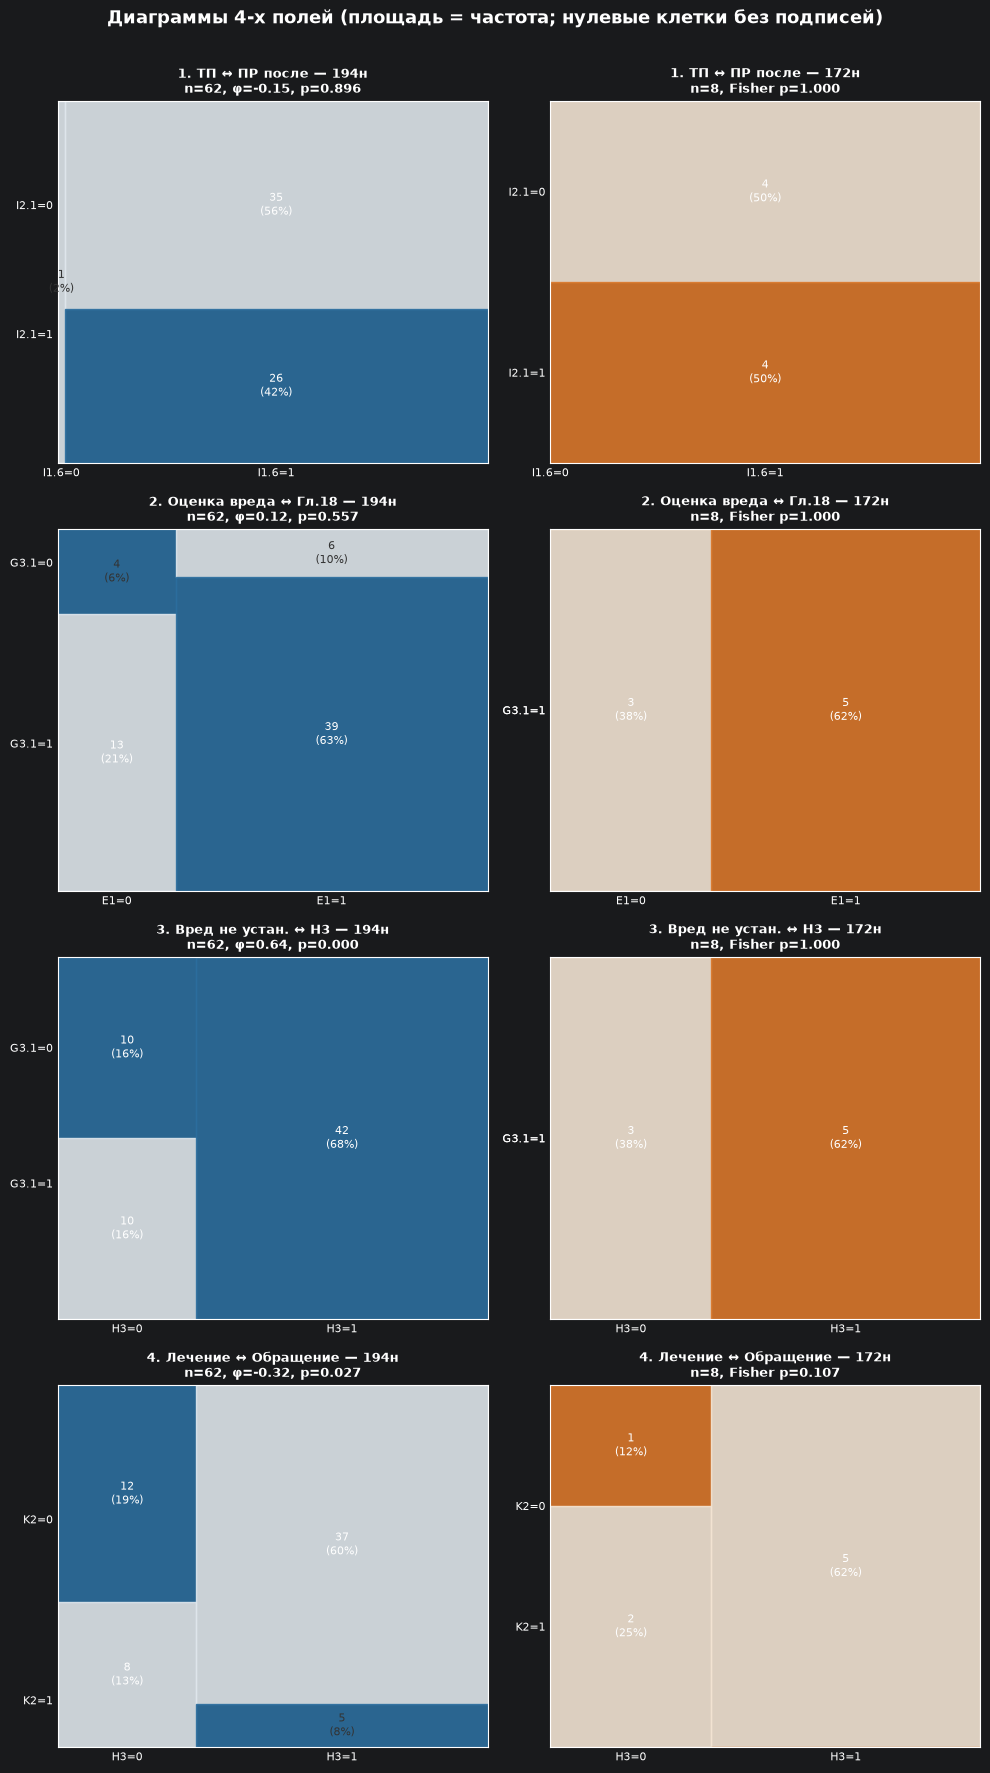

C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\2263624448.py:157: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 1 - h0), w, h0,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\2263624448.py:160: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 0), w, h1,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\2263624448.py:164: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 0), w, 1.0,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\2263624448.py:157: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 1 - h0), w, h0,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\2263624448.py:160: UserWarning: Setting the 'color' property will override the edgecolor or facecolor prope

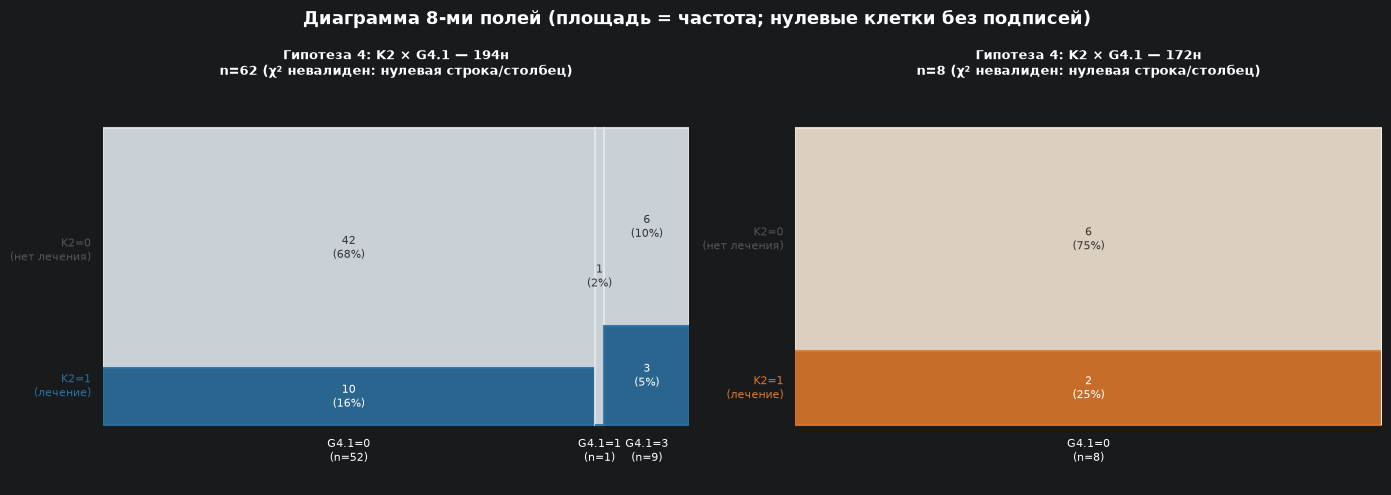

In [11]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, fisher_exact

PATH = "Таблица для визуализаций.xlsx"

MIN_AREA_LABEL = 0.012   # доля площади, ниже которой подпись рисуется выноской
MIN_W_VISIBLE  = 0.01    # минимальная ширина столбца для «нормальной» подписи

def load(sheet):
    raw = pd.read_excel(PATH, sheet_name=sheet, header=None)
    d = raw.iloc[5:, 0:9].copy()
    d.columns = ["I1.6","I2.1","G3.1","G4.1","E1","E2","E3","H3","K2"]
    d = d[pd.to_numeric(d["I1.6"], errors="coerce").isin([0,1])]
    return d.apply(pd.to_numeric, errors="coerce")

t194 = load("194н")
t172 = load("172н")

SCHEME = {
    "194н": {"on": "#2c6e9e", "off": "#dfe6ec"},
    "172н": {"on": "#d9772b", "off": "#f3e4d3"},
}

def label_or_arrow(ax, x, y, k, n, color="white", fs=8):
    """Подпись внутри клетки, либо выноска, если доля мала. Нули скрываются."""
    if n == 0 or k == 0:
        return
    share = k / n
    txt = f"{k}\n({share*100:.0f}%)"
    if share >= MIN_AREA_LABEL:
        ax.text(x, y, txt, ha="center", va="center", fontsize=fs, color=color)
    else:
        ax.annotate(txt,
                    xy=(x, y), xytext=(x, min(1.0, y + 0.10)),
                    textcoords="data", ha="center", va="bottom",
                    fontsize=fs - 1, color="#333",
                    arrowprops=dict(arrowstyle="-", lw=0.6, color="#888"))

def fourfold(ax, df, c1, c2, title, scheme):
    ct = pd.crosstab(df[c1].fillna(0).astype(int),
                     df[c2].fillna(0).astype(int))\
           .reindex(index=[0,1], columns=[0,1], fill_value=0)
    a, b = ct.loc[0,0], ct.loc[0,1]
    c, d = ct.loc[1,0], ct.loc[1,1]
    n = a + b + c + d
    denom = np.sqrt((a+b)*(c+d)*(a+c)*(b+d))
    phi = (a*d - b*c)/denom if denom > 0 else np.nan

    # --- геометрия ---
    w0 = (a+c)/n if n else 0.5
    w1 = (b+d)/n if n else 0.5
    h_a = a/(a+c) if (a+c) else 0
    h_b = b/(b+d) if (b+d) else 0
    h_c = c/(a+c) if (a+c) else 0
    h_d = d/(b+d) if (b+d) else 0

    ON, OFF = scheme["on"], scheme["off"]
    # столбец 0: сверху ON (a), снизу OFF (c)
    ax.add_patch(plt.Rectangle((0, 1-h_a), w0, h_a, color=ON,  alpha=0.9))
    # столбец 1: сверху OFF (b), снизу ON (d)
    ax.add_patch(plt.Rectangle((w0, 1-h_b), w1, h_b, color=OFF, alpha=0.9))
    ax.add_patch(plt.Rectangle((0, 0),      w0, h_c, color=OFF, alpha=0.9))
    ax.add_patch(plt.Rectangle((w0, 0),     w1, h_d, color=ON,  alpha=0.9))

    # --- подписи клеток ---
    label_or_arrow(ax, w0/2, 1-h_a/2, a, n, color="white" if a/n > 0.1 else "#333")
    label_or_arrow(ax, w0+w1/2, 1-h_b/2, b, n, color="white" if b/n > 0.1 else "#333")
    label_or_arrow(ax, w0/2, h_c/2, c, n, color="white" if c/n > 0.1 else "#333")
    label_or_arrow(ax, w0+w1/2, h_d/2, d, n, color="white" if d/n > 0.1 else "#333")

    # --- подписи осей: центр видимой части строки/столбца ---
    # x-центр для c2=0 = w0/2; для c2=1 = w0 + w1/2
    # y-центр для c1=0 = 1 - h_a/2 (верхняя часть) — но если a=0 и c>0, то c1=0
    #   всё ещё занимает верх (h_a=0 => y=1), а строка c1=1 занимает весь низ (h_c=1 => y=0.5)
    # поэтому считаем центр как среднее видимых прямоугольников:
    def x_center_col0(): return w0/2 if w0 > 0 else 0.0
    def x_center_col1(): return w0 + w1/2 if w1 > 0 else 1.0
    def y_center_row0():
        # c1=0 — верхние прямоугольники a (x∈[0,w0], y∈[1-h_a,1]) и b (x∈[w0,1], y∈[1-h_b,1])
        ys = []
        if h_a > 0: ys.append(1 - h_a/2)
        if h_b > 0: ys.append(1 - h_b/2)
        return float(np.mean(ys)) if ys else 0.5
    def y_center_row1():
        ys = []
        if h_c > 0: ys.append(h_c/2)
        if h_d > 0: ys.append(h_d/2)
        return float(np.mean(ys)) if ys else 0.5

    xt = [x_center_col0(), x_center_col1()]
    yt = [y_center_row0(), y_center_row1()]

    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_xticks(xt); ax.set_xticklabels([f"{c2}=0", f"{c2}=1"], fontsize=8)
    ax.set_yticks(yt); ax.set_yticklabels([f"{c1}=0", f"{c1}=1"], fontsize=8)
    ax.tick_params(length=0)

    # --- статистика ---
    if n <= 10:
        _, p = fisher_exact([[a,b],[c,d]])
        sub = f"n={n}, Fisher p={p:.3f}"
    else:
        _, p, _, _ = chi2_contingency([[a,b],[c,d]])
        sub = f"n={n}, φ={phi:.2f}, p={p:.3f}"
    ax.set_title(f"{title}\n{sub}", fontsize=9, weight="bold")
    return phi, n

BOOL_HYP = {
    "1. ТП ↔ ПР после":        ("I2.1", "I1.6"),
    "2. Оценка вреда ↔ Гл.18": ("G3.1", "E1"),
    "3. Вред не устан. ↔ H3":  ("G3.1", "H3"),
    "4. Лечение ↔ Обращение":  ("K2",   "H3"),
}

fig, axes = plt.subplots(4, 2, figsize=(10, 4.4*4))
for i, (name, (c1, c2)) in enumerate(BOOL_HYP.items()):
    fourfold(axes[i,0], t194, c1, c2, f"{name} — 194н", SCHEME["194н"])
    fourfold(axes[i,1], t172, c1, c2, f"{name} — 172н", SCHEME["172н"])

fig.suptitle("Диаграммы 4-х полей (площадь = частота; нулевые клетки без подписей)",
             weight="bold", fontsize=13, y=1.005)
plt.tight_layout()
plt.savefig("fourfold_all_2colors.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.savefig("fourfold_all_2colors.pdf", bbox_inches="tight")
plt.show()


# ====== eightfold с выносками + скрытие нулей + корректные оси ======
def eightfold(ax, df, c1, c2, title, scheme, c2_vals=(0,1,2,3)):
    ct = pd.crosstab(df[c1].fillna(0).astype(int),
                     df[c2].fillna(0).astype(int))\
           .reindex(index=[0,1], columns=list(c2_vals), fill_value=0)
    n = int(ct.values.sum())
    if n == 0:
        ax.axis("off")
        ax.text(0.5, 0.5, f"{title}\n\nнет данных", ha="center", va="center",
                fontsize=9, color="#888")
        return ct, n

    col_sums = ct.sum(axis=0).values
    widths = col_sums / n
    heights = {}
    for j, v in enumerate(c2_vals):
        if col_sums[j] == 0:
            heights[v] = (0.0, 0.0)
        else:
            heights[v] = (ct.loc[0, v] / col_sums[j],
                          ct.loc[1, v] / col_sums[j])

    x = 0
    col_centers = []      # центры столбцов для подписей оси X
    for j, v in enumerate(c2_vals):
        w = widths[j]
        h0, h1 = heights[v]
        if col_sums[j] > 0:
            ax.add_patch(plt.Rectangle((x, 1 - h0), w, h0,
                                       color=scheme["off"], alpha=0.9,
                                       edgecolor="white", linewidth=1.5))
            ax.add_patch(plt.Rectangle((x, 0), w, h1,
                                       color=scheme["on"], alpha=0.9,
                                       edgecolor="white", linewidth=1.5))
        else:
            ax.add_patch(plt.Rectangle((x, 0), w, 1.0,
                                       color="#f5f5f5", alpha=0.9,
                                       edgecolor="white", linewidth=1.5))

        k0 = ct.loc[0, v]; k1 = ct.loc[1, v]

        # --- подписи клеток ---
        if col_sums[j] > 0:
            if w < MIN_W_VISIBLE:
                ax.annotate(f"G4.1={v}: {k0}+{k1} (n={col_sums[j]})",
                            xy=(x + w/2, 0.5),
                            xytext=(x + w/2, 1.05), textcoords="data",
                            ha="center", va="bottom", fontsize=7, color="#333",
                            arrowprops=dict(arrowstyle="-", lw=0.6, color="#888"))
            else:
                if k0 > 0:
                    if h0 * w >= MIN_AREA_LABEL:
                        ax.text(x + w/2, 1 - h0/2, f"{k0}\n({k0/n*100:.0f}%)",
                                ha="center", va="center", fontsize=8, color="#333")
                    else:
                        ax.annotate(f"{k0} ({k0/n*100:.0f}%)",
                                    xy=(x + w/2, 1 - h0/2),
                                    xytext=(x + w/2, 1 - h0 + 0.08),
                                    textcoords="data", ha="center", va="bottom",
                                    fontsize=7, color="#333",
                                    arrowprops=dict(arrowstyle="-", lw=0.5, color="#888"))
                if k1 > 0:
                    if h1 * w >= MIN_AREA_LABEL:
                        ax.text(x + w/2, h1/2, f"{k1}\n({k1/n*100:.0f}%)",
                                ha="center", va="center", fontsize=8, color="white")
                    else:
                        ax.annotate(f"{k1} ({k1/n*100:.0f}%)",
                                    xy=(x + w/2, h1/2),
                                    xytext=(x + w/2, max(-0.08, h1 - 0.10)),
                                    textcoords="data", ha="center", va="top",
                                    fontsize=7, color="#333",
                                    arrowprops=dict(arrowstyle="-", lw=0.5, color="#888"))

            # --- подпись категории под столбцом ---
            ax.text(x + w/2, -0.04, f"G4.1={v}\n(n={col_sums[j]})",
                    ha="center", va="top", fontsize=8)
        # пустой столбец — подпись не рисуется

        col_centers.append((x + w/2, w))
        x += w

    # --- ось Y: центры видимых частей строк ---
    def y_center_row0():
        ys = []
        if heights[c2_vals[0]][0] > 0:  # a
            ys.append(1 - heights[c2_vals[0]][0] / 2)
        # аналогично для b и т.д. — но в eightfold «строка 0» это K2=0,
        # она размазана по всем столбцам; берём среднее по всем столбцам
        ys = []
        for j, v in enumerate(c2_vals):
            if col_sums[j] == 0: continue
            h0, h1 = heights[v]
            if h0 > 0: ys.append(1 - h0 / 2)
        return float(np.mean(ys)) if ys else 0.5
    def y_center_row1():
        ys = []
        for j, v in enumerate(c2_vals):
            if col_sums[j] == 0: continue
            h0, h1 = heights[v]
            if h1 > 0: ys.append(h1 / 2)
        return float(np.mean(ys)) if ys else 0.5

    ax.set_xlim(0, 1); ax.set_ylim(-0.20, 1.15)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

    # подписи K2 (слева) — по центрам строк
    ax.text(-0.02, y_center_row0(), "K2=0\n(нет лечения)", ha="right", va="center",
            fontsize=8, color="#555")
    ax.text(-0.02, y_center_row1(), "K2=1\n(лечение)", ha="right", va="center",
            fontsize=8, color=scheme["on"])

    if n > 0 and (ct.values.sum(axis=0) > 0).all() and (ct.values.sum(axis=1) > 0).all():
        try:
            chi2, p, _, _ = chi2_contingency(ct.values)
            cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
            sub = f"n={n}, χ² p={p:.3f}, V={cramers_v:.2f}"
        except ValueError:
            sub = f"n={n} (χ² невалиден: нулевая клетка)"
    else:
        sub = f"n={n} (χ² невалиден: нулевая строка/столбец)"
    ax.set_title(f"{title}\n{sub}", fontsize=9, weight="bold")
    return ct, n

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ct194, n194 = eightfold(axes[0], t194, "K2", "G4.1",
                        "Гипотеза 4: K2 × G4.1 — 194н", SCHEME["194н"])
ct172, n172 = eightfold(axes[1], t172, "K2", "G4.1",
                        "Гипотеза 4: K2 × G4.1 — 172н", SCHEME["172н"])

fig.suptitle("Диаграмма 8-ми полей (площадь = частота; нулевые клетки без подписей)",
             weight="bold", fontsize=13)
plt.tight_layout()
plt.savefig("eightfold_K2_G41.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.savefig("eightfold_K2_G41.pdf", bbox_inches="tight")
plt.show()

# ВАРИАНТ С ПОДПИСЯМИ В ПОЛЯХ

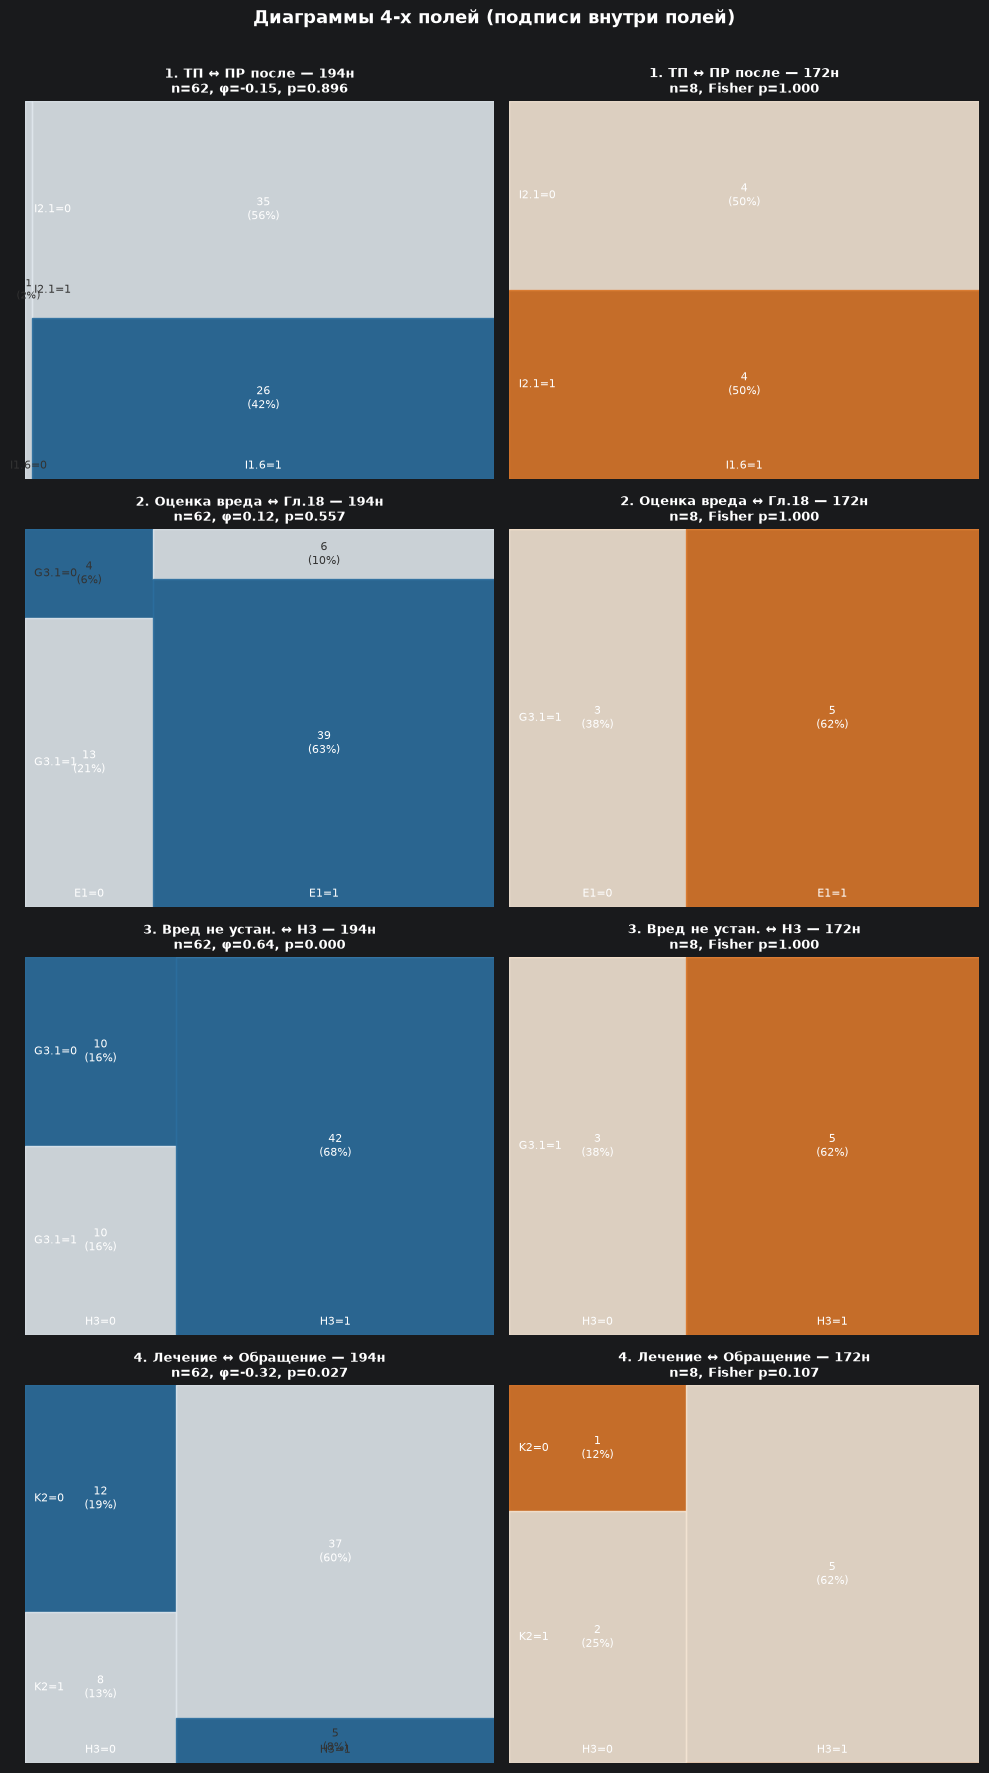

C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\152225615.py:156: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 1 - h0), w, h0,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\152225615.py:159: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 0), w, h1,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\152225615.py:163: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 0), w, 1.0,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\152225615.py:156: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle((x, 1 - h0), w, h0,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\152225615.py:159: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties

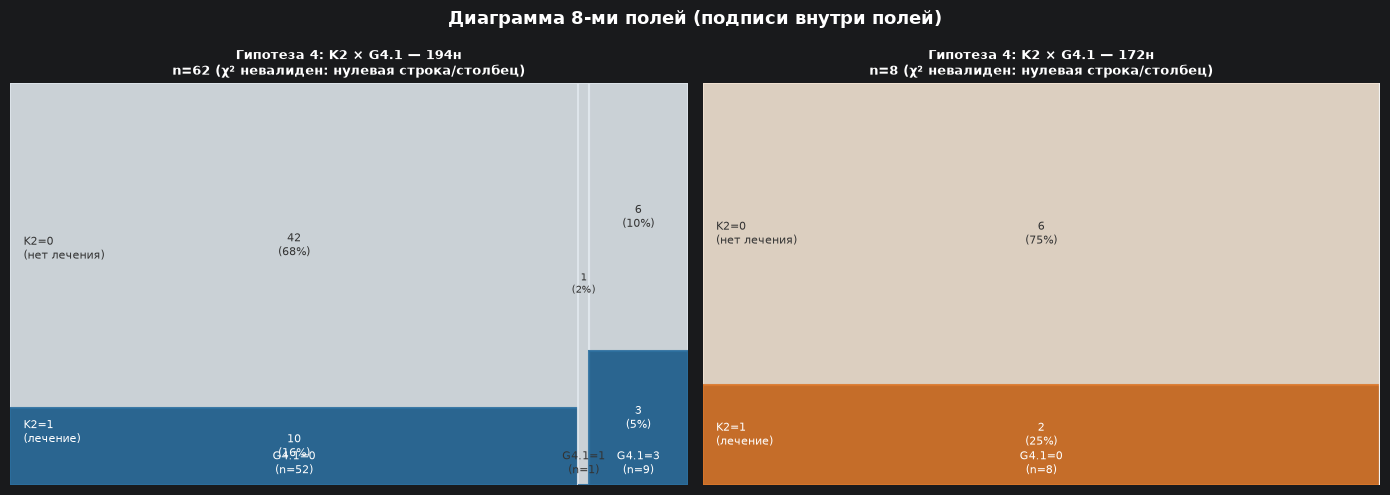

In [16]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, fisher_exact

PATH = "Таблица для визуализаций.xlsx"

MIN_AREA_LABEL = 0.012

def load(sheet):
    raw = pd.read_excel(PATH, sheet_name=sheet, header=None)
    d = raw.iloc[5:, 0:9].copy()
    d.columns = ["I1.6","I2.1","G3.1","G4.1","E1","E2","E3","H3","K2"]
    d = d[pd.to_numeric(d["I1.6"], errors="coerce").isin([0,1])]
    return d.apply(pd.to_numeric, errors="coerce")

t194 = load("194н")
t172 = load("172н")

SCHEME = {
    "194н": {"on": "#2c6e9e", "off": "#dfe6ec"},
    "172н": {"on": "#d9772b", "off": "#f3e4d3"},
}

def cell_label(ax, x, y, w, h, k, n, color="white", base_fs=8):
    if n == 0 or w <= 0 or h <= 0:
        return
    fs = base_fs
    if w * h < MIN_AREA_LABEL:
        fs = max(5, base_fs * np.sqrt(max(w * h, 1e-6) / MIN_AREA_LABEL))
    if w < 0.05 or h < 0.10:
        fs = max(5, fs - 1)
    ax.text(x, y, f"{k}\n({k/n*100:.0f}%)", ha="center", va="center",
            fontsize=fs, color=color)

def fourfold(ax, df, c1, c2, title, scheme):
    ct = pd.crosstab(df[c1].fillna(0).astype(int),
                     df[c2].fillna(0).astype(int))\
           .reindex(index=[0,1], columns=[0,1], fill_value=0)
    a, b = ct.loc[0,0], ct.loc[0,1]
    c, d = ct.loc[1,0], ct.loc[1,1]
    n = a + b + c + d
    denom = np.sqrt((a+b)*(c+d)*(a+c)*(b+d))
    phi = (a*d - b*c)/denom if denom > 0 else np.nan

    w0 = (a+c)/n if n else 0.5
    w1 = (b+d)/n if n else 0.5
    h_a = a/(a+c) if (a+c) else 0
    h_b = b/(b+d) if (b+d) else 0
    h_c = c/(a+c) if (a+c) else 0
    h_d = d/(b+d) if (b+d) else 0

    ON, OFF = scheme["on"], scheme["off"]
    # Рисуем 4 поля
    ax.add_patch(plt.Rectangle((0, 1-h_a), w0, h_a, color=ON,  alpha=0.9))
    ax.add_patch(plt.Rectangle((w0, 1-h_b), w1, h_b, color=OFF, alpha=0.9))
    ax.add_patch(plt.Rectangle((0, 0),      w0, h_c, color=OFF, alpha=0.9))
    ax.add_patch(plt.Rectangle((w0, 0),     w1, h_d, color=ON,  alpha=0.9))

    # --- Числа в центрах ячеек ---
    cell_label(ax, w0/2,     1-h_a/2, w0, h_a, a, n, color="#ffffff" if a/n > 0.1 else "#333")
    cell_label(ax, w0+w1/2,  1-h_b/2, w1, h_b, b, n, color="#ffffff" if b/n > 0.1 else "#333")
    cell_label(ax, w0/2,        h_c/2, w0, h_c, c, n, color="#ffffff" if c/n > 0.1 else "#333")
    cell_label(ax, w0+w1/2,     h_d/2, w1, h_d, d, n, color="#ffffff" if d/n > 0.1 else "#333")

    # --- Подписи осей ВНУТРИ конкретных полей ---
    # Y-подписи (c1=0/1):
    #   c1=0 в левой части верхних полей (a и b). Берем самый верхний из существующих.
    if h_a > 0 or h_b > 0:
        y_top = 1 - (h_a if h_a > 0 else h_b)/2
        color = "#333" if (h_a > 0 and a/n <= 0.1) or (h_a == 0 and b/n <= 0.1) else "#fff"
        ax.text(0.02, y_top, f"{c1}=0", ha="left", va="center", fontsize=8, color=color, transform=ax.transAxes)

    #   c1=1 в левой части нижних полей (c и d).
    if h_c > 0 or h_d > 0:
        y_bot = (h_c if h_c > 0 else h_d)/2
        color = "#333" if (h_c > 0 and c/n <= 0.1) or (h_c == 0 and d/n <= 0.1) else "#fff"
        ax.text(0.02, y_bot, f"{c1}=1", ha="left", va="center", fontsize=8, color=color, transform=ax.transAxes)

    # X-подписи (c2=0/1):
    #   c2=0 внизу левого столбца (a и c). Берем нижний центр.
    if w0 > 0:
        x_left = w0/2
        y_val = 0.02
        color = "#fff" if (h_c > 0 and c/n > 0.1) or (h_c == 0 and a/n > 0.1) else "#333"
        ax.text(x_left, y_val, f"{c2}=0", ha="center", va="bottom", fontsize=8, color=color, transform=ax.transAxes)

    #   c2=1 внизу правого столбца (b и d).
    if w1 > 0:
        x_right = w0 + w1/2
        y_val = 0.02
        color = "#fff" if (h_d > 0 and d/n > 0.1) or (h_d == 0 and b/n > 0.1) else "#333"
        ax.text(x_right, y_val, f"{c2}=1", ha="center", va="bottom", fontsize=8, color=color, transform=ax.transAxes)

    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.tick_params(length=0, labelbottom=False, labelleft=False)
    for s in ax.spines.values():
        s.set_visible(False)

    if n <= 10:
        _, p = fisher_exact([[a,b],[c,d]])
        sub = f"n={n}, Fisher p={p:.3f}"
    else:
        _, p, _, _ = chi2_contingency([[a,b],[c,d]])
        sub = f"n={n}, φ={phi:.2f}, p={p:.3f}"
    ax.set_title(f"{title}\n{sub}", fontsize=9, weight="bold")
    return phi, n

BOOL_HYP = {
    "1. ТП ↔ ПР после":        ("I2.1", "I1.6"),
    "2. Оценка вреда ↔ Гл.18": ("G3.1", "E1"),
    "3. Вред не устан. ↔ H3":  ("G3.1", "H3"),
    "4. Лечение ↔ Обращение":  ("K2",   "H3"),
}

fig, axes = plt.subplots(4, 2, figsize=(10, 4.4*4))
for i, (name, (c1, c2)) in enumerate(BOOL_HYP.items()):
    fourfold(axes[i,0], t194, c1, c2, f"{name} — 194н", SCHEME["194н"])
    fourfold(axes[i,1], t172, c1, c2, f"{name} — 172н", SCHEME["172н"])

fig.suptitle("Диаграммы 4-х полей (подписи внутри полей)",
             weight="bold", fontsize=13, y=1.005)
plt.tight_layout()
plt.savefig("fourfold_all_2colors.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.savefig("fourfold_all_2colors.pdf", bbox_inches="tight")
plt.show()


# ====== eightfold ======
def eightfold(ax, df, c1, c2, title, scheme, c2_vals=(0,1,2,3)):
    ct = pd.crosstab(df[c1].fillna(0).astype(int),
                     df[c2].fillna(0).astype(int))\
           .reindex(index=[0,1], columns=list(c2_vals), fill_value=0)
    n = int(ct.values.sum())
    if n == 0:
        ax.axis("off")
        ax.text(0.5, 0.5, f"{title}\n\nнет данных", ha="center", va="center",
                fontsize=9, color="#888")
        return ct, n

    col_sums = ct.sum(axis=0).values
    widths = col_sums / n
    heights = {}
    for j, v in enumerate(c2_vals):
        if col_sums[j] == 0:
            heights[v] = (0.0, 0.0)
        else:
            heights[v] = (ct.loc[0, v] / col_sums[j],
                          ct.loc[1, v] / col_sums[j])

    x = 0
    for j, v in enumerate(c2_vals):
        w = widths[j]
        h0, h1 = heights[v]
        if col_sums[j] > 0:
            ax.add_patch(plt.Rectangle((x, 1 - h0), w, h0,
                                       color=scheme["off"], alpha=0.9,
                                       edgecolor="white", linewidth=1.5))
            ax.add_patch(plt.Rectangle((x, 0), w, h1,
                                       color=scheme["on"], alpha=0.9,
                                       edgecolor="white", linewidth=1.5))
        else:
            ax.add_patch(plt.Rectangle((x, 0), w, 1.0,
                                       color="#f5f5f5", alpha=0.9,
                                       edgecolor="white", linewidth=1.5))

        k0 = ct.loc[0, v]; k1 = ct.loc[1, v]

        # --- Числа в центрах ячеек ---
        cell_label(ax, x + w/2, 1 - h0/2, w, h0, k0, n, color="#333")
        cell_label(ax, x + w/2, h1/2,     w, h1, k1, n, color="#ffffff")

        # Подпись категории G4.1 внизу столбца (внутри поля)
        if col_sums[j] > 0:
            color_cat = "#fff" if h1 > 0 else "#333"
            ax.text(x + w/2, 0.02, f"G4.1={v}\n(n={col_sums[j]})",
                    ha="center", va="bottom", fontsize=8, color=color_cat,
                    transform=ax.transAxes)
        x += w

    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.tick_params(length=0, labelbottom=False, labelleft=False)
    for s in ax.spines.values():
        s.set_visible(False)

    def y_center_row0():
        ys = []
        for j, v in enumerate(c2_vals):
            if col_sums[j] == 0: continue
            h0, _ = heights[v]
            if h0 > 0: ys.append(1 - h0/2)
        return float(np.mean(ys)) if ys else 0.5
    def y_center_row1():
        ys = []
        for j, v in enumerate(c2_vals):
            if col_sums[j] == 0: continue
            _, h1 = heights[v]
            if h1 > 0: ys.append(h1/2)
        return float(np.mean(ys)) if ys else 0.5

    ax.text(0.02, y_center_row0(), "K2=0\n(нет лечения)",
            ha="left", va="center", fontsize=8, color="#333",
            transform=ax.transAxes)
    ax.text(0.02, y_center_row1(), "K2=1\n(лечение)",
            ha="left", va="center", fontsize=8, color="#fff",
            transform=ax.transAxes)

    if n > 0 and (ct.values.sum(axis=0) > 0).all() and (ct.values.sum(axis=1) > 0).all():
        try:
            chi2, p, _, _ = chi2_contingency(ct.values)
            cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
            sub = f"n={n}, χ² p={p:.3f}, V={cramers_v:.2f}"
        except ValueError:
            sub = f"n={n} (χ² невалиден: нулевая клетка)"
    else:
        sub = f"n={n} (χ² невалиден: нулевая строка/столбец)"
    ax.set_title(f"{title}\n{sub}", fontsize=9, weight="bold")
    return ct, n

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ct194, n194 = eightfold(axes[0], t194, "K2", "G4.1",
                        "Гипотеза 4: K2 × G4.1 — 194н", SCHEME["194н"])
ct172, n172 = eightfold(axes[1], t172, "K2", "G4.1",
                        "Гипотеза 4: K2 × G4.1 — 172н", SCHEME["172н"])

fig.suptitle("Диаграмма 8-ми полей (подписи внутри полей)",
             weight="bold", fontsize=13)
plt.tight_layout()
plt.savefig("eightfold_K2_G41.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.savefig("eightfold_K2_G41.pdf", bbox_inches="tight")
plt.show()

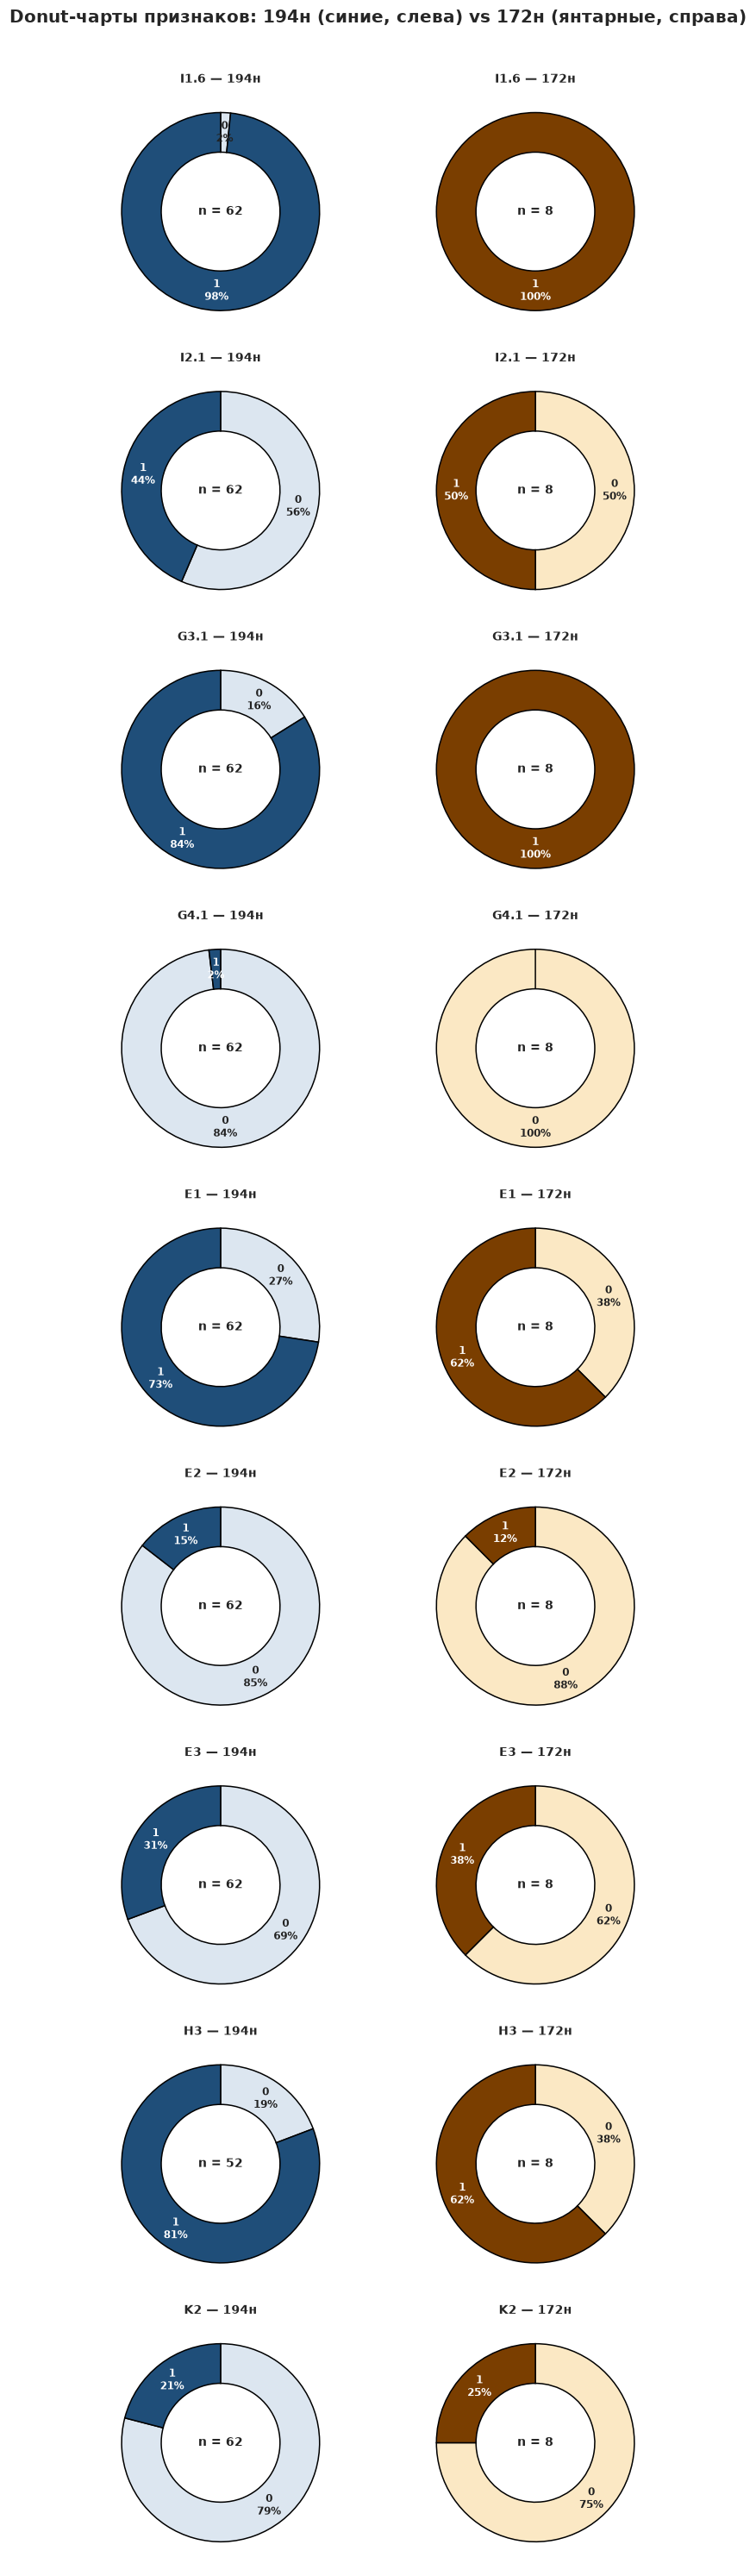

In [26]:
# ============================================================
# DONUT-ЧАРТЫ по каждому признаку: 194н и 172н попарно
# ============================================================
BINARY_COLS = ["I1.6", "I2.1", "G3.1", "G4.1", "E1", "E2", "E3", "H3", "K2"]

def donut(ax, series, title, scheme):
    """Круговая диаграмма с пустым центром: 0 и 1."""
    vals = series.dropna().astype(int)
    n = len(vals)
    if n == 0:
        ax.axis("off")
        ax.text(0.5, 0.5, f"{title}\nнет данных", ha="center", va="center",
                fontsize=9, color="#666")
        return

    counts = vals.value_counts().reindex([0, 1], fill_value=0)
    sizes = counts.values.astype(float)
    colors = [scheme["off"], scheme["on"]]
    labels = ["0", "1"]

    wedges, _ = ax.pie(
        sizes, colors=colors, startangle=90, counterclock=False,
        wedgeprops=dict(width=0.40, edgecolor="black", linewidth=1.0),
        labels=None,
    )

    for w, lab, k in zip(wedges, labels, sizes):
        if k == 0:
            continue
        ang = (w.theta2 + w.theta1) / 2.0
        x = np.cos(np.deg2rad(ang)) * 0.80
        y = np.sin(np.deg2rad(ang)) * 0.80
        pct = k / n * 100
        ax.text(x, y, f"{lab}\n{pct:.0f}%", ha="center", va="center",
                fontsize=8, color="#fff" if lab == "1" else "#222",
                fontweight="bold")

    ax.text(0, 0, f"n = {n}", ha="center", va="center",
            fontsize=9, fontweight="bold", color="#222")
    ax.set_title(title, fontsize=9, weight="bold", pad=4)
    ax.set_aspect("equal")


# --- Попарная сетка: 9 строк × 2 столбца ---
n_cols = len(BINARY_COLS)
fig, axes = plt.subplots(n_cols, 2, figsize=(7.5, 3.0 * n_cols))

for i, col in enumerate(BINARY_COLS):
    donut(axes[i, 0], t194[col], f"{col} — 194н", SCHEME["194н"])
    donut(axes[i, 1], t172[col], f"{col} — 172н", SCHEME["172н"])

fig.suptitle(
    "Donut-чарты признаков: 194н (синие, слева) vs 172н (янтарные, справа)",
    weight="bold", fontsize=13, y=1.005
)
plt.tight_layout()
plt.savefig("donut_paired.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.savefig("donut_paired.pdf", bbox_inches="tight", facecolor="white")
plt.show()

C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\224701905.py:180: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((x, 1-h0), w, h0,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\224701905.py:183: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((x, 0), w, h1,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\224701905.py:180: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((x, 1-h0), w, h0,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\224701905.py:183: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((x, 0), w, h1,
C:\Users\daniil\AppData\Local\Temp\ipykernel_9964\224701905.py:180: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rect

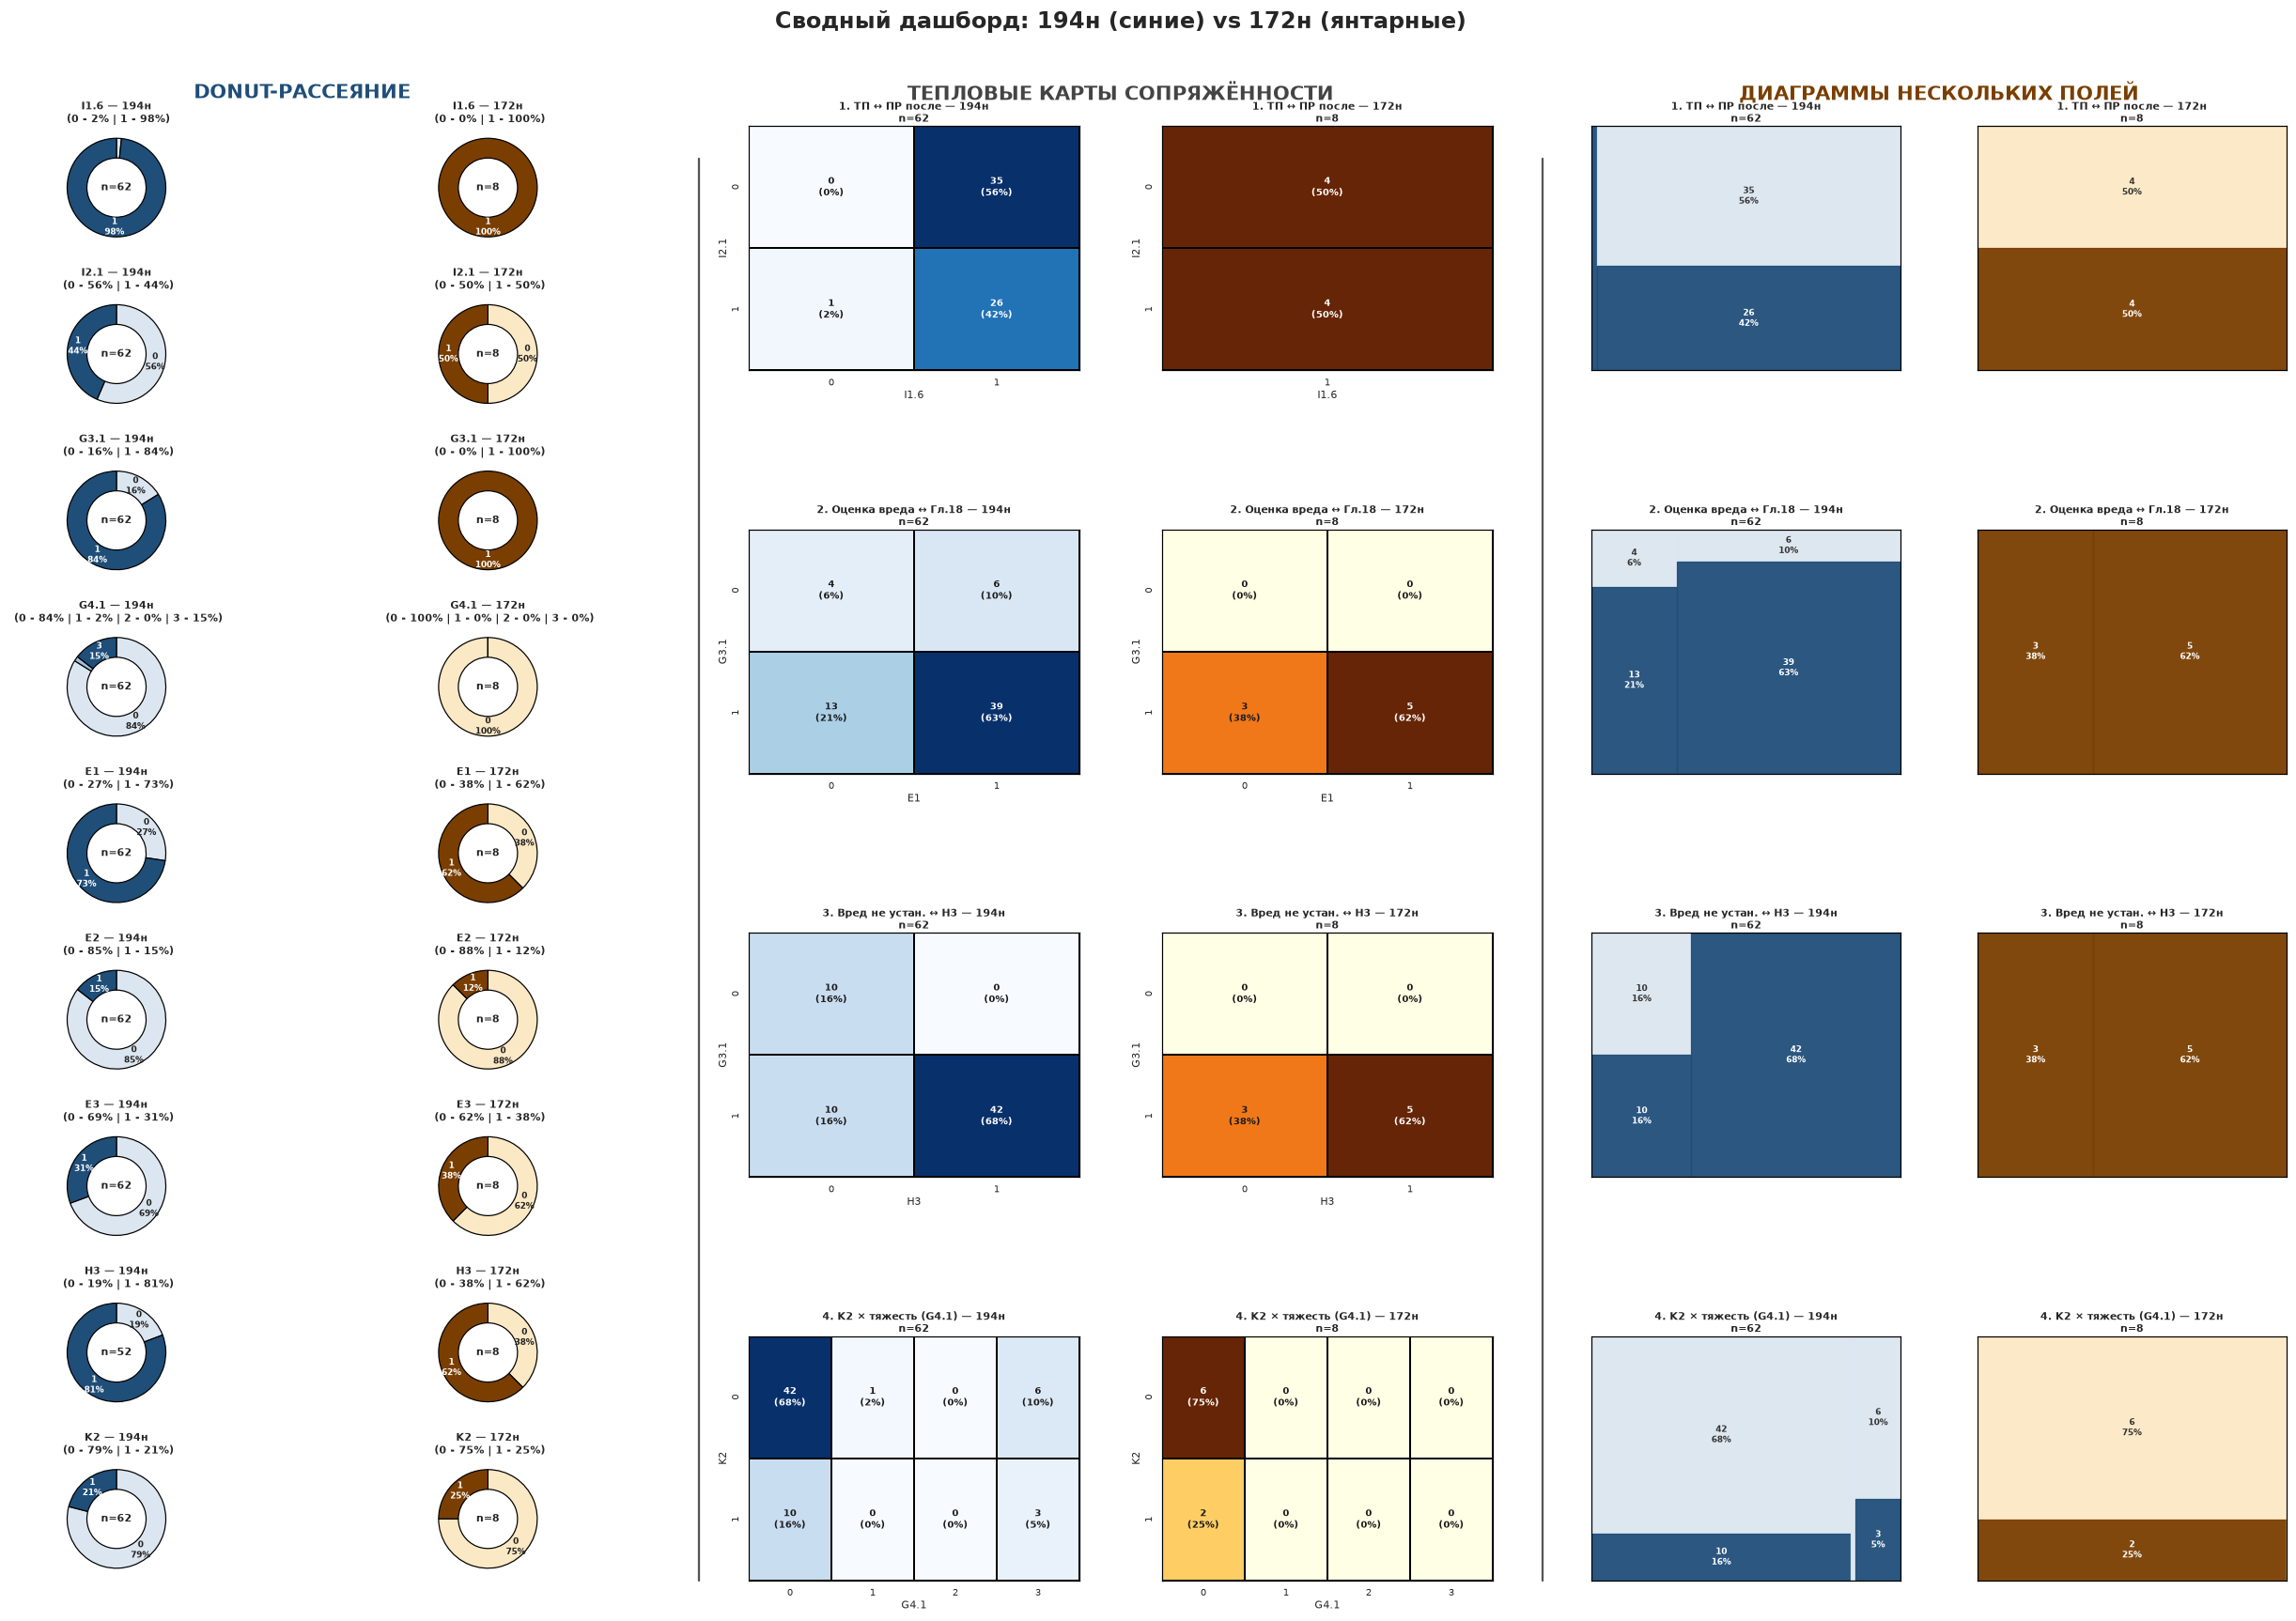

In [36]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from scipy.stats import chi2_contingency, fisher_exact

# ============================================================
# ОБЩИЙ СТИЛЬ
# ============================================================
sns.set_theme(style="whitegrid", rc={
    "grid.color": "#000000", "grid.linestyle": "-", "grid.linewidth": 0.5,
    "axes.edgecolor": "#000000", "axes.linewidth": 0.8,
})
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["axes.titlesize"] = 9
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 8
plt.rcParams["xtick.labelsize"] = 7
plt.rcParams["ytick.labelsize"] = 7
plt.rcParams["font.family"] = "DejaVu Sans"

PATH = "Таблица для визуализаций.xlsx"

def load(sheet):
    raw = pd.read_excel(PATH, sheet_name=sheet, header=None)
    d = raw.iloc[5:, 0:9].copy()
    d.columns = ["I1.6","I2.1","G3.1","G4.1","E1","E2","E3","H3","K2"]
    d = d[pd.to_numeric(d["I1.6"], errors="coerce").isin([0,1])]
    return d.apply(pd.to_numeric, errors="coerce")

t194 = load("194н")
t172 = load("172н")

SCHEME = {
    "194н": {
        "cmap": "Blues",
        "colors_bin":  ["#dce6f0", "#1f4e79"],
        "colors_g41":  ["#dce6f0", "#9dc0db", "#4a86b8", "#1f4e79"],
        "text_bin":    ["#222", "#fff"],
        "text_g41":    ["#222", "#222", "#fff", "#fff"],
        "on":  "#1f4e79", "off": "#dce6f0",
    },
    "172н": {
        "cmap": "YlOrBr",
        "colors_bin":  ["#fbe8c4", "#7a3e00"],
        "colors_g41":  ["#fbe8c4", "#e3b46a", "#b9722e", "#7a3e00"],
        "text_bin":    ["#222", "#fff"],
        "text_g41":    ["#222", "#222", "#fff", "#fff"],
        "on":  "#7a3e00", "off": "#fbe8c4",
    },
}

BINARY_COLS = ["I1.6","I2.1","G3.1","G4.1","E1","E2","E3","H3","K2"]
BOOL_HYP = {
    "1. ТП ↔ ПР после":        ("I2.1", "I1.6"),
    "2. Оценка вреда ↔ Гл.18": ("G3.1", "E1"),
    "3. Вред не устан. ↔ H3":  ("G3.1", "H3"),
    "4. Лечение ↔ Обращение":  ("K2",   "H3"),
}
HYP4 = ("K2", "G4.1")

# ============================================================
# 1) DONUT
# ============================================================
def donut(ax, series, title, scheme, categories, colors, text_colors):
    vals = series.dropna().astype(int)
    n = len(vals)
    if n == 0:
        ax.axis("off")
        ax.text(0.5, 0.5, "нет данных", ha="center", va="center",
                fontsize=8, color="#666")
        return

    counts = vals.value_counts().reindex(categories, fill_value=0)
    sizes = counts.values.astype(float)

    summary_parts = []
    for cat in categories:
        k = counts[cat]
        pct = int(round(k / n * 100))
        summary_parts.append(f"{cat} - {pct}%")
    summary_str = " (" + " | ".join(summary_parts) + ")"

    wedges, _ = ax.pie(
        sizes, colors=colors, startangle=90, counterclock=False,
        wedgeprops=dict(width=0.40, edgecolor="black", linewidth=0.8),
        labels=None,
    )

    for w, lab, k, tc in zip(wedges, categories, sizes, text_colors):
        if k == 0:
            continue
        pct = k / n * 100
        if pct < 5.0:
            continue
        ang = (w.theta2 + w.theta1) / 2.0
        x = np.cos(np.deg2rad(ang)) * 0.80
        y = np.sin(np.deg2rad(ang)) * 0.80
        ax.text(x, y, f"{lab}\n{pct:.0f}%", ha="center", va="center",
                fontsize=6, color=tc, fontweight="bold")

    ax.text(0, 0, f"n={n}", ha="center", va="center",
            fontsize=7, fontweight="bold", color="#222")

    ax.set_title(f"{title}\n{summary_str}", fontsize=7, weight="bold", pad=2)
    ax.set_aspect("equal")

# ============================================================
# 2) HEATMAP
# ============================================================
def ct_heat(ax, df, c1, c2, title, scheme, values=None):
    ct = pd.crosstab(df[c1].fillna(0).astype(int),
                     df[c2].fillna(0).astype(int))
    if values is not None:
        ct = ct.reindex(columns=values, fill_value=0)
    ct = ct.reindex(index=[0, 1], fill_value=0)
    n = int(ct.values.sum())
    counts = ct.values.astype(float)
    mat = counts
    vmax = counts.max() if counts.max() > 0 else 1.0
    annot = (ct.astype(int).astype(str)
             + "\n(" + (counts / max(n, 1) * 100).round(0).astype(int).astype(str) + "%)")
    sns.heatmap(mat, annot=annot, fmt="", cmap=scheme["cmap"],
                vmin=0, vmax=vmax, cbar=False, ax=ax,
                annot_kws={"fontsize": 6.5, "fontweight": "bold"},
                linewidths=1.0, linecolor="black",
                xticklabels=[str(v) for v in ct.columns],
                yticklabels=["0", "1"])
    cmap = plt.get_cmap(scheme["cmap"])
    norm = Normalize(vmin=0, vmax=vmax)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            rgba = cmap(norm(mat[i, j]))
            lum = 0.2126*rgba[0] + 0.7152*rgba[1] + 0.0722*rgba[2]
            color = "#ffffff" if lum < 0.5 else "#1a1a1a"
            for text in ax.texts:
                if text.get_position() == (j + 0.5, i + 0.5):
                    text.set_color(color); break
    ax.set_title(f"{title}\nn={n}", fontsize=7, weight="bold", pad=3)
    ax.set_xlabel(c2, fontsize=7, labelpad=2)
    ax.set_ylabel(c1, fontsize=7, labelpad=2)
    ax.tick_params(labelsize=6.5, length=2)
    for s in ax.spines.values():
        s.set_visible(True); s.set_linewidth(0.8); s.set_color("#000000")
    ax.set_axisbelow(True)
    ax.grid(True, color="#000000", linewidth=0.4, alpha=0.7)

# ============================================================
# 3) MOSAIC
# ============================================================
def mosaic(ax, df, c1, c2, title, scheme, values=None):
    ct = pd.crosstab(df[c1].fillna(0).astype(int),
                     df[c2].fillna(0).astype(int))
    if values is not None:
        ct = ct.reindex(columns=values, fill_value=0)
    ct = ct.reindex(index=[0, 1], fill_value=0)
    n = int(ct.values.sum())
    if n == 0:
        ax.axis("off")
        ax.text(0.5, 0.5, "нет данных", ha="center", va="center",
                fontsize=7, color="#666")
        return
    col_sums = ct.sum(axis=0).values.astype(float)
    widths = col_sums / n
    heights = {}
    for j, v in enumerate(ct.columns):
        if col_sums[j] == 0:
            heights[v] = (0.0, 0.0)
        else:
            heights[v] = (ct.loc[0, v] / col_sums[j],
                          ct.loc[1, v] / col_sums[j])
    x = 0
    for j, v in enumerate(ct.columns):
        w = widths[j]; h0, h1 = heights[v]
        if col_sums[j] > 0:
            ax.add_patch(Rectangle((x, 1-h0), w, h0,
                                   color=scheme["off"], alpha=0.95,
                                   edgecolor="black", linewidth=0.8))
            ax.add_patch(Rectangle((x, 0), w, h1,
                                   color=scheme["on"], alpha=0.95,
                                   edgecolor="black", linewidth=0.8))
        else:
            ax.add_patch(Rectangle((x, 0), w, 1.0,
                                   color="#f5f5f5", alpha=0.9,
                                   edgecolor="black", linewidth=0.8))
        k0 = ct.loc[0, v]; k1 = ct.loc[1, v]
        if k0 > 0 and w > 0.04 and h0 > 0.10:
            ax.text(x + w/2, 1-h0/2, f"{k0}\n{k0/n*100:.0f}%",
                    ha="center", va="center", fontsize=6,
                    color="#333", weight="bold")
        if k1 > 0 and w > 0.04 and h1 > 0.10:
            ax.text(x + w/2, h1/2, f"{k1}\n{k1/n*100:.0f}%",
                    ha="center", va="center", fontsize=6,
                    color="#fff", weight="bold")
        x += w
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.tick_params(length=0, labelbottom=False, labelleft=False)
    ax.set_title(f"{title}\nn={n}", fontsize=7, weight="bold", pad=3)
    for s in ax.spines.values():
        s.set_visible(True); s.set_linewidth(0.8); s.set_color("#000000")

# ============================================================
# DASHBOARD 3 колонки
# ============================================================
fig = plt.figure(figsize=(24, 16))

# Создаем 3 независимые области: левая (доны), средняя (heatmap), правая (мозаики)
# Левая колонка
gs_left = gridspec.GridSpec(
    1, 1, figure=fig, left=0.03, right=0.31, bottom=0.03, top=0.91, wspace=0, hspace=0
)
gs_left_inner = gridspec.GridSpecFromSubplotSpec(
    len(BINARY_COLS), 2, subplot_spec=gs_left[0, 0], hspace=0.35, wspace=0.15
)
# Средняя колонка
gs_mid = gridspec.GridSpec(
    1, 1, figure=fig, left=0.35, right=0.65, bottom=0.03, top=0.91, wspace=0, hspace=0
)
gs_mid_inner = gridspec.GridSpecFromSubplotSpec(
    len(heat_items) if 'heat_items' in locals() else 4, 2, subplot_spec=gs_mid[0, 0], hspace=0.65, wspace=0.25
)
# Правая колонка
gs_right = gridspec.GridSpec(
    1, 1, figure=fig, left=0.69, right=0.97, bottom=0.03, top=0.91, wspace=0, hspace=0
)
gs_right_inner = gridspec.GridSpecFromSubplotSpec(
    len(heat_items) if 'heat_items' in locals() else 4, 2, subplot_spec=gs_right[0, 0], hspace=0.65, wspace=0.25
)

# --- Колонка 1: donuts ---
for i, col in enumerate(BINARY_COLS):
    if col == "G4.1":
        cats = [0, 1, 2, 3]
        ax_l = fig.add_subplot(gs_left_inner[i, 0])
        ax_r = fig.add_subplot(gs_left_inner[i, 1])
        donut(ax_l, t194[col], f"{col} — 194н", SCHEME["194н"],
              cats, SCHEME["194н"]["colors_g41"], SCHEME["194н"]["text_g41"])
        donut(ax_r, t172[col], f"{col} — 172н", SCHEME["172н"],
              cats, SCHEME["172н"]["colors_g41"], SCHEME["172н"]["text_g41"])
    else:
        cats = [0, 1]
        ax_l = fig.add_subplot(gs_left_inner[i, 0])
        ax_r = fig.add_subplot(gs_left_inner[i, 1])
        donut(ax_l, t194[col], f"{col} — 194н", SCHEME["194н"],
              cats, SCHEME["194н"]["colors_bin"], SCHEME["194н"]["text_bin"])
        donut(ax_r, t172[col], f"{col} — 172н", SCHEME["172н"],
              cats, SCHEME["172н"]["colors_bin"], SCHEME["172н"]["text_bin"])

# --- Колонка 2: heatmaps ---
heat_items = [
    ("1. ТП ↔ ПР после",        BOOL_HYP["1. ТП ↔ ПР после"],        None),
    ("2. Оценка вреда ↔ Гл.18", BOOL_HYP["2. Оценка вреда ↔ Гл.18"], None),
    ("3. Вред не устан. ↔ H3",  BOOL_HYP["3. Вред не устан. ↔ H3"],  None),
    ("4. K2 × тяжесть (G4.1)",  HYP4,                                 [0,1,2,3]),
]
for i, (name, (c1, c2), vals) in enumerate(heat_items):
    ax_l = fig.add_subplot(gs_mid_inner[i, 0])
    ax_r = fig.add_subplot(gs_mid_inner[i, 1])
    ct_heat(ax_l, t194, c1, c2, f"{name} — 194н", SCHEME["194н"], vals)
    ct_heat(ax_r, t172, c1, c2, f"{name} — 172н", SCHEME["172н"], vals)

# --- Колонка 3: мозаики ---
for i, (name, (c1, c2), vals) in enumerate(heat_items):
    ax_l = fig.add_subplot(gs_right_inner[i, 0])
    ax_r = fig.add_subplot(gs_right_inner[i, 1])
    mosaic(ax_l, t194, c1, c2, f"{name} — 194н", SCHEME["194н"], vals)
    mosaic(ax_r, t172, c1, c2, f"{name} — 172н", SCHEME["172н"], vals)

# ------------------------------------------------------------
# РАЗДЕЛИТЕЛЬНЫЕ ЛИНИИ И ЗАГОЛОВКИ
# ------------------------------------------------------------
# Берем координаты границ между колонками
# Границы: левая колонка до 0.31, средняя с 0.35 до 0.65, правая с 0.69.
# Линии ставим ровно посередине между колонками:
x_line_1 = (0.31 + 0.35) / 2  # 0.33
x_line_2 = (0.65 + 0.69) / 2  # 0.67

# Линии-разделители: от y=0.03 до y=0.89 (чтобы не перекрывать заголовки)
fig.add_artist(Line2D([x_line_1, x_line_1], [0.03, 0.89],
                      color='#555555', linewidth=1.5, transform=fig.transFigure))
fig.add_artist(Line2D([x_line_2, x_line_2], [0.03, 0.89],
                      color='#555555', linewidth=1.5, transform=fig.transFigure))

# Центры колонок
x_center_1 = (0.03 + 0.31) / 2  # 0.17
x_center_2 = (0.35 + 0.65) / 2  # 0.50
x_center_3 = (0.69 + 0.97) / 2  # 0.83

# Заголовки колонок
fig.text(x_center_1, 0.93, "DONUT-РАССЕЯНИЕ", ha="center", va="center",
         fontsize=14, weight="bold", color="#1f4e79")
fig.text(x_center_2, 0.93, "ТЕПЛОВЫЕ КАРТЫ СОПРЯЖЁННОСТИ", ha="center", va="center",
         fontsize=14, weight="bold", color="#444")
fig.text(x_center_3, 0.93, "ДИАГРАММЫ НЕСКОЛЬКИХ ПОЛЕЙ", ha="center", va="center",
         fontsize=14, weight="bold", color="#7a3e00")

# Общий заголовок дашборда
fig.suptitle("Сводный дашборд: 194н (синие) vs 172н (янтарные)",
             weight="bold", fontsize=16, y=0.98)

# --- Сохранение и показ ---
plt.savefig("dashboard_3cols.png", dpi=180, bbox_inches="tight", facecolor="white")
plt.savefig("dashboard_3cols.pdf", bbox_inches="tight", facecolor="white")
plt.show()